# Predicción de temperaturas con Redes Neuronales Recurrentes

## Forecasting de temperatura mínima diaria mediante GRU, LSTM y arquitecturas híbridas Conv1D

Este proyecto aborda la predicción de la **temperatura mínima diaria en Melbourne** mediante redes neuronales recurrentes aplicadas a series temporales.

El trabajo parte de un modelo recurrente GRU sobre la serie univariante y evoluciona hacia un problema de **predicción multivariante y multi-step**, incorporando variables temporales y estadísticas derivadas de la serie.

Se comparan siete arquitecturas:

- GRU base.
- Conv1D + LSTM.
- Conv1D + GRU.
- Conv1D + GRU residual.
- Conv1D + LSTM residual.
- Dos ramas con unión ponderada.
- Dos ramas ampliadas con unión ponderada.

En la comparación final se analizan tanto las métricas globales como el error específico en los horizontes `t+1`, `t+2` y `t+3`.

## 1. Configuración inicial y funciones auxiliares

En este bloque se centralizan la configuración del entorno, las medidas de reproducibilidad, las rutas del proyecto y las funciones reutilizables empleadas posteriormente para preparar los datos, entrenar y evaluar los modelos y generar las principales visualizaciones.

### 1.1. Librerías y reproducibilidad

In [1]:
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import numpy as np
import pandas as pd

from IPython.display import display
from pathlib import Path
from time import perf_counter

2026-10-04 13:36:32.833357: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-04 13:36:33.403623: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-10-04 13:36:35.541114: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
import random

semilla = 12345

random.seed(semilla)
np.random.seed(semilla)
tf.random.set_seed(semilla)
keras.utils.set_random_seed(semilla)

Se fija una semilla aleatoria para mejorar la reproducibilidad del experimento. De esta forma se controlan, en la medida de lo posible, la inicialización de los pesos y las fuentes de aleatoriedad utilizadas durante el entrenamiento.

La misma semilla se restablece antes de construir cada arquitectura para favorecer comparaciones más consistentes. Aun así, determinadas operaciones ejecutadas sobre GPU pueden introducir pequeñas variaciones numéricas entre ejecuciones, por lo que la reproducibilidad no debe interpretarse como identidad absoluta de todos los resultados.


### 1.2. Configuración del proyecto

En este bloque se centralizan las rutas utilizadas por el notebook, las etiquetas empleadas para presentar las arquitecturas, las estructuras destinadas a almacenar los resultados y los parámetros temporales comunes de los dos problemas de predicción.

#### 1.2.1. Rutas y directorios

In [3]:
# Rutas del proyecto
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == 'notebooks':
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

MODELS_DIR = PROJECT_DIR / 'models'
IMAGES_DIR = PROJECT_DIR / 'images'
OUTPUTS_DIR = PROJECT_DIR / 'outputs'

MODELS_DIR.mkdir(parents=True, exist_ok=True)
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

print('Proyecto:', PROJECT_DIR)
print('Modelos:', MODELS_DIR)
print('Imágenes:', IMAGES_DIR)
print('Outputs:', OUTPUTS_DIR)

Proyecto: /mnt/c/Portfolio/RNN/02_WORKING
Modelos: /mnt/c/Portfolio/RNN/02_WORKING/models
Imágenes: /mnt/c/Portfolio/RNN/02_WORKING/images
Outputs: /mnt/c/Portfolio/RNN/02_WORKING/outputs


#### 1.2.2. Etiquetas y almacenamiento de resultados

Los modelos mantienen identificadores internos estables para facilitar su uso programático, mientras que las tablas y visualizaciones utilizan etiquetas más legibles.

También se inicializan los contenedores comunes en los que se almacenarán los historiales de entrenamiento, métricas, modelos y predicciones obtenidos durante la ejecución.

In [4]:
# Modelos
REFERENCE_MODEL = 'modelo_gru_univariante'

MULTIVARIATE_MODELS = [
    'modelo_gru',
    'modelo_conv_lstm',
    'modelo_conv_gru',
    'modelo_residual_gru',
    'modelo_residual_lstm',
    'modelo_dos_ramas',
    'modelo_dos_ramas_ampliado'
]

# Etiquetas de los modelos
MODEL_LABELS = {
    'modelo_gru_univariante': 'GRU univariante',
    'modelo_gru': 'GRU',
    'modelo_conv_lstm': 'Conv1D + LSTM',
    'modelo_conv_gru': 'Conv1D + GRU',
    'modelo_residual_gru': 'Conv1D + GRU residual',
    'modelo_residual_lstm': 'Conv1D + LSTM residual',
    'modelo_dos_ramas': 'Dos ramas · serie + derivadas',
    'modelo_dos_ramas_ampliado': 'Dos ramas ampliadas · serie + derivadas'
}

# Etiquetas gráficas de los modelos
PLOT_LABELS = MODEL_LABELS.copy()

PLOT_LABELS.update({
    'modelo_residual_gru': 'Conv1D + GRU\nresidual',
    'modelo_residual_lstm': 'Conv1D + LSTM\nresidual',
    'modelo_dos_ramas': 'Dos ramas\nSerie + derivadas',
    'modelo_dos_ramas_ampliado': 'Dos ramas ampliadas\nSerie + derivadas'
})

# Diccionarios de resultados
histories = {}
trained_models = {}
predictions = {}

global_results = {}
validation_results = {}
step_results = {}

training_times = {}

#### 1.2.3. Configuración temporal de los problemas

Los parámetros temporales utilizados por las dos formulaciones se centralizan para evitar valores duplicados a lo largo del notebook.

También se define `t+2` como horizonte común de comparación, ya que es el objetivo del modelo univariante y forma parte de la predicción multi-step.

In [5]:
# Modelo univariante de referencia
past_ref = 5
horizon_ref = 2

# Problema multivariante
past = 14
future = 3

# Comparación visual
comparison_step = horizon_ref
n_predictions = 8

### 1.3. Funciones auxiliares

Las operaciones reutilizables del proyecto se centralizan en funciones auxiliares para evitar duplicidad de código y mantener un flujo de trabajo homogéneo.

Se distinguen tres grupos:

- preparación de ventanas temporales;
- entrenamiento, evaluación y agregación de resultados;
- visualización.

#### 1.3.1. Preparación de datos

Se definen dos funciones para transformar las series temporales en ventanas compatibles con los modelos de Deep Learning.

La primera función construye el problema univariante utilizado como referencia inicial. La segunda adapta el mismo principio al escenario multivariante y genera simultáneamente los objetivos correspondientes a `t+1`, `t+2` y `t+3`.

En ambos casos se mantiene el orden temporal de las observaciones y la mezcla de las ventanas queda desactivada durante su construcción.

In [6]:
def create_windows_np(data, window_size, horizon, shuffle=False):
    """
    Construye ventanas temporales para un problema univariante de forecasting.
    """
    X, y = [], []

    for i in range(len(data) - window_size - horizon + 1):
        X.append(data[i: i + window_size])
        y.append(data[i + window_size + horizon - 1])

    X, y = np.array(X), np.array(y)

    if shuffle:
        indices = np.arange(len(X))
        np.random.shuffle(indices)
        X, y = X[indices], y[indices]

    return X, y


def create_windows_multivariate_np(data, window_size, future, target_col_idx, shuffle=False):
    """
    Construye ventanas temporales multivariantes para predicción multi-step.
    """
    if isinstance(data, pd.DataFrame):
        data = data.values

    X, y = [], []

    for i in range(len(data) - window_size - future + 1):
        X.append(data[i:i + window_size, :])
        y.append(data[i + window_size:i + window_size + future, target_col_idx])

    X, y = np.array(X), np.array(y)

    if shuffle:
        indices = np.arange(len(X))
        np.random.shuffle(indices)

        X, y = X[indices], y[indices]

    return X, y

#### 1.3.2. Entrenamiento y evaluación

Se centralizan las operaciones comunes utilizadas durante el entrenamiento y la evaluación de las distintas arquitecturas.

Las funciones permiten generar los callbacks, almacenar los historiales de entrenamiento, recuperar las métricas correspondientes al mejor checkpoint, evaluar cada modelo sobre el conjunto de test y calcular de forma independiente el error para `t+1`, `t+2` y `t+3`.

También se incluyen funciones para construir las tablas comparativas y recuperar automáticamente la arquitectura seleccionada mediante el `MAE` de validación.

Los tiempos corresponden a una única ejecución en el mismo entorno de cálculo y se utilizan únicamente como referencia relativa del coste de entrenamiento.

De esta forma, todos los experimentos utilizan un procedimiento común de registro y evaluación y se evita repetir la misma lógica en cada modelo.

In [7]:
def crear_callbacks(model_name):
    """
    Crea los callbacks comunes utilizados durante el entrenamiento.

    El checkpoint, EarlyStopping y ReduceLROnPlateau monitorizan `val_loss`.
    Los mejores pesos de cada arquitectura se almacenan en la carpeta de modelos del proyecto.
    """
    path_checkpoint = str(MODELS_DIR / f'model_checkpoint_{model_name}.weights.h5')

    modelckpt_callback = keras.callbacks.ModelCheckpoint(
        monitor="val_loss",
        filepath=path_checkpoint,
        verbose=0,
        save_weights_only=True,
        save_best_only=True
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-5
    )

    es_callback = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        min_delta=0,
        patience=10,
        restore_best_weights=True
    )

    callbacks = [es_callback, reduce_lr, modelckpt_callback]

    return callbacks, path_checkpoint


def train_model(model, model_name, X_train, y_train, X_val, y_val, batch_size=32, epochs=200):
    """
    Ejecuta el entrenamiento común de una arquitectura, registra su history,
    métricas de validación y tiempo.
    """
    callbacks, checkpoint_path = crear_callbacks(model_name)

    print(f'\nEntrenando · {MODEL_LABELS[model_name]}')

    start_time = perf_counter()

    history = model.fit(
        X_train,
        y_train,
        epochs=epochs,
        validation_data=(X_val, y_val),
        shuffle=True,
        batch_size=batch_size,
        verbose=1,
        callbacks=callbacks
    )

    training_times[model_name] = (perf_counter() - start_time)

    histories[model_name] = history

    guardar_metricas_validacion(model_name, history)

    best_epoch = validation_results[model_name]['best_epoch']
    checkpoint_val_mae = validation_results[model_name]['val_mae']

    print(f'\nEntrenamiento finalizado · {MODEL_LABELS[model_name]}')
    print('Épocas ejecutadas:', len(history.history['loss']))
    print('Mejor época según val_loss:', best_epoch)
    print(f'MAE de validación en el checkpoint: {checkpoint_val_mae:.4f}')
    print(f'Tiempo de entrenamiento: {training_times[model_name]:.2f} s')

    return history, checkpoint_path


def guardar_metricas_validacion(model_name, history):
    """
    Registra las métricas de validación correspondientes a la época con menor `val_loss`.
    """
    best_epoch = np.argmin(history.history['val_loss'])

    validation_results[model_name] = {
        'val_mse': history.history['val_loss'][best_epoch],
        'val_rmse': history.history['val_rmse'][best_epoch],
        'val_mae': history.history['val_mae'][best_epoch],
        'best_epoch': best_epoch + 1
    }


def evaluar_modelo(model, model_name, path_checkpoint, X_test, y_test):
    """
    Recupera los mejores pesos de una arquitectura y evalúa el modelo sobre el conjunto de test
    mediante MSE, RMSE y MAE.
    """
    model.load_weights(path_checkpoint)

    results = model.evaluate(X_test, y_test, verbose=0)

    print(model_name)
    print('Test MSE:', results[0])
    print('Test RMSE:', results[1])
    print('Test MAE:', results[2])
    print()

    global_results[model_name] = {
        'test_mse': results[0],
        'test_rmse': results[1],
        'test_mae': results[2]
    }

    trained_models[model_name] = model

    return results


def crear_tabla_predicciones(model_name, y_true, past_steps):
    """
    Construye una tabla con fechas, valores reales, predicciones
    y error absoluto para cada horizonte de predicción.
    """
    y_pred = np.asarray(predictions[model_name])
    y_true = np.asarray(y_true)

    if y_true.ndim == 1:
        y_true = y_true.reshape(-1, 1)

    if y_pred.ndim == 1:
        y_pred = y_pred.reshape(-1, 1)

    n_outputs = y_true.shape[1]

    if n_outputs == 1:
        steps = [horizon_ref]

    else:
        steps = list(range(1, n_outputs + 1))

    filas = []

    for idx in range(len(y_true)):
        fila = {
            'model': model_name,
            'sample': idx + 1,
            'start_date': test_dates.iloc[idx]
        }

        for output_idx, step in enumerate(steps):
            target_date = test_dates.iloc[idx + past_steps + step - 1]

            valor_real = y_true[idx, output_idx]

            valor_pred = y_pred[idx, output_idx]

            fila[f'date_t{step}'] = target_date
            fila[f'real_t{step}'] = valor_real
            fila[f'pred_t{step}'] = valor_pred
            fila[f'abs_error_t{step}'] = abs(valor_real - valor_pred)

        filas.append(fila)

    tabla_prediccion = pd.DataFrame(filas)

    return tabla_prediccion


def evaluar_steps(model, model_name, X_test, y_test, horizon=None):
    """
    Calcula MSE, RMSE y MAE de forma independiente para cada step de predicción
    y almacena las predicciones generadas.
    """
    y_pred = np.asarray(model.predict(X_test, verbose=0))

    y_true = np.asarray(y_test)

    # Formato común [samples, futures]
    if y_true.ndim == 1:
        y_true = y_true.reshape(-1, 1)

    if y_pred.ndim == 1:
        y_pred = y_pred.reshape(-1, 1)

    n_outputs = y_true.shape[1]

    # En un problema univariante con una sola salida, future representa la distancia al objetivo.
    if n_outputs == 1:
        if horizon is None:
            raise ValueError('Debe indicarse horizon para una salida única.')

        etiquetas_step = [f't+{horizon}']

    else:
        etiquetas_step = [f't+{i + 1}' for i in range(n_outputs)]

    model_results = []

    for i, step in enumerate(etiquetas_step):
        mse_i = np.mean((y_true[:, i] - y_pred[:, i]) ** 2)
        rmse_i = np.sqrt(mse_i)
        mae_i = np.mean(np.abs(y_true[:, i] - y_pred[:, i]))

        model_results.append({
            'modelo': model_name,
            'step': step,
            'mse': mse_i,
            'rmse': rmse_i,
            'mae': mae_i
        })

        print(f'Step {step}:')
        print('MSE:', mse_i)
        print('RMSE:', rmse_i)
        print('MAE:', mae_i)
        print()

    step_results[model_name] = model_results

    predictions[model_name] = y_pred

    return model_results, y_pred


def crear_tabla_comparacion():
    """
    Construye la comparación global de las arquitecturas multivariantes
    y las ordena mediante MAE de validación.
    """
    tabla_resultados = []

    for model_name in MULTIVARIATE_MODELS:
        if model_name not in global_results:
            continue

        resultados_test = global_results[model_name]
        resultados_validacion = validation_results.get(model_name, {})
        historial_modelo = histories[model_name]
        modelo = trained_models[model_name]

        tabla_resultados.append({
            'modelo': model_name,
            'parametros': modelo.count_params(),
            'epocas': len(historial_modelo.history['loss']),
            'tiempo_entrenamiento_s': training_times.get(model_name, np.nan),
            'val_mse': resultados_validacion.get('val_mse', np.nan),
            'val_rmse': resultados_validacion.get('val_rmse', np.nan),
            'val_mae': resultados_validacion.get('val_mae', np.nan),
            'test_mse': resultados_test['test_mse'],
            'test_rmse': resultados_test['test_rmse'],
            'test_mae': resultados_test['test_mae']
        })

    tabla_resultados = pd.DataFrame(tabla_resultados)

    tabla_resultados = tabla_resultados.sort_values('val_mae').reset_index(drop=True)

    tabla_resultados.index = np.arange(1, len(tabla_resultados) + 1)

    tabla_resultados.index.name = 'Ranking'

    return tabla_resultados


def crear_tabla_metricas_step():
    """
    Agrupa en formato largo las métricas obtenidas para cada modelo y step de predicción.
    """
    tabla_metricas_step = []

    for model_name in MULTIVARIATE_MODELS:
        if model_name not in step_results:
            continue

        tabla_metricas_step.extend(step_results[model_name])

    tabla_metricas_step = pd.DataFrame(tabla_metricas_step)

    return tabla_metricas_step


def obtener_modelo_seleccionado():
    """
    Recupera la arquitectura seleccionada mediante MAE de validación.
    """
    tabla_resultados = crear_tabla_comparacion()
    selected_model_name = tabla_resultados.iloc[0]['modelo']

    print('Modelo seleccionado:', MODEL_LABELS.get(selected_model_name, selected_model_name))

    return selected_model_name, trained_models[selected_model_name]


def crear_matriz_metricas_step(tabla_metricas_step, metrica, orden_modelos=None):
    """
    Convierte las métricas por horizonte a formato matricial.
    """
    metricas_validas = {'mse', 'rmse', 'mae'}

    if metrica not in metricas_validas:
        raise ValueError(f'Métrica no válida: {metrica}. Utiliza una de {metricas_validas}.')

    tabla = tabla_metricas_step.pivot(index='modelo', columns='step', values=metrica)

    columnas = [columna for columna in ['t+1', 't+2', 't+3'] if columna in tabla.columns]

    tabla = tabla[columnas]

    if orden_modelos is not None:
        tabla = tabla.reindex(orden_modelos)

    return tabla


def crear_tabla_evolucion_t2():
    """
    Compara el modelo univariante de referencia y los modelos
    multivariantes utilizando exclusivamente el horizonte t+2.
    """

    filas = []

    orden_modelos = [REFERENCE_MODEL, *MULTIVARIATE_MODELS]

    for model_name in orden_modelos:
        if model_name not in step_results:
            continue

        t2_result = next(
            (
                resultado for resultado in step_results[model_name]
                if resultado['step'] == 't+2'
            ),
            None
        )

        if t2_result is None:
            continue

        if model_name == REFERENCE_MODEL:
            entrada = 'Serie de temperatura'
            n_variables = 1
            past_used = past_ref
            objetivos = f't+{horizon_ref}'

        else:
            entrada = ('Temperatura + 25 variables derivadas')
            n_variables = 26
            past_used = past
            objetivos = ' · '.join(f't+{h}' for h in range(1, future + 1))

        filas.append({
            'Modelo': MODEL_LABELS.get(model_name, model_name),
            'Entrada': entrada,
            'Variables': n_variables,
            'Past': past_used,
            'Objetivos': objetivos,
            'MSE test · t+2': t2_result['mse'],
            'RMSE test · t+2': t2_result['rmse'],
            'MAE test · t+2': t2_result['mae']
        })

    tabla_evolucion = pd.DataFrame(filas)

    return tabla_evolucion


def crear_tabla_generalizacion():
    """
    Resume el comportamiento de entrenamiento y validación en la época correspondiente
    al menor val_loss.
    """
    filas = []

    for model_name in MULTIVARIATE_MODELS:
        history = histories[model_name].history

        best_idx = int(np.argmin(history['val_loss']))
        train_mae = history['mae'][best_idx]
        val_mae = history['val_mae'][best_idx]
        gap_mae = val_mae - train_mae

        filas.append({
            'modelo': model_name,
            'best_epoch': best_idx + 1,
            'epochs': len(history['loss']),
            'train_mae': train_mae,
            'val_mae': val_mae,
            'gap_mae': gap_mae,
            'gap_abs_mae': abs(gap_mae)
        })

    tabla = pd.DataFrame(filas)

    tabla = tabla.sort_values(['gap_abs_mae', 'val_mae']).reset_index(drop=True)

    tabla.index = np.arange(1, len(tabla) + 1)

    tabla.index.name = 'Ranking proximidad'

    return tabla


def crear_tabla_complejidad():
    """
    Obtiene directamente de los modelos e historiales ejecutados la información de
    complejidad arquitectónica y coste de entrenamiento.
    """
    def resumir_capas(capas):
        conv = [capa.filters for capa in capas if isinstance(capa, layers.Conv1D)]
        gru = [capa.units for capa in capas if isinstance(capa, layers.GRU)]
        lstm = [capa.units for capa in capas if isinstance(capa, layers.LSTM)]

        partes = []

        if conv:
            partes.append('Conv ' + '→'.join(map(str, conv)))

        if gru:
            partes.append('GRU ' + '→'.join(map(str, gru)))

        if lstm:
            partes.append('LSTM ' + '→'.join(map(str, lstm)))

        return (' + '.join(partes) if partes else 'Dense')


    filas = []

    orden_modelos = [REFERENCE_MODEL, *MULTIVARIATE_MODELS]

    for model_name in orden_modelos:
        modelo = trained_models[model_name]
        history = histories[model_name]

        # Estructura de ramas
        capas_serie = [capa for capa in modelo.layers if capa.name.startswith('serie_')]
        capas_derivadas = [capa for capa in modelo.layers if capa.name.startswith('derivadas_')]

        if (capas_serie and capas_derivadas):
            ramas = 2
            arquitectura = (
                'Serie: ' + resumir_capas(capas_serie) + ' | Derivadas: '
                + resumir_capas(capas_derivadas)
            )

        else:
            ramas = 1
            arquitectura = resumir_capas(modelo.layers)

        # Tipo de salida
        nombres_capas = {capa.name for capa in modelo.layers}

        if ('residual_output' in nombres_capas):
            tipo_salida = 'Residual'

        elif ('salida_union_ponderada' in nombres_capas):
            tipo_salida = 'Unión ponderada α'

        else:
            tipo_salida = 'Directa'

        # Parámetros
        parametros_entrenables = int(sum(np.prod(peso.shape) for peso in modelo.trainable_weights))

        parametros_no_entrenables = int(
            sum(np.prod(peso.shape) for peso in modelo.non_trainable_weights)
        )

        filas.append({
            'modelo': model_name,
            'variables': modelo.input_shape[-1],
            'past': modelo.input_shape[1],
            'outputs': modelo.output_shape[-1],
            'ramas': ramas,
            'arquitectura': arquitectura,
            'tipo_salida': tipo_salida,
            'capas': len(modelo.layers),
            'parametros': modelo.count_params(),
            'parametros_entrenables': parametros_entrenables,
            'parametros_no_entrenables': parametros_no_entrenables,
            'epochs': len(history.history['loss']),
            'tiempo_s': training_times.get(model_name, np.nan)
        })

    tabla_complejidad = pd.DataFrame(filas)

    return tabla_complejidad

#### 1.3.3. Visualización

Las funciones de visualización centralizan las representaciones utilizadas posteriormente para analizar las predicciones.

Una función común permite representar ejemplos individuales tanto del modelo univariante de referencia como del modelo multivariante finalmente seleccionado. Ambos utilizan el mismo formato gráfico y, además, pueden compararse sobre las mismas fechas mediante el horizonte común `t+2`.

De forma complementaria, se mantiene una representación agregada de valores reales frente a predichos para analizar cada horizonte sobre un tramo continuo del conjunto de test.

Esta organización evita duplicidad de código y mantiene una presentación gráfica homogénea.

In [8]:
def plot_individual_predictions(model_name, X, y_true, fechas_comparacion, save_path=None):
    """
    Representa predicciones individuales utilizando fechas comunes de comparación.

    Funciona tanto con la referencia univariante como con modelos multi-step.
    """
    model_label = MODEL_LABELS.get(model_name, model_name)

    y_pred = np.asarray(predictions[model_name])
    y_true = np.asarray(y_true)

    # Formato común de las salidas
    if y_true.ndim == 1:
        y_true = y_true.reshape(-1, 1)

    if y_pred.ndim == 1:
        y_pred = y_pred.reshape(-1, 1)

    n_outputs = y_true.shape[1]

    # Modelo de referencia: una única salida t+2
    if n_outputs == 1:
        steps = np.array([horizon_ref])

    # Modelos multi-step: t+1, t+2, ...
    else:
        steps = np.arange(1, n_outputs + 1)

    # Fecha step común
    past_steps = X.shape[1]

    # Fecha correspondiente al step común t+2
    comparison_step_dates = pd.Series([
        test_dates.iloc[idx + past_steps + comparison_step - 1] for idx in range(len(y_true))
    ])

    sample_by_date = {
        pd.Timestamp(date): idx for idx, date in enumerate(comparison_step_dates)
    }

    missing_dates = [
        date for date in fechas_comparacion if pd.Timestamp(date) not in sample_by_date
    ]

    if missing_dates:
        raise ValueError('Existen fechas de comparación no disponibles para este modelo.')

    sample_indices = np.array([
        sample_by_date[pd.Timestamp(date)] for date in fechas_comparacion
    ])

    # Configuración de la representación gráfica
    n = len(sample_indices)

    ncols = 2 if n > 2 else 1
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(11, 4 * nrows))

    axes = np.asarray(axes).reshape(-1)

    # Representación
    for pos, idx in enumerate(sample_indices):
        ax = axes[pos]

        past_values = X[idx, :, 0]

        past_dates = test_dates.iloc[idx: idx + past_steps]

        target_dates = pd.to_datetime([
            test_dates.iloc[idx + past_steps + step - 1] for step in steps
        ])

        y_true_sample = y_true[idx, :]
        y_pred_sample = y_pred[idx, :]

        common_date = comparison_step_dates.iloc[idx]

        ax.plot(past_dates, past_values, '.-', label='Histórico')
        ax.plot(target_dates, y_true_sample, 'rx-', markersize=7, label='Valor real')
        ax.plot(target_dates, y_pred_sample, 'go-', markersize=7, label='Predicción')

        ax.set_title(f'Muestra {idx + 1} · {common_date:%d-%m-%Y}', fontsize=9)

        ax.set_xlabel('Fecha', fontsize=8)
        ax.set_ylabel('Temperatura (°C)', fontsize=8)

        # Fecha eje x
        locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

        ax.tick_params(axis='both', labelsize=8)

        ax.grid(alpha=0.25)

        ax.legend(
            loc='lower center', bbox_to_anchor=(0.5, -0.32), ncol=3, frameon=False, fontsize=7
        )

    for ax in axes[n:]:
        ax.axis('off')

    fig.suptitle(f'{model_label} · {n} predicciones individuales', fontsize=12)

    plt.tight_layout(rect=[0, 0, 0.98, 0.97])

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches='tight')

    plt.show()

    return sample_indices


def plot_real_vs_prediction(model_name, y_true, n=200):
    """
    Representa valores reales y predicciones para uno o varios horizontes de predicción.
    """
    model_label = MODEL_LABELS.get(model_name, model_name)

    y_pred = np.asarray(predictions[model_name])
    y_true = np.asarray(y_true)

    if y_true.ndim == 1:
        y_true = y_true.reshape(-1, 1)

    if y_pred.ndim == 1:
        y_pred = y_pred.reshape(-1, 1)

    n_outputs = y_true.shape[1]

    if n_outputs == 1:
        steps = [horizon_ref]

    else:
        steps = list(range(1, n_outputs + 1))

    n = min(n, len(y_true))

    fig, axes = plt.subplots(nrows=n_outputs, ncols=1, figsize=(15, 4 * n_outputs), sharex=True)

    axes = np.asarray(axes).reshape(-1)

    for i, step in enumerate(steps):
        ax = axes[i]

        ax.plot(y_true[:n, i], label='Valor real')
        ax.plot(y_pred[:n, i], label='Predicción')

        ax.set_title(f'Horizonte t+{step}', fontsize=10)

        ax.set_ylabel('Temperatura (°C)', fontsize=8)

        ax.tick_params(axis='both', labelsize=8)

        ax.grid(alpha=0.25)

    axes[-1].set_xlabel('Muestra', fontsize=8)

    axes[-1].legend(
        loc='lower center', bbox_to_anchor=(0.5, -0.30), ncol=2, frameon=False, fontsize=7
    )

    fig.suptitle(
        f'{model_label} · Real frente a predicción · Primeras {n} muestras', fontsize=12)

    plt.tight_layout(rect=[0, 0, 0.98, 0.98])

    plt.show()

En conjunto, estas funciones auxiliares separan la lógica reutilizable del flujo experimental principal del notebook.

Las funciones de **preparación de datos** transforman las series originales en las ventanas necesarias para los problemas univariante y multivariante. Las funciones de **entrenamiento y evaluación** centralizan los callbacks, el registro de métricas, la recuperación de checkpoints, la evaluación sobre test y el análisis por horizonte. Finalmente, las funciones de **visualización** proporcionan una representación homogénea de las predicciones y facilitan la comparación entre arquitecturas.

Esta organización reduce la duplicidad de código y permite que el cuerpo principal del proyecto se concentre en la construcción de los datos, las arquitecturas y el análisis de resultados.

Las configuraciones internas de entrenamiento no son completamente idénticas en todos los modelos (por ejemplo, se utilizan diferentes arquitecturas recurrentes y optimizadores), por lo que los resultados se interpretan como una comparación entre las **configuraciones completas evaluadas** y no como el efecto aislado de un único componente.

## 2. Dataset y partición temporal

Se trabaja con una serie temporal de **temperaturas mínimas diarias en Melbourne**. El conjunto contiene 3650 observaciones y se utiliza para desarrollar progresivamente distintos enfoques de predicción mediante redes neuronales recurrentes.

El proyecto se estructura en dos etapas:

1. **Modelo univariante de referencia**, basado únicamente en la temperatura histórica y una arquitectura GRU.
2. **Predicción multivariante y multi-step**, incorporando variables temporales y estadísticas y comparando distintas arquitecturas GRU, LSTM y Conv1D + RNN.

En la primera aproximación se utilizan ventanas de 5 días para estimar la temperatura situada dos días por delante. Esta fase sirve como baseline recurrente antes de ampliar el problema.

### 2.1. Carga y descripción del dataset

El conjunto de datos original contiene dos variables:

- `Date`, que identifica el día de la observación;
- `Temp`, que recoge la temperatura mínima diaria.

Antes de construir los modelos se realiza una inspección básica de la serie para comprobar su dimensión, intervalo temporal, presencia de valores ausentes o fechas duplicadas y continuidad del calendario.

También se muestran las primeras observaciones, los principales estadísticos descriptivos de la temperatura y la evolución completa de la serie temporal.

In [9]:
dataset_url = (
    'https://raw.githubusercontent.com/jbrownlee/'
    'Datasets/master/daily-min-temperatures.csv'
)

dataset_path = tf.keras.utils.get_file('daily-min-temperatures.csv', origin=dataset_url)

In [10]:
df = pd.read_csv(dataset_path, parse_dates=['Date'])

# Orden temporal para la inspección inicial
df = df.sort_values('Date').reset_index(drop=True)

# Comprobación de continuidad temporal
fechas_esperadas = pd.date_range(start=df['Date'].min(), end=df['Date'].max(), freq='D')

fechas_ausentes = fechas_esperadas.difference(df['Date'])

# Resumen estructural
resumen_dataset = pd.Series({
    'Observaciones': len(df),
    'Variables originales': df.shape[1],
    'Fecha inicial': df['Date'].min().date(),
    'Fecha final': df['Date'].max().date(),
    'Valores nulos': int(df.isna().sum().sum()),
    'Fechas duplicadas': int(df['Date'].duplicated().sum()),
    'Fechas ausentes en el rango': len(fechas_ausentes)
}, name='Valor').to_frame()

display(resumen_dataset)

# Primeras observaciones
display(df.head())

# Estadísticos descriptivos de la temperatura
df_temperatura = df['Temp'].describe().round(2).to_frame().T

display(df_temperatura)

# Fechas ausentes, si existen
if len(fechas_ausentes) > 0:
    df_fechas_ausentes = pd.DataFrame({'Fecha ausente': fechas_ausentes})

    display(df_fechas_ausentes)

,Valor
Observaciones,3650
Variables originales,2
Fecha inicial,1981-01-01
Fecha final,1990-12-31
Valores nulos,0
Fechas duplicadas,0
Fechas ausentes en el rango,2


,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


,count,mean,std,min,25%,50%,75%,max
Temp,3650.0,11.18,4.07,0.0,8.3,11.0,14.0,26.3


,Fecha ausente
0,1984-12-31
1,1988-12-31


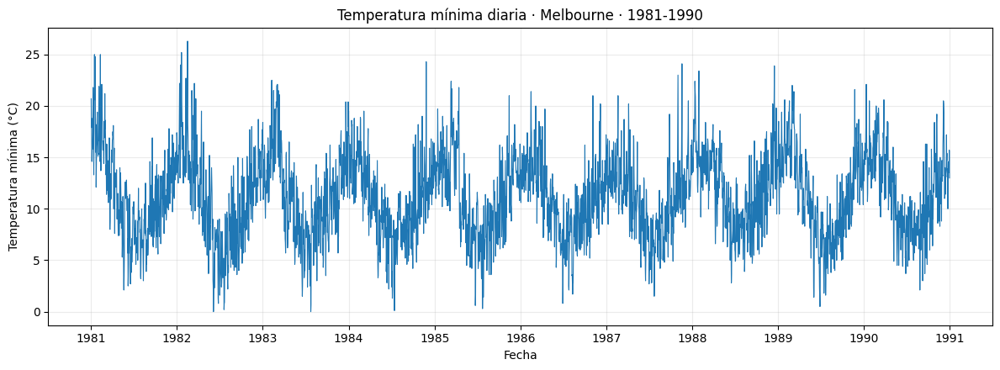

In [11]:
plt.figure(figsize=(12, 4.5))

plt.plot(df['Date'], df['Temp'], linewidth=0.8)

plt.xlabel('Fecha')
plt.ylabel('Temperatura mínima (°C)')
plt.title('Temperatura mínima diaria · Melbourne · 1981-1990')
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(IMAGES_DIR / '01_serie_temporal_dataset.png', dpi=200, bbox_inches='tight')

plt.show()

La representación de la serie completa permite observar tanto la variabilidad diaria de la temperatura como su estructura temporal a largo plazo.

El dataset original contiene únicamente la fecha y la temperatura mínima observada. Por este motivo, la ampliación posterior hacia un problema multivariante se construye exclusivamente a partir de información temporal y estadística derivada de la propia serie, evitando incorporar fuentes externas de información.

Esta primera inspección también permite comprobar la calidad estructural del conjunto antes de generar retardos, estadísticas móviles y ventanas temporales.

### 2.2. Separación temporal TRAIN · VALIDACIÓN · TEST

La serie se divide respetando estrictamente el orden temporal para evitar que información posterior intervenga en el entrenamiento o en la selección del modelo.

Se utilizan tres bloques independientes:

- **TRAIN:** primeras 2400 observaciones, utilizadas para ajustar los parámetros de los modelos.
- **VALIDACIÓN:** siguientes 600 observaciones, reservadas para controlar el entrenamiento y comparar las distintas arquitecturas.
- **TEST:** últimas 650 observaciones, utilizadas exclusivamente para la evaluación final.

Esta separación temporal evita utilizar ventanas solapadas entre entrenamiento y validación y garantiza que la normalización se ajuste únicamente con información procedente del conjunto de entrenamiento.

In [12]:
temperaturas = df['Temp'].values

TEST_START = 3000
VAL_FRACTION = 0.20

VAL_SIZE = int(TEST_START * VAL_FRACTION)
TRAIN_END = TEST_START - VAL_SIZE

train_data = temperaturas[:TRAIN_END]
val_data = temperaturas[TRAIN_END:TEST_START]
test_data = temperaturas[TEST_START:]

# Fechas correspondientes al conjunto de TEST
test_dates = df['Date'].iloc[TEST_START:].reset_index(drop=True)

print('Número total de observaciones:', len(temperaturas))
print('Periodo:', df['Date'].min().date(), '-', df['Date'].max().date())
print('Observaciones TRAIN:', len(train_data))
print('Observaciones VALIDACIÓN:', len(val_data))
print('Observaciones TEST:', len(test_data))
print('Primeros valores TRAIN:', train_data[:10])

Número total de observaciones: 3650
Periodo: 1981-01-01 - 1990-12-31
Observaciones TRAIN: 2400
Observaciones VALIDACIÓN: 600
Observaciones TEST: 650
Primeros valores TRAIN: [20.7 17.9 18.8 14.6 15.8 15.8 15.8 17.4 21.8 20. ]


## 3. Modelo de referencia univariante

### 3.1. Formulación del problema y construcción de ventanas

La serie temporal se transforma en ventanas para adaptarla al formato de entrada requerido por una red neuronal recurrente.

En esta primera aproximación se utiliza:

- **past:** 5 días (`past_ref = 5`);
- **horizon:** `t+2` (`horizon_ref = 2`);
- **outputs:** 1 valor de temperatura;
- **variables de entrada:** 1, la temperatura mínima diaria.

Cada muestra queda representada con forma:

`[samples, timesteps, features]`

por lo que se añade una dimensión mediante `np.newaxis` para representar explícitamente la única característica disponible.

La construcción de ventanas mantiene el orden temporal de la serie y separa cada muestra en una secuencia histórica de entrada y su correspondiente objetivo futuro.

Este primer escenario se utiliza como referencia metodológica para introducir posteriormente una formulación multivariante y multi-step más completa.

In [13]:
X_train, y_train = create_windows_np(train_data, past_ref, horizon_ref, shuffle=False)

X_val, y_val = create_windows_np(val_data, past_ref, horizon_ref, shuffle=False)

X_test, y_test = create_windows_np(test_data, past_ref, horizon_ref, shuffle=False)

X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print('Train shape:', X_train.shape)
print('Train target shape:', y_train.shape)
print('Validation shape:', X_val.shape)
print('Validation target shape:', y_val.shape)
print('Test shape:', X_test.shape)
print('Test target shape:', y_test.shape)

Train shape: (2394, 5, 1)
Train target shape: (2394,)
Validation shape: (594, 5, 1)
Validation target shape: (594,)
Test shape: (644, 5, 1)
Test target shape: (644,)


### 3.2. Arquitectura GRU de referencia

Se construye un modelo recurrente formado por dos capas GRU. La primera capa utiliza `return_sequences=True` porque debe devolver una secuencia completa a la segunda capa. La segunda GRU resume la información aprendida y la capa densa final genera una única predicción numérica (temperatura).

Antes de las capas GRU se incorpora una capa `Normalization`, adaptada únicamente con los datos de entrenamiento, para estabilizar la escala de los datos de entrada. Además, se utiliza el optimizador Adam con un `learning_rate` de `0.0005`, más conservador que el valor por defecto, para tener un entrenamiento más estable.

La función de pérdida utilizada es el error cuadrático medio (`MSE`), adecuada para un problema de regresión. También se añaden las métricas `RMSE` y `MAE`, ya que permiten interpretar el error en unidades de temperatura.

I0000 00:00:1791113801.479356     692 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "modelo_gru_univariante"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5, 1)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 5, 1)           │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 5, 64)          │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,892 (148.02 KB)

 Trainable params: 37,889 (148.00 KB)

 Non-trainable params: 3 (16.00 B)

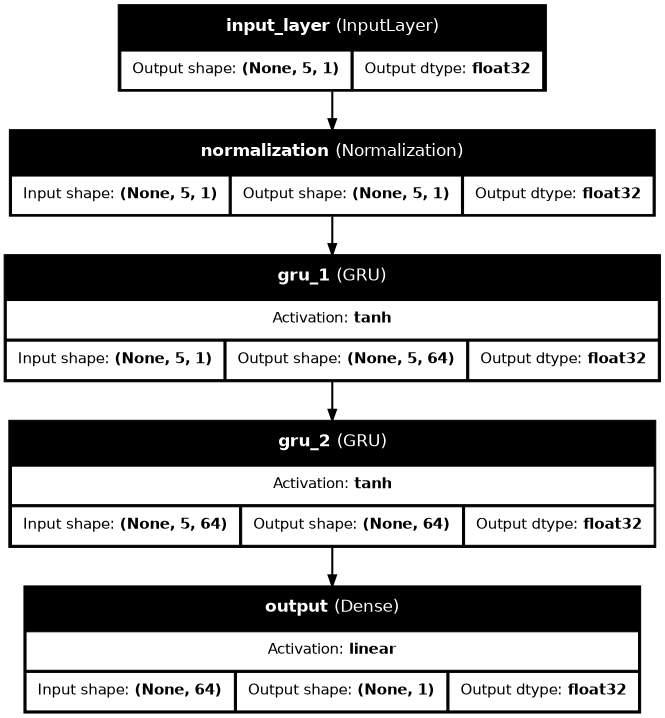

In [14]:
# Modelo de referencia
model_name = REFERENCE_MODEL

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

inputs = keras.layers.Input(shape=inputs_shape)
inputs_norm = normalizer(inputs)

gru_1 = layers.GRU(64, return_sequences=True, name='gru_1')(inputs_norm)
gru_2 = layers.GRU(64, return_sequences=False, name='gru_2')(gru_1)

outputs = layers.Dense(1, name='output')(gru_2)

model_referencia = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

model_referencia.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_referencia.summary()

tf.keras.utils.plot_model(
    model_referencia,
    to_file=str(IMAGES_DIR / '02_arquitectura_gru_baseline.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

### 3.3. Entrenamiento y evaluación

Para controlar el entrenamiento se utilizan varios callbacks:
- `EarlyStopping` detiene el entrenamiento cuando la pérdida de validación deja de mejorar durante varias épocas, evitando entrenamientos innecesarios y reduciendo el riesgo de sobreajuste.

- `ModelCheckpoint`, que almacena los mejores pesos del modelo según `val_loss`. Antes de test, se cargan esos pesos para asegurar que la evaluación se realiza con la mejor versión encontrada durante el entrenamiento.

- `ReduceLROnPlateau` reduce automáticamente el `learning_rate` cuando la pérdida de validación se estanca, permitiendo realizar ajustes más finos en las últimas fases del entrenamiento.

In [15]:
history_referencia, checkpoint_referencia = train_model(
    model_referencia, model_name, X_train, y_train, X_val, y_val, batch_size=64
)


Entrenando · GRU univariante
Epoch 1/200


2026-10-04 13:36:43.816409: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900


 1/38 ━━━━━━━━━━━━━━━━━━━━ 1:10 2s/step - loss: 150.5032 - mae: 11.5584 - rmse: 12.2680

 7/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 141.2897 - mae: 11.1785 - rmse: 11.8850 

13/38 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 138.9789 - mae: 11.0658 - rmse: 11.7876

...

27/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8.4892 - mae: 2.2589 - rmse: 2.9127

32/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 8.4910 - mae: 2.2612 - rmse: 2.9131

37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 8.4829 - mae: 2.2624 - rmse: 2.9119

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 8.4489 - mae: 2.2719 - rmse: 2.9067 - val_loss: 8.2227 - val_mae: 2.2166 - val_rmse: 2.8675 - learning_rate: 2.5000e-04



Entrenamiento finalizado · GRU univariante
Épocas ejecutadas: 160
Mejor época según val_loss: 150
MAE de validación en el checkpoint: 2.2139
Tiempo de entrenamiento: 89.64 s


In [16]:
results_referencia = evaluar_modelo(
    model_referencia, model_name, checkpoint_referencia, X_test, y_test
)

step_metrics_referencia, y_pred_referencia = evaluar_steps(
    model_referencia, model_name, X_test, y_test, horizon_ref
)

modelo_gru_univariante
Test MSE: 6.960493087768555
Test RMSE: 2.638274669647217
Test MAE: 2.0662195682525635



Step t+2:
MSE: 6.960493258476903
RMSE: 2.638274674569898
MAE: 2.066219410244723



El modelo de referencia obtiene un `Test MSE` de `6.9605`, un `RMSE` de `2.6383` y un `MAE` de `2.0662`.

El `MAE` permite interpretar directamente el rendimiento: la predicción situada dos días por delante se desvía, en promedio, aproximadamente **2.07 °C** respecto al valor observado. El `RMSE`, algo superior, refleja la mayor penalización de los errores de mayor magnitud.

Durante el entrenamiento se utiliza un conjunto de validación junto con `EarlyStopping`, `ReduceLROnPlateau` y `ModelCheckpoint`. La evaluación final se realiza después de recuperar los mejores pesos encontrados según `val_loss`, utilizando el mismo procedimiento de registro y evaluación aplicado posteriormente a las arquitecturas multivariantes.

Este modelo constituye la **referencia recurrente univariante** del proyecto. La segunda etapa amplía la ventana histórica, incorpora 25 variables derivadas adicionales y transforma la salida en una predicción directa de tres horizontes.

Aunque ambos planteamientos permiten evaluar `t+2`, la comparación posterior entre ellos tiene carácter descriptivo, ya que cambian simultáneamente el número de variables, la longitud de la ventana y la formulación de la salida.

### 3.4. Predicción frente a valores reales

Como primera evaluación visual se comparan los valores observados y las predicciones del modelo GRU univariante sobre un tramo consecutivo del conjunto de test.

Esta representación permite comprobar si el modelo sigue la dinámica general de la serie y observar posibles desviaciones o suavización de los valores extremos.

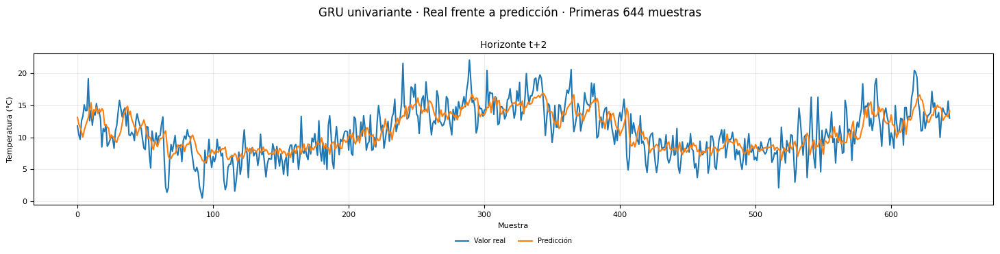

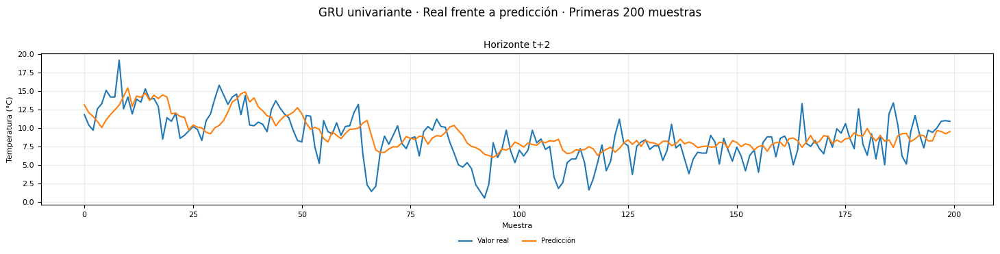

In [17]:
n_test = len(test_data)

plot_real_vs_prediction(REFERENCE_MODEL, y_test, n=n_test)

plot_real_vs_prediction(REFERENCE_MODEL, y_test, n=200)

### 3.5. Predicciones individuales

Para estudiar predicciones concretas se selecciona de forma reproducible un conjunto de fechas pertenecientes al periodo común disponible para ambos planteamientos.

Las mismas fechas se reutilizarán posteriormente con el modelo multivariante seleccionado. La correspondencia se establece mediante `t+2`, ya que es el objetivo del modelo univariante y también forma parte de la salida multi-step.

Cada representación muestra la ventana histórica realmente utilizada por el modelo y sitúa tanto el valor observado como la predicción sobre sus fechas reales.

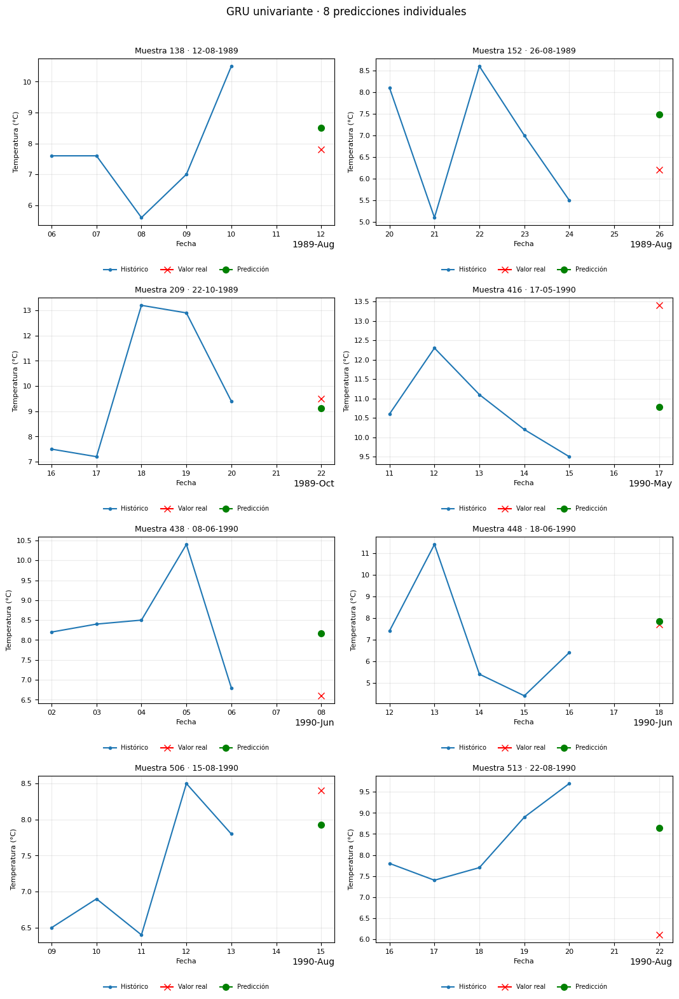

Muestra,Fecha inicio,Real t+2,Pred. t+2,Error abs. t+2
138,1989-08-06 00:00:00,7.80,8.50,0.70
152,1989-08-20 00:00:00,6.20,7.48,1.28
209,1989-10-16 00:00:00,9.50,9.12,0.38
416,1990-05-11 00:00:00,13.40,10.78,2.62
438,1990-06-02 00:00:00,6.60,8.17,1.57
448,1990-06-12 00:00:00,7.70,7.84,0.14
506,1990-08-09 00:00:00,8.40,7.93,0.47
513,1990-08-16 00:00:00,6.10,8.65,2.55


In [18]:
# Conjunto de fechas aleatorias de comparación
common_start = max(past_ref + comparison_step - 1, past + comparison_step - 1)

common_end = min(len(test_dates) - 1, len(test_dates) - future + comparison_step - 1)

common_dates = test_dates.iloc[common_start: common_end + 1].reset_index(drop=True)

rng = np.random.default_rng(semilla)

selected_positions = np.sort(
    rng.choice(len(common_dates), size=n_predictions, replace=False)
)

fechas_comparacion = common_dates.iloc[selected_positions].reset_index(drop=True)

# Representación gráfica
indices_referencia = plot_individual_predictions(
    REFERENCE_MODEL, X_test, y_test, fechas_comparacion
)

# Tabla de comparación de las predicciones
predicciones_referencia = crear_tabla_predicciones(REFERENCE_MODEL, y_test, past_ref)

detalles_referencia = predicciones_referencia.iloc[indices_referencia]

detalles_referencia_display = detalles_referencia[[
    'sample', 'start_date', 'real_t2', 'pred_t2', 'abs_error_t2'
]].rename(columns={
    'sample': 'Muestra',
    'start_date': 'Fecha inicio',
    'real_t2': 'Real t+2',
    'pred_t2': 'Pred. t+2',
    'abs_error_t2': 'Error abs. t+2'
}).style.hide(axis='index').format({
    'Real t+2': '{:.2f}', 'Pred. t+2': '{:.2f}', 'Error abs. t+2': '{:.2f}'
})

display(detalles_referencia_display)

## 4. Predicción multivariante y preparación de datos

Una vez establecido el modelo recurrente univariante de referencia, el problema se amplía hacia un escenario más completo de forecasting.

La nueva formulación incorpora múltiples variables derivadas de la serie temporal, aumenta la ventana histórica y transforma la salida en una predicción directa de tres días futuros (`t+1`, `t+2` y `t+3`).

En este bloque se construye el dataset multivariante, se analiza la relación entre sus variables y se generan las ventanas temporales que utilizarán posteriormente todas las arquitecturas comparadas.

### 4.1. Ampliación del problema de predicción

A partir del modelo GRU univariante se plantea una segunda aproximación más completa.

El problema inicial utilizaba cinco temperaturas históricas para estimar un único valor situado dos días por delante. En esta segunda etapa se modifica deliberadamente el planteamiento:

- **past:** 14 días;
- **future:** 3 valores (`t+1`, `t+2` y `t+3`);
- **predicción:** directa y simultánea de `t+1`, `t+2` y `t+3`;
- **entrada:** conjunto multivariante de características temporales y estadísticas.

El objetivo es evaluar si una representación más rica de la dinámica temporal, combinada con arquitecturas recurrentes e híbridas, permite mejorar la capacidad predictiva.

Se comparan siete modelos sobre el mismo conjunto multivariante, la misma partición temporal, la misma ventana histórica, los mismos tres horizontes de salida y el mismo procedimiento general de evaluación:

1. GRU base;
2. Conv1D + LSTM;
3. Conv1D + GRU;
4. Conv1D + GRU residual;
5. Conv1D + LSTM residual;
6. arquitectura de dos ramas;
7. arquitectura de dos ramas ampliada con unión ponderada.

Todos se evalúan mediante `MSE`, `RMSE` y `MAE`. Además del error global, se analiza el rendimiento individual en cada horizonte de predicción (`t+1`, `t+2` y `t+3`).

### 4.2. Ingeniería de variables temporales y estadísticas

Para mejorar la capacidad predictiva de los modelos, se amplía la serie original de temperatura con nuevas variables derivadas. La idea es que el modelo no reciba únicamente la temperatura observada en días anteriores, sino también distintas formas de resumir la evolución reciente, la estacionalidad y la comparación con periodos equivalentes.

En primer lugar, se crean variables cíclicas anuales mediante seno y coseno (`year_sin` y `year_cos`). Estas variables representan la posición del día dentro del año respetando su carácter circular. De esta forma, el modelo puede aprender la estacionalidad anual de la temperatura sin interpretar artificialmente que el final de diciembre y el inicio de enero son momentos alejados.

También se añaden retardos temporales (`temp_lag_1`, `temp_lag_3`, `temp_lag_7`, `temp_lag_14` y `temp_lag_365`). Estos retardos proporcionan referencias de la temperatura en días anteriores, desde valores muy recientes hasta una referencia anual aproximada.

Además, se incorporan diferencias recientes (`temp_diff_1`, `temp_diff_3`, `temp_diff_7` y `temp_diff_14`), que permiten indicar si la temperatura está subiendo o bajando respecto a días anteriores. Esta información es especialmente útil en una predicción multi-step, ya que para estimar `t+1`, `t+2` y `t+3` no solo interesa el nivel actual de temperatura, sino también su tendencia reciente.

Se calculan también medias móviles, medianas móviles, desviaciones típicas móviles y rangos térmicos para ventanas de 7 y 14 días. Estas variables resumen el comportamiento reciente de la serie: nivel medio, estabilidad, dispersión y amplitud de los cambios. Las medias exponenciales (`temp_ewm_7` y `temp_ewm_14`) aportan una versión suavizada de la temperatura reciente, dando más importancia a los valores más próximos.

Por último, se añade una variable que recoge la temperatura registrada en la misma fecha del año anterior (`temp_misma_fecha`) y otra que mide la diferencia respecto a esa referencia (`temp_cambio_misma_fecha`). Estas variables permiten comparar el comportamiento actual con una referencia estacional directa.

Aunque algunas variables están correlacionadas entre sí, se mantienen para proporcionar al modelo distintas representaciones de la dinámica temporal. La matriz de correlación permitirá identificar esta redundancia antes del entrenamiento.

En este proyecto no se realiza un estudio de ablación individual de cada variable, por lo que la aportación específica de cada característica no se interpreta de forma aislada. La comparación posterior evalúa el rendimiento del conjunto multivariante completo.

In [19]:
df = df[['Date', 'Temp']].copy()

# Ordenamos por fecha y eliminamos posibles duplicados
df = df.sort_values('Date').drop_duplicates(subset='Date', keep='first').reset_index(drop=True)

# VARIABLES CÍCLICAS
# Posición dentro del año
year_fraction = df['Date'].dt.dayofyear / 365.25

df['year_sin'] = np.sin(2 * np.pi * year_fraction)
df['year_cos'] = np.cos(2 * np.pi * year_fraction)

# RETARDOS TEMPORALES
df['temp_lag_1'] = df['Temp'].shift(1)
df['temp_lag_3'] = df['Temp'].shift(3)
df['temp_lag_7'] = df['Temp'].shift(7)
df['temp_lag_14'] = df['Temp'].shift(14)
df['temp_lag_365'] = df['Temp'].shift(365)

# CAMBIOS RECIENTES DE TEMPERATURA
df['temp_diff_1'] = df['Temp'].diff(1)
df['temp_diff_3'] = df['Temp'].diff(3)
df['temp_diff_7'] = df['Temp'].diff(7)
df['temp_diff_14'] = df['Temp'].diff(14)

# MEDIAS MÓVILES
df['temp_roll_mean_7'] = df['Temp'].rolling(window=7, min_periods=1).mean()
df['temp_roll_mean_14'] = df['Temp'].rolling(window=14, min_periods=1).mean()

# MEDIANAS MÓVILES
df['temp_roll_median_7'] = df['Temp'].rolling(window=7, min_periods=1).median()
df['temp_roll_median_14'] = df['Temp'].rolling(window=14, min_periods=1).median()

# DESVIACIONES TÍPICAS MÓVILES
df['temp_roll_std_7'] = df['Temp'].rolling(window=7, min_periods=1).std()
df['temp_roll_std_14'] = df['Temp'].rolling(window=14, min_periods=1).std()

# VALORES MÁXIMOS-MÍNIMOS Y RANGO RECIENTE
df['temp_roll_min_7'] = df['Temp'].rolling(window=7, min_periods=1).min()
df['temp_roll_max_7'] = df['Temp'].rolling(window=7, min_periods=1).max()
df['temp_roll_range_7'] = df['temp_roll_max_7'] - df['temp_roll_min_7']

df['temp_roll_min_14'] = df['Temp'].rolling(window=14, min_periods=1).min()
df['temp_roll_max_14'] = df['Temp'].rolling(window=14, min_periods=1).max()
df['temp_roll_range_14'] = df['temp_roll_max_14'] - df['temp_roll_min_14']

# MEDIAS EXPONENCIALES
df['temp_ewm_7'] = df['Temp'].ewm(span=7, adjust=False).mean()
df['temp_ewm_14'] = df['Temp'].ewm(span=14, adjust=False).mean()

# ANOMALÍAS RESPECTO AL COMPORTAMIENTO RECIENTE
df['temp_anomaly_7'] = df['Temp'] - df['temp_roll_mean_7']
df['temp_anomaly_14'] = df['Temp'] - df['temp_roll_mean_14']

# TEMPERATURA DE LA MISMA FECHA DEL AÑO ANTERIOR
df_fecha_anterior = df[['Date', 'Temp']].copy()

df_fecha_anterior['referencia'] = df_fecha_anterior['Date'].dt.year + 1
df_fecha_anterior['mes'] = df_fecha_anterior['Date'].dt.month
df_fecha_anterior['dia'] = df_fecha_anterior['Date'].dt.day
df_fecha_anterior = df_fecha_anterior[[
    'referencia', 'mes', 'dia', 'Temp'
]].rename(columns={'Temp': 'temp_misma_fecha'})

# Eliminación de posibles duplicados
df_fecha_anterior = df_fecha_anterior.drop_duplicates(
    subset=['referencia', 'mes', 'dia'], keep='first'
)
df['year_'] = df['Date'].dt.year
df['mes'] = df['Date'].dt.month
df['dia'] = df['Date'].dt.day

df = df.merge(
    df_fecha_anterior, left_on=['year_', 'mes', 'dia'],
    right_on=['referencia', 'mes', 'dia'], how='left'
)

# Cambio respecto a la misma fecha del año anterior
df['temp_cambio_misma_fecha'] = (df['Temp'] - df['temp_misma_fecha'])

# Eliminación columnas auxiliares
df = df.drop(columns=['year_', 'mes', 'dia', 'referencia'])

# VALORES INICIALES DE LAS VARIABLES
cols_fill_0 = [
    'temp_diff_1',
    'temp_diff_3',
    'temp_diff_7',
    'temp_diff_14',
    'temp_roll_std_7',
    'temp_roll_std_14',
    'temp_cambio_misma_fecha'
]

for col in cols_fill_0:
    df[col] = df[col].fillna(0)

cols_lag = [
    'temp_lag_1',
    'temp_lag_3',
    'temp_lag_7',
    'temp_lag_14',
    'temp_lag_365'
]

for col in cols_lag:
    df[col] = df[col].fillna(df['temp_ewm_7'])

df['temp_misma_fecha'] = df['temp_misma_fecha'].fillna(df['temp_lag_365']).fillna(df['temp_ewm_7'])

# DATASET FINAL
df_multi = df[[
    'Temp', 'year_sin', 'year_cos', 'temp_lag_1', 'temp_lag_3', 'temp_lag_7', 'temp_lag_14',
    'temp_lag_365', 'temp_diff_1', 'temp_diff_3', 'temp_diff_7', 'temp_diff_14', 'temp_roll_mean_7',
    'temp_roll_mean_14', 'temp_roll_median_7', 'temp_roll_median_14', 'temp_roll_std_7',
    'temp_roll_std_14', 'temp_roll_range_7', 'temp_roll_range_14', 'temp_ewm_7', 'temp_ewm_14',
    'temp_anomaly_7', 'temp_anomaly_14', 'temp_misma_fecha', 'temp_cambio_misma_fecha'
]].copy()

# COMPROBACIÓN DATASET
print('Shape df:', df.shape)
print('Shape df_multi:', df_multi.shape)
print('Fechas duplicadas:', df['Date'].duplicated().sum())
print('Valores nulos en df_multi:', df_multi.isna().sum().sum())

# TRAIN-VALIDACIÓN-TEST SPLIT
train_data = df_multi.iloc[:TRAIN_END].copy()
val_data = df_multi.iloc[TRAIN_END:TEST_START].copy()
test_data = df_multi.iloc[TEST_START:].copy()

target_col_idx = df_multi.columns.get_loc('Temp')

df_multi.head()

Shape df: (3650, 31)
Shape df_multi: (3650, 26)
Fechas duplicadas: 0
Valores nulos en df_multi: 0


,Temp,year_sin,year_cos,temp_lag_1,temp_lag_3,temp_lag_7,temp_lag_14,temp_lag_365,temp_diff_1,temp_diff_3,...,temp_roll_std_7,temp_roll_std_14,temp_roll_range_7,temp_roll_range_14,temp_ewm_7,temp_ewm_14,temp_anomaly_7,temp_anomaly_14,temp_misma_fecha,temp_cambio_misma_fecha
0,20.7,0.017202,0.999852,20.7,20.7,20.70000,20.70000,20.70000,0.0,0.0,...,0.000000,0.000000,0.0,0.0,20.70000,20.700000,0.000000,0.000000,20.70000,0.0
1,17.9,0.034398,0.999408,20.7,20.0,20.00000,20.00000,20.00000,-2.8,0.0,...,1.979899,1.979899,2.8,2.8,20.00000,20.326667,-1.400000,-1.400000,20.00000,0.0
2,18.8,0.051584,0.998669,17.9,19.7,19.70000,19.70000,19.70000,0.9,0.0,...,1.429452,1.429452,2.8,2.8,19.70000,20.123111,-0.333333,-0.333333,19.70000,0.0
3,14.6,0.068755,0.997634,18.8,20.7,18.42500,18.42500,18.42500,-4.2,-6.1,...,2.549510,2.549510,6.1,6.1,18.42500,19.386696,-3.400000,-3.400000,18.42500,0.0
4,15.8,0.085906,0.996303,14.6,17.9,17.76875,17.76875,17.76875,1.2,-2.1,...,2.417230,2.417230,6.1,6.1,17.76875,18.908470,-1.760000,-1.760000,17.76875,0.0


Las comprobaciones muestran que el dataset multivariante mantiene las 3650 observaciones originales, no contiene fechas duplicadas y no presenta valores nulos. Esto es importante porque evita que la creación de variables derivadas introduzca inconsistencias en la serie temporal.

El dataset final contiene 26 variables, incluyendo la temperatura original y las variables temporales, estadísticas y estacionales creadas. A partir de este conjunto multivariante se construyen posteriormente las ventanas temporales que alimentan a los modelos recurrentes.

Las variables que necesitan observaciones anteriores generan valores no disponibles al inicio de la serie. Para mantener la longitud completa del dataset se aplican imputaciones causales: los retardos iniciales utilizan `temp_ewm_7` como referencia, `temp_misma_fecha` recurre al retardo anual o a dicha media exponencial cuando no existe una observación equivalente del año anterior, y el cambio anual no disponible se representa mediante un valor neutro de `0`.

Estas imputaciones afectan principalmente al tramo inicial de la serie y utilizan únicamente información disponible hasta el instante considerado.

### 4.3. Análisis de correlación

Antes de entrenar los modelos se representa la matriz de correlación de las variables creadas. Esta visualización permite comprobar qué variables contienen información similar y cuáles aportan señales más diferenciadas.

En este problema es normal encontrar correlaciones elevadas entre la temperatura, los retardos, las medias móviles, las medias exponenciales y algunas variables de anomalía. Todas ellas están relacionadas con el nivel reciente de la serie. Sin embargo, no se eliminan automáticamente, ya que el objetivo principal es mejorar la capacidad predictiva de los modelos y las redes neuronales pueden combinar variables correlacionadas de forma no lineal.

La matriz de correlación se utiliza como herramienta de interpretación para identificar redundancias y relaciones entre variables. Las características se mantienen como una representación conjunta del comportamiento temporal, pero no se atribuye a ninguna de ellas una mejora individual, ya que no se realiza un estudio de ablación.

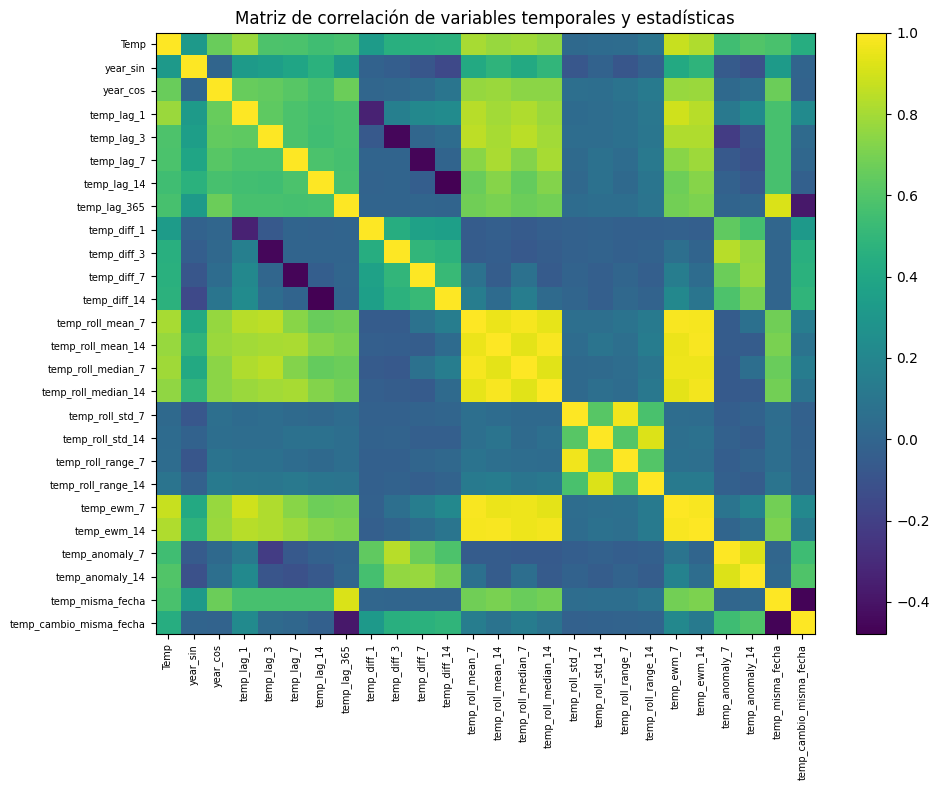

In [20]:
# Matriz de correlación de las variables creadas
corr = df_multi.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, aspect='auto')
plt.colorbar()

plt.xticks(ticks=np.arange(len(corr.columns)), labels=corr.columns, rotation=90, fontsize=7)

plt.yticks(ticks=np.arange(len(corr.columns)), labels=corr.columns, fontsize=7)

plt.title('Matriz de correlación de variables temporales y estadísticas')
plt.tight_layout()

plt.savefig(IMAGES_DIR / '03_matriz_correlacion.png', dpi=200, bbox_inches='tight')

plt.show()

La matriz confirma que varias variables derivadas presentan correlaciones altas, especialmente aquellas que resumen el nivel reciente de temperatura. Esto ocurre con las medias móviles, las medias exponenciales, los retardos y la propia temperatura.

También se observan variables que aportan información más específica, como las diferencias recientes, los rangos térmicos o el cambio respecto a la misma fecha del año anterior. Estas variables pueden ayudar al modelo a distinguir entre situaciones con un mismo nivel de temperatura, pero con distinta tendencia o variabilidad reciente.

### 4.4. Construcción de ventanas multivariantes

Una vez construido el dataset multivariante, la serie se transforma en ventanas temporales. Cada muestra de entrada contiene 14 días consecutivos de información (`past = 14`) y cada salida contiene tres valores futuros de temperatura (`future = 3`).

La entrada de los modelos queda con forma `[samples, timesteps, features]`, donde `timesteps` corresponde a los 14 días de histórico y `features` al número de variables disponibles en cada día. La salida queda con forma `[samples, 3]`, correspondiente a `t+1`, `t+2` y `t+3`.

Este enfoque corresponde a una predicción multi-step directa: el modelo genera todos los pasos futuros de una sola vez, en lugar de predecir primero `t+1` y reutilizar esa predicción para calcular `t+2` y `t+3`.

In [21]:
target_col_idx = df_multi.columns.get_loc('Temp')

X_train, y_train = create_windows_multivariate_np(
    train_data, past, future, target_col_idx, shuffle=False
)

X_val, y_val = create_windows_multivariate_np(
    val_data, past, future, target_col_idx, shuffle=False
)

X_test, y_test = create_windows_multivariate_np(
    test_data, past, future, target_col_idx, shuffle=False
)

print('Train shape:', X_train.shape)
print('Train target shape:', y_train.shape)
print('Validation shape:', X_val.shape)
print('Validation target shape:', y_val.shape)
print('Test shape:', X_test.shape)
print('Test target shape:', y_test.shape)

Train shape: (2384, 14, 26)
Train target shape: (2384, 3)
Validation shape: (584, 14, 26)
Validation target shape: (584, 3)
Test shape: (634, 14, 26)
Test target shape: (634, 3)


Las formas obtenidas confirman que el problema se ha construido correctamente como una predicción multivariante y multi-step. Cada muestra contiene 14 pasos temporales y 26 variables por paso, mientras que cada objetivo contiene tres valores futuros de temperatura.

Esta estructura permite comparar todos los modelos bajo las mismas condiciones: mismo `past`, mismo conjunto de variables y misma salida multi-step (`t+1`, `t+2` y `t+3`).

## 5. Modelos de Deep Learning

Sobre el mismo problema multivariante y multi-step se evalúan siete configuraciones de redes neuronales profundas.

La comparación comienza con una arquitectura GRU como referencia y continúa con modelos híbridos que combinan convoluciones `Conv1D` con capas recurrentes LSTM o GRU. Posteriormente se estudian dos variantes residuales que predicen correcciones respecto a la última temperatura observada.

Finalmente se incorporan dos arquitecturas de procesamiento paralelo. La primera introduce la separación entre la serie original de temperatura y las variables derivadas mediante una unión ponderada, mientras que la segunda amplía la capacidad de ambas ramas y enriquece el mecanismo utilizado para calcular su contribución relativa.

Todas las configuraciones comparten los mismos datos, particiones temporales, horizontes de predicción y procedimiento general de evaluación.

### 5.1. Estrategia común de entrenamiento y evaluación

Las siete arquitecturas multivariantes utilizan la misma separación temporal `TRAIN–VALIDACIÓN–TEST`, las mismas ventanas de entrada y salida y las mismas métricas de evaluación.

El entrenamiento utiliza `MSE` como función de pérdida. Los callbacks `ModelCheckpoint`, `EarlyStopping` y `ReduceLROnPlateau` monitorizan `val_loss`, de forma que para cada arquitectura se recupera el checkpoint asociado al mejor MSE de validación.

Una vez recuperado el mejor checkpoint de cada arquitectura, los modelos se comparan mediante `MAE` de validación, utilizado como criterio principal de selección por su interpretación directa en grados de temperatura.

El conjunto de test permanece fuera del proceso de selección y se utiliza posteriormente para evaluar el comportamiento de la configuración seleccionada.

Además de las métricas globales `MSE`, `RMSE` y `MAE`, se analiza el error de forma independiente para los horizontes `t+1`, `t+2` y `t+3`.

### 5.2. Modelo 1 · GRU

El primer modelo establece la referencia recurrente dentro del escenario multivariante y multi-step. Utiliza una arquitectura GRU deliberadamente sencilla para disponer de un punto de comparación frente a las arquitecturas híbridas posteriores.

La entrada se normaliza mediante una capa `Normalization`, adaptada únicamente con los datos de entrenamiento. Después se emplean dos capas GRU de 64 unidades. La primera utiliza `return_sequences=True`, ya que debe devolver una secuencia completa para que la segunda capa recurrente pueda seguir procesando la evolución temporal. La segunda GRU resume la secuencia en un único vector final.

La capa de salida es una capa densa con `future` neuronas, por lo que el modelo genera simultáneamente tres predicciones: `t+1`, `t+2` y `t+3`.

Este modelo no incorpora convoluciones, conexiones residuales ni concatenación con el último paso observado. Por tanto, sirve como punto de partida para comprobar si las arquitecturas posteriores realmente aportan mejora.

Model: "modelo_gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 14, 26)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 14, 26)         │            53 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 14, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,872 (167.47 KB)

 Trainable params: 42,819 (167.26 KB)

 Non-trainable params: 53 (216.00 B)

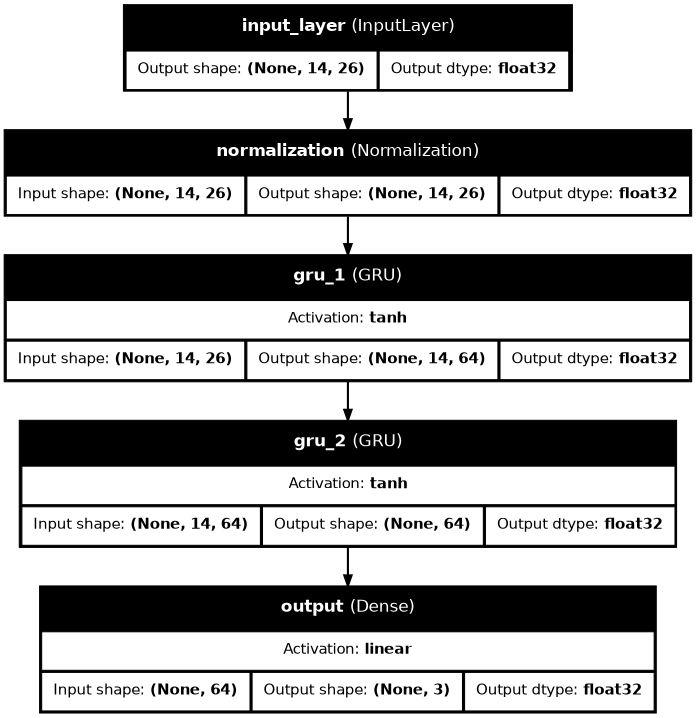

In [22]:
# Modelo 1: GRU
model_name = MULTIVARIATE_MODELS[0]

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

# Normalización de las variables
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

inputs = keras.layers.Input(shape=inputs_shape)

inputs_norm = normalizer(inputs)

gru_1 = layers.GRU(64, return_sequences=True, name='gru_1')(inputs_norm)

gru_2 = layers.GRU(64, return_sequences=False, name='gru_2')(gru_1)

outputs = layers.Dense(future, name='output')(gru_2)

model_gru = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

model_gru.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005), loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_gru.summary()

tf.keras.utils.plot_model(
    model_gru,
    to_file=str(IMAGES_DIR / '04_arquitectura_modelo_1_gru.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

El modelo se entrena con `Adam` y un `learning_rate` de `0.0005`, manteniendo una configuración sencilla y estable. Se aplican los callbacks definidos anteriormente para guardar los mejores pesos, reducir el learning rate cuando la validación se estanque y detener el entrenamiento si deja de mejorar.

Este primer entrenamiento establece el rendimiento base sobre el que se compararán los modelos más complejos.

#### 5.2.1. Entrenamiento y evaluación

In [23]:
history_gru, checkpoint_gru = train_model(
    model_gru, model_name, X_train, y_train, X_val, y_val
)


Entrenando · GRU
Epoch 1/200


 1/75 ━━━━━━━━━━━━━━━━━━━━ 1:04 869ms/step - loss: 127.3816 - mae: 10.4647 - rmse: 11.2863

 5/75 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 136.7374 - mae: 10.8825 - rmse: 11.6917   

 9/75 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 136.0217 - mae: 10.8681 - rmse: 11.6617

13/75 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 135.8436 - mae: 10.8822 - rmse: 11.6543

...

61/75 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.0337 - mae: 1.9458 - rmse: 2.4559

66/75 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.0334 - mae: 1.9459 - rmse: 2.4558

71/75 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 6.0352 - mae: 1.9463 - rmse: 2.4562

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 6.0398 - mae: 1.9445 - rmse: 2.4576 - val_loss: 7.6621 - val_mae: 2.1402 - val_rmse: 2.7680 - learning_rate: 2.5000e-04



Entrenamiento finalizado · GRU
Épocas ejecutadas: 23
Mejor época según val_loss: 13
MAE de validación en el checkpoint: 2.0998
Tiempo de entrenamiento: 25.71 s


In [24]:
results_gru = evaluar_modelo(model_gru, model_name, checkpoint_gru, X_test, y_test)

step_metrics_gru, y_pred_gru = evaluar_steps(model_gru, model_name, X_test, y_test)

modelo_gru
Test MSE: 5.926031112670898
Test RMSE: 2.4343440532684326
Test MAE: 1.9051955938339233



Step t+1:
MSE: 5.118146775053865
RMSE: 2.2623321540069807
MAE: 1.7927922483498362

Step t+2:
MSE: 6.204769086085202
RMSE: 2.490937391040811
MAE: 1.9426993112834847

Step t+3:
MSE: 6.455174837939283
RMSE: 2.540703610801402
MAE: 1.9800958937274922



El modelo GRU multivariante obtiene un `Test MSE` de `5.9259`, un `RMSE` de `2.4343` y un `MAE` de `1.9052`.

Por horizonte de predicción, el `MAE` aumenta desde `1.7928` en `t+1` hasta `1.9427` en `t+2` y `1.9801` en `t+3`.

Esta configuración establece la referencia recurrente dentro del escenario multivariante. Sus resultados mejoran la referencia univariante en el horizonte común `t+2`, aunque esta diferencia forma parte de una modificación más amplia del planteamiento y no puede atribuirse exclusivamente al número de variables.

### 5.3. Modelo 2 · Conv1D + LSTM

El segundo modelo introduce una arquitectura más completa, combinando capas convolucionales y recurrentes. La idea es que las capas `Conv1D` extraigan patrones locales dentro de la ventana temporal, mientras que las capas LSTM procesen la secuencia resultante y aprendan dependencias temporales más complejas.

El modelo comienza con una capa `Normalization`, adaptada con los datos de entrenamiento. Después se extrae el último paso normalizado mediante `last_step`, que se utilizará más adelante como conexión directa con la información más reciente de la ventana.

El bloque convolucional está formado por tres capas `Conv1D` con activación `swish` y `padding='causal'`. El padding causal respeta el orden temporal, evitando que el cálculo de un paso utilice información posterior dentro de la ventana. Tras cada convolución se utiliza `LayerNormalization`, que estabiliza las activaciones internas. Después del tercer bloque se añade `Dropout(0.1)` para reducir el riesgo de sobreajuste.

La parte recurrente está formada por tres capas LSTM. Las dos primeras tienen 128 unidades y `return_sequences=True`, porque deben devolver una secuencia completa para alimentar a la siguiente capa recurrente. La tercera LSTM tiene 64 unidades y `return_sequences=False`, resumiendo la información temporal en un vector final. Tras cada LSTM se incorpora un `Dropout(0.05)`.

A continuación, se concatena la representación aprendida por la parte recurrente con el último paso observado (`last_step`). Esta conexión permite que la capa final combine memoria temporal con la información más reciente de la ventana. Finalmente, una capa densa de 64 neuronas con activación `tanh` transforma esta representación y la salida `Dense(future)` genera las tres predicciones futuras.

Model: "modelo_conv_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 14, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 14, 26)    │         53 │ input_layer[0][0] │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 14, 64)    │      5,056 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv1    │ (None, 14, 64)    │        128 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 14, 32)    │      6,176 │ layer_norm_conv1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv2    │ (None, 14, 32)    │         64 │ conv1d_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 14, 32)    │      3,104 │ layer_norm_conv2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv3    │ (None, 14, 32)    │         64 │ conv1d_3[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_conv3       │ (None, 14, 32)    │          0 │ layer_norm_conv3… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 14, 128)   │     82,432 │ dropout_conv3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_lstm_1      │ (None, 14, 128)   │          0 │ lstm_1[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 14, 128)   │    131,584 │ dropout_lstm_1[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_lstm_2      │ (None, 14, 128)   │          0 │ lstm_2[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 64)        │     49,408 │ dropout_lstm_2[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_lstm_3      │ (None, 64)        │          0 │ lstm_3[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_step (Lambda)  │ (None, 26)        │          0 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_lstm_last_s… │ (None, 90)        │          0 │ dropout_lstm_3[0… │
│ (Concatenate)       │                   │            │ last_step[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      5,824 │ concat_lstm_last… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 3)         │        195 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 284,088 (1.08 MB)

 Trainable params: 284,035 (1.08 MB)

 Non-trainable params: 53 (216.00 B)

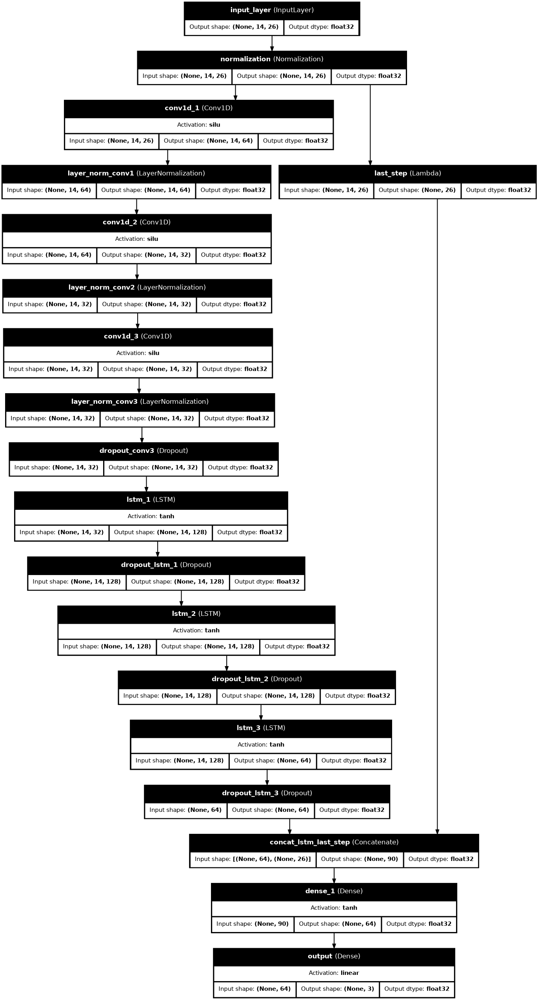

In [25]:
model_name = MULTIVARIATE_MODELS[1]

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

# Normalización de las variables
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

inputs = keras.layers.Input(shape=inputs_shape)

inputs_norm = normalizer(inputs)

# Último Paso
last_step = layers.Lambda(lambda x: x[:, -1, :], name='last_step')(inputs_norm)

# Bloque CONV1D
conv_1 = layers.Conv1D(64, 3, padding='causal', activation='swish', name='conv1d_1')(inputs_norm)
norm_conv_1 = layers.LayerNormalization(name='layer_norm_conv1')(conv_1)

conv_2 = layers.Conv1D(32, 3, padding='causal', activation='swish', name='conv1d_2')(norm_conv_1)
norm_conv_2 = layers.LayerNormalization(name='layer_norm_conv2')(conv_2)

conv_3 = layers.Conv1D(32, 3, padding='causal', activation='swish', name='conv1d_3')(norm_conv_2)
norm_conv_3 = layers.LayerNormalization(name='layer_norm_conv3')(conv_3)
drop_conv3 = layers.Dropout(0.1, name='dropout_conv3')(norm_conv_3)

# Bloque RNN
lstm_1 = layers.LSTM(128, return_sequences=True, name='lstm_1')(drop_conv3)
drop_1 = layers.Dropout(0.05, name='dropout_lstm_1')(lstm_1)

lstm_2 = layers.LSTM(128, return_sequences=True, name='lstm_2')(drop_1)
drop_2 = layers.Dropout(0.05, name='dropout_lstm_2')(lstm_2)

lstm_3 = layers.LSTM(64, return_sequences=False, name='lstm_3')(drop_2)
drop_3 = layers.Dropout(0.05, name='dropout_lstm_3')(lstm_3)

# Unión RNN-last_step
concat = layers.Concatenate(name='concat_lstm_last_step')([drop_3, last_step])

dense_1 = layers.Dense(64, activation='tanh', name='dense_1')(concat)
outputs = layers.Dense(future, name='output')(dense_1)

model_conv_lstm = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

optimizer = keras.optimizers.AdamW(learning_rate=0.0005, weight_decay=1e-5, clipnorm=1.0)

model_conv_lstm.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_conv_lstm.summary()

tf.keras.utils.plot_model(
    model_conv_lstm,
    to_file=str(IMAGES_DIR / '05_arquitectura_modelo_2_conv_lstm.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

Este modelo se compila con `AdamW`, una variante de Adam que incorpora `weight_decay`. Se utiliza un `learning_rate` de `0.0005`, `weight_decay=1e-5` y `clipnorm=1.0`. El `clipnorm` ayuda a estabilizar los gradientes, algo muy útil en RNN.

La función de pérdida sigue siendo `MSE`, adecuada para regresión. Además, se calculan `RMSE` y `MAE`, siendo esta última especialmente interpretable porque expresa el error medio en grados de temperatura.

#### 5.3.1. Entrenamiento y evaluación

In [26]:
history_conv_lstm, checkpoint_conv_lstm = train_model(
    model_conv_lstm, model_name, X_train, y_train, X_val, y_val
)


Entrenando · Conv1D + LSTM
Epoch 1/200


 1/75 ━━━━━━━━━━━━━━━━━━━━ 5:44 5s/step - loss: 127.6958 - mae: 10.5234 - rmse: 11.3003

 3/75 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 134.6485 - mae: 10.8448 - rmse: 11.6018

 6/75 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 135.1121 - mae: 10.8626 - rmse: 11.6228

 9/75 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 133.5467 - mae: 10.8070 - rmse: 11.5551

...

71/75 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 7.0276 - mae: 2.0558 - rmse: 2.6495

73/75 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 7.0316 - mae: 2.0565 - rmse: 2.6503

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 7.0354 - mae: 2.0572 - rmse: 2.6511

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 7.1632 - mae: 2.0807 - rmse: 2.6764 - val_loss: 6.9623 - val_mae: 2.0517 - val_rmse: 2.6386 - learning_rate: 2.5000e-04



Entrenamiento finalizado · Conv1D + LSTM
Épocas ejecutadas: 35
Mejor época según val_loss: 25
MAE de validación en el checkpoint: 2.0364
Tiempo de entrenamiento: 83.28 s


In [27]:
results_conv_lstm = evaluar_modelo(
    model_conv_lstm, model_name, checkpoint_conv_lstm, X_test, y_test
)

step_metrics_conv_lstm, y_pred_conv_lstm = evaluar_steps(
    model_conv_lstm, model_name, X_test, y_test
)

modelo_conv_lstm
Test MSE: 5.661303997039795
Test RMSE: 2.37934947013855
Test MAE: 1.8590272665023804



Step t+1:
MSE: 4.631538648746787
RMSE: 2.15210098479295
MAE: 1.6948253358576202

Step t+2:
MSE: 6.044530139807344
RMSE: 2.458562616613078
MAE: 1.9120643602184693

Step t+3:
MSE: 6.307842284203655
RMSE: 2.511541814145975
MAE: 1.9701925938061735



El modelo Conv1D + LSTM obtiene un `Test MSE` de `5.6613`, un `RMSE` de `2.3793` y un `MAE` de `1.8590`.

Por horizonte alcanza un `MAE` de `1.6948` en `t+1`, `1.9121` en `t+2` y `1.9702` en `t+3`.

Esta configuración consigue el **menor error en `t+1`** entre todas las arquitecturas evaluadas y mantiene un rendimiento competitivo en los horizontes posteriores. Sin embargo, las arquitecturas de dos ramas consiguen posteriormente reducir el error global de validación y mejorar especialmente `t+2` y `t+3`.

### 5.4. Modelo 3 · Conv1D + GRU

El tercer modelo mantiene la idea híbrida del modelo anterior, pero sustituye las capas LSTM por capas GRU. Las GRU son unidades recurrentes con puertas, al igual que las LSTM, pero tienen una estructura más sencilla y menos parámetros. Por ello, pueden ofrecer un buen equilibrio entre capacidad de aprendizaje y coste computacional.

La primera parte del modelo vuelve a utilizar `Normalization`, dos capas `Conv1D` con activación `swish`, `padding='causal'`, `LayerNormalization` y `Dropout(0.1)`. Este bloque se encarga de extraer patrones locales dentro de la ventana temporal.

La parte recurrente está formada por dos capas GRU de 128 unidades. La primera devuelve secuencias completas mediante `return_sequences=True`, mientras que la segunda resume la secuencia en un vector final. Se emplea `Dropout(0.1)` tras la primera GRU y `Dropout(0.05)` tras la segunda.

Al igual que en el modelo anterior, se extrae el último paso observado (`last_step`) y se concatena con la representación recurrente final. Esta unión permite combinar la información más reciente con la memoria temporal aprendida por la red. La salida final se obtiene mediante una capa densa de 64 neuronas con activación `tanh` y una capa `Dense(future)` para predecir `t+1`, `t+2` y `t+3`.

Model: "modelo_conv_gru"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 14, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 14, 26)    │         53 │ input_layer[0][0] │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 14, 64)    │      5,056 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv1    │ (None, 14, 64)    │        128 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 14, 32)    │      6,176 │ layer_norm_conv1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv2    │ (None, 14, 32)    │         64 │ conv1d_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_conv        │ (None, 14, 32)    │          0 │ layer_norm_conv2… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 14, 128)   │     62,208 │ dropout_conv[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_gru_1       │ (None, 14, 128)   │          0 │ gru_1[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_2 (GRU)         │ (None, 128)       │     99,072 │ dropout_gru_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_gru_2       │ (None, 128)       │          0 │ gru_2[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_step (Lambda)  │ (None, 26)        │          0 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_gru_last_st… │ (None, 154)       │          0 │ dropout_gru_2[0]… │
│ (Concatenate)       │                   │            │ last_step[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      9,920 │ concat_gru_last_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 3)         │        195 │ dense_1[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 182,872 (714.35 KB)

 Trainable params: 182,819 (714.14 KB)

 Non-trainable params: 53 (216.00 B)

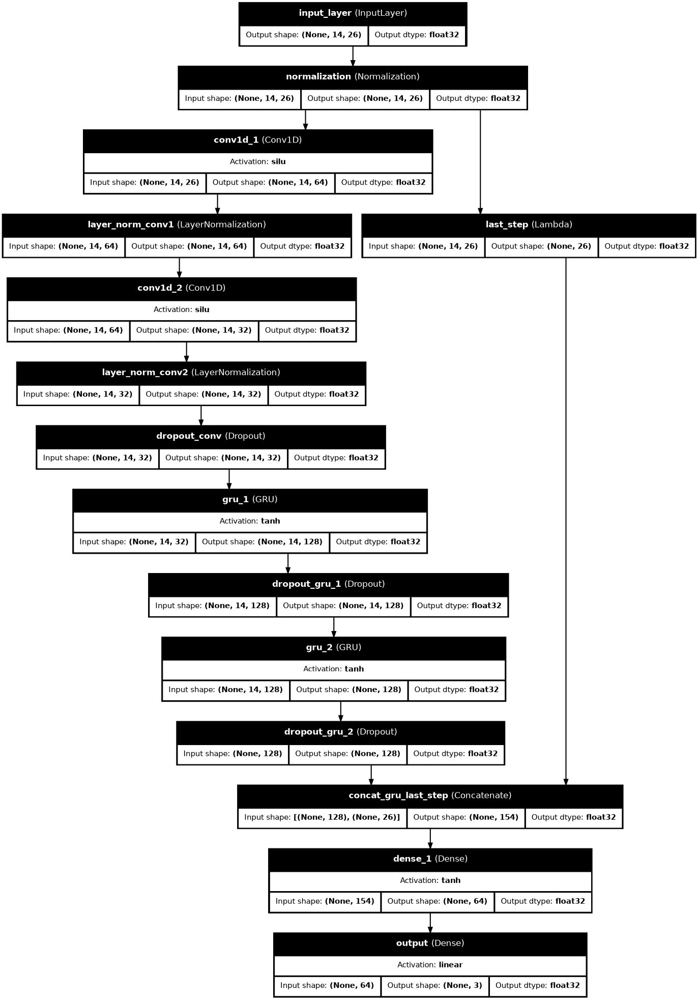

In [28]:
# Modelo 3: Conv1D + GRU
model_name = MULTIVARIATE_MODELS[2]

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

# Normalización de las variables
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

inputs = keras.layers.Input(shape=inputs_shape)

inputs_norm = normalizer(inputs)

# Último paso
last_step = layers.Lambda(lambda x: x[:, -1, :], name='last_step')(inputs_norm)

# Bloque Conv1D
conv_1 = layers.Conv1D(64, 3, padding='causal', activation='swish', name='conv1d_1')(inputs_norm)
norm_conv_1 = layers.LayerNormalization(name='layer_norm_conv1')(conv_1)

conv_2 = layers.Conv1D(32, 3, padding='causal', activation='swish', name='conv1d_2')(norm_conv_1)
norm_conv_2 = layers.LayerNormalization(name='layer_norm_conv2')(conv_2)
drop_conv = layers.Dropout(0.1, name='dropout_conv')(norm_conv_2)

# Bloque GRU
gru_1 = layers.GRU(128, return_sequences=True, name='gru_1')(drop_conv)
drop_1 = layers.Dropout(0.1, name='dropout_gru_1')(gru_1)

gru_2 = layers.GRU(128, return_sequences=False, name='gru_2')(drop_1)
drop_2 = layers.Dropout(0.05, name='dropout_gru_2')(gru_2)

# Unión RNN-last_step
concat = layers.Concatenate(name='concat_gru_last_step')([drop_2, last_step])

dense_1 = layers.Dense(64, activation='tanh', name='dense_1')(concat)
outputs = layers.Dense(future, name='output')(dense_1)

model_conv_gru = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

optimizer = keras.optimizers.AdamW(learning_rate=0.0005, weight_decay=1e-5, clipnorm=1.0)

model_conv_gru.compile(
    optimizer=optimizer, loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_conv_gru.summary()

tf.keras.utils.plot_model(
    model_conv_gru,
    to_file=str(IMAGES_DIR / '06_arquitectura_modelo_3_conv_gru.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

#### 5.4.1. Entrenamiento y evaluación

In [29]:
history_conv_gru, checkpoint_conv_gru = train_model(
    model_conv_gru, model_name, X_train, y_train, X_val, y_val
)


Entrenando · Conv1D + GRU
Epoch 1/200


 1/75 ━━━━━━━━━━━━━━━━━━━━ 2:31 2s/step - loss: 128.2856 - mae: 10.4888 - rmse: 11.3263

 3/75 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 134.7625 - mae: 10.7794 - rmse: 11.6070

 6/75 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 134.5303 - mae: 10.7623 - rmse: 11.5978

 8/75 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 133.1189 - mae: 10.7098 - rmse: 11.5365

...

67/75 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 5.1651 - mae: 1.7756 - rmse: 2.2721

70/75 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 5.1680 - mae: 1.7763 - rmse: 2.2728

73/75 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 5.1700 - mae: 1.7768 - rmse: 2.2732

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 5.2013 - mae: 1.7845 - rmse: 2.2806 - val_loss: 8.1617 - val_mae: 2.2307 - val_rmse: 2.8569 - learning_rate: 2.5000e-04



Entrenamiento finalizado · Conv1D + GRU
Épocas ejecutadas: 18
Mejor época según val_loss: 8
MAE de validación en el checkpoint: 2.0863
Tiempo de entrenamiento: 34.67 s


In [30]:
results_conv_gru = evaluar_modelo(model_conv_gru, model_name, checkpoint_conv_gru, X_test, y_test)

step_metrics_conv_gru, y_pred_conv_gru = evaluar_steps(
    model_conv_gru, model_name, X_test, y_test
)

modelo_conv_gru
Test MSE: 5.764922618865967
Test RMSE: 2.4010252952575684
Test MAE: 1.888513207435608



Step t+1:
MSE: 4.912717469394315
RMSE: 2.216465084181187
MAE: 1.7512424792401042

Step t+2:
MSE: 6.111678635691946
RMSE: 2.4721809471986362
MAE: 1.9385013023761544

Step t+3:
MSE: 6.270373353841765
RMSE: 2.5040713555810994
MAE: 1.97579586017019



El modelo Conv1D + GRU obtiene un `Test MSE` de `5.7655`, un `RMSE` de `2.4011` y un `MAE` de `1.8886`.

Por horizonte de predicción obtiene un `MAE` de `1.7514` en `t+1`, `1.9385` en `t+2` y `1.9759` en `t+3`.

La configuración mantiene un rendimiento próximo al modelo Conv1D + LSTM, aunque presenta un error ligeramente superior en los tres horizontes. Las diferencias observadas corresponden a las configuraciones completas evaluadas y no deben atribuirse exclusivamente al uso de GRU o LSTM.

### 5.5. Modelo 4 · Conv1D + GRU residual

El cuarto modelo introduce una idea residual. En lugar de predecir directamente la temperatura futura, el modelo aprende una corrección respecto a la última temperatura observada. La predicción final se construye como:

`predicción = última temperatura observada + cambio estimado`

Este enfoque parte de una idea intuitiva en series temporales de temperatura: a corto plazo, el valor futuro suele estar relacionado con el último valor observado. Por ello, puede ser más sencillo para el modelo aprender cuánto debe subir o bajar la temperatura que reconstruir directamente el valor absoluto futuro.

La arquitectura mantiene el bloque Conv1D + GRU del modelo anterior, pero añade una rama que extrae la última temperatura en escala real (`last_temp`) y la repite tres veces para formar una base inicial para `t+1`, `t+2` y `t+3`. La red principal predice un vector `delta`, que representa el cambio estimado para cada horizonte. Finalmente, mediante una capa `Add`, se suma la última temperatura repetida con ese cambio estimado.

Model: "modelo_residual_gru"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 14, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 14, 26)    │         53 │ input_layer[0][0] │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 14, 64)    │      5,056 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv1    │ (None, 14, 64)    │        128 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 14, 32)    │      6,176 │ layer_norm_conv1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv2    │ (None, 14, 32)    │         64 │ conv1d_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_conv        │ (None, 14, 32)    │          0 │ layer_norm_conv2… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 14, 128)   │     62,208 │ dropout_conv[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_gru_1       │ (None, 14, 128)   │          0 │ gru_1[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_2 (GRU)         │ (None, 128)       │     99,072 │ dropout_gru_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_gru_2       │ (None, 128)       │          0 │ gru_2[0][0]       │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_step (Lambda)  │ (None, 26)        │          0 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_gru_last_st… │ (None, 154)       │          0 │ dropout_gru_2[0]… │
│ (Concatenate)       │                   │            │ last_step[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_temp (Lambda)  │ (None, 1)         │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      9,920 │ concat_gru_last_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_temp_repeated  │ (None, 3)         │          0 │ last_temp[0][0]   │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ delta_output        │ (None, 3)         │        195 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_output     │ (None, 3)         │          0 │ last_temp_repeat… │
│ (Add)               │                   │            │ delta_output[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 182,872 (714.35 KB)

 Trainable params: 182,819 (714.14 KB)

 Non-trainable params: 53 (216.00 B)

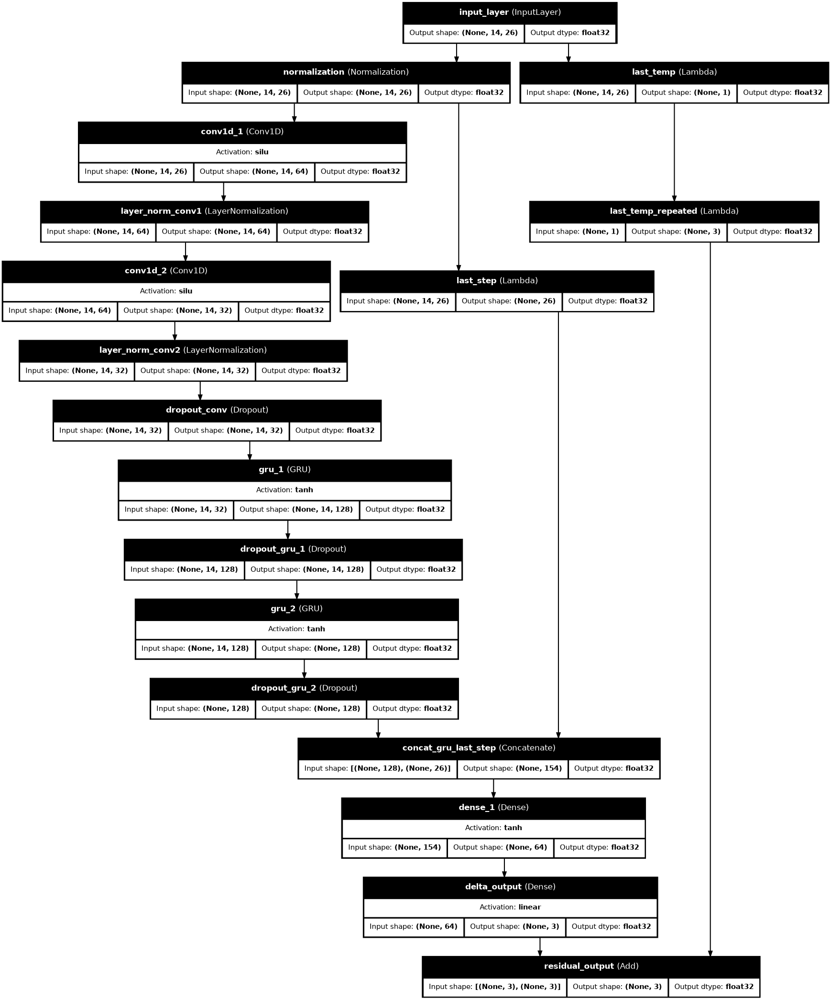

In [31]:
# Modelo 4: Conv1D + GRU residual
model_name = MULTIVARIATE_MODELS[3]

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

target_col_idx = df_multi.columns.get_loc('Temp')

# Normalización de las variables
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

inputs = keras.layers.Input(shape=inputs_shape)

inputs_norm = normalizer(inputs)

# Última temperatura observada en escala real
last_temp = layers.Lambda(
    lambda x: x[:, -1, target_col_idx:target_col_idx + 1], name='last_temp'
)(inputs)

# Se repite la última temperatura para crear una base para t+1, t+2 y t+3
last_temp_repeated = layers.Lambda(
    lambda x: tf.repeat(x, repeats=future, axis=1), name='last_temp_repeated'
)(last_temp)

# Último paso normalizado
last_step = layers.Lambda(lambda x: x[:, -1, :], name='last_step')(inputs_norm)

# Bloque Conv1D
conv_1 = layers.Conv1D(64, 3, padding='causal', activation='swish', name='conv1d_1')(inputs_norm)
norm_conv_1 = layers.LayerNormalization(name='layer_norm_conv1')(conv_1)

conv_2 = layers.Conv1D(32, 3, padding='causal', activation='swish', name='conv1d_2')(norm_conv_1)
norm_conv_2 = layers.LayerNormalization(name='layer_norm_conv2')(conv_2)
drop_conv = layers.Dropout(0.1, name='dropout_conv')(norm_conv_2)

# Bloque GRU
gru_1 = layers.GRU(128, return_sequences=True, name='gru_1')(drop_conv)
drop_1 = layers.Dropout(0.1, name='dropout_gru_1')(gru_1)

gru_2 = layers.GRU(128, return_sequences=False, name='gru_2')(drop_1)
drop_2 = layers.Dropout(0.05, name='dropout_gru_2')(gru_2)

# Unión RNN-last_step
concat = layers.Concatenate(name='concat_gru_last_step')([drop_2, last_step])

dense_1 = layers.Dense(64, activation='tanh', name='dense_1')(concat)

# El modelo aprende el cambio a partir la última temperatura observada
delta = layers.Dense(
    future,
    kernel_initializer=tf.initializers.zeros(),
    bias_initializer=tf.initializers.zeros(),
    name='delta_output'
)(dense_1)

# Salida residual: última temperatura observada + cambio estimado
outputs = layers.Add(name='residual_output')([last_temp_repeated, delta])

model_residual_gru = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

optimizer = keras.optimizers.AdamW(learning_rate=0.0005, weight_decay=1e-5, clipnorm=1.0)

model_residual_gru.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_residual_gru.summary()

tf.keras.utils.plot_model(
    model_residual_gru,
    to_file=str(IMAGES_DIR / '07_arquitectura_modelo_4_residual_gru.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

#### 5.5.1. Entrenamiento y evaluación

In [32]:
history_residual_gru, checkpoint_residual_gru = train_model(
    model_residual_gru, model_name, X_train, y_train, X_val, y_val
)


Entrenando · Conv1D + GRU residual
Epoch 1/200


 1/75 ━━━━━━━━━━━━━━━━━━━━ 2:32 2s/step - loss: 15.7584 - mae: 2.9135 - rmse: 3.9697

 3/75 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 14.3356 - mae: 2.8406 - rmse: 3.7836

 5/75 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 13.3559 - mae: 2.7573 - rmse: 3.6491

 7/75 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 12.8803 - mae: 2.7190 - rmse: 3.5834

...

70/75 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 4.6210 - mae: 1.6988 - rmse: 2.1489

72/75 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 4.6232 - mae: 1.6991 - rmse: 2.1494

74/75 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 4.6253 - mae: 1.6994 - rmse: 2.1499

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 4.6894 - mae: 1.7069 - rmse: 2.1655 - val_loss: 9.4525 - val_mae: 2.4047 - val_rmse: 3.0745 - learning_rate: 2.5000e-04



Entrenamiento finalizado · Conv1D + GRU residual
Épocas ejecutadas: 13
Mejor época según val_loss: 3
MAE de validación en el checkpoint: 2.1102
Tiempo de entrenamiento: 26.29 s


In [33]:
results_residual_gru = evaluar_modelo(
    model_residual_gru, model_name, checkpoint_residual_gru, X_test, y_test
)

step_metrics_residual_gru, y_pred_residual_gru = evaluar_steps(
    model_residual_gru, model_name, X_test, y_test
)

modelo_residual_gru
Test MSE: 6.068093776702881
Test RMSE: 2.4633500576019287
Test MAE: 1.911936640739441



Step t+1:
MSE: 4.9173056570135625
RMSE: 2.217499866293922
MAE: 1.750162200295963

Step t+2:
MSE: 6.464552186780647
RMSE: 2.542548364688595
MAE: 1.9587504403448257

Step t+3:
MSE: 6.822422359161914
RMSE: 2.611976714896577
MAE: 2.0268977651084636



El modelo Conv1D + GRU residual obtiene un `Test MSE` de `6.0682`, un `RMSE` de `2.4634` y un `MAE` de `1.9120`.

Por horizonte, el `MAE` es `1.7502` en `t+1`, `1.9588` en `t+2` y `2.0269` en `t+3`.

La formulación residual evaluada no mejora el rendimiento global de las configuraciones directas. Aunque `t+1` mantiene un error competitivo, la degradación es mayor conforme aumenta el horizonte.

### 5.6. Modelo 5 · Conv1D + LSTM residual

El quinto modelo prueba la misma idea residual, pero utilizando LSTM en lugar de GRU. El objetivo es comprobar si una celda recurrente con mayor capacidad de memoria puede aprovechar mejor la estructura residual.

La arquitectura mantiene el bloque convolucional inicial para detectar patrones locales y utiliza capas LSTM para procesar la secuencia temporal. Al igual que en el modelo residual anterior, se extrae la última temperatura observada en escala real y se repite como base para los tres horizontes futuros.

La red aprende un vector de cambios (`delta`) y la predicción final se obtiene sumando ese cambio a la última temperatura observada. De esta forma, el modelo no predice directamente la temperatura absoluta, sino una modificación respecto al valor más reciente.

Model: "modelo_residual_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 14, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 14, 26)    │         53 │ input_layer[0][0] │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 14, 64)    │      5,056 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv1    │ (None, 14, 64)    │        128 │ conv1d_1[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 14, 32)    │      6,176 │ layer_norm_conv1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_norm_conv2    │ (None, 14, 32)    │         64 │ conv1d_2[0][0]    │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_conv        │ (None, 14, 32)    │          0 │ layer_norm_conv2… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 14, 128)   │     82,432 │ dropout_conv[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_lstm_1      │ (None, 14, 128)   │          0 │ lstm_1[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 128)       │    131,584 │ dropout_lstm_1[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_lstm_2      │ (None, 128)       │          0 │ lstm_2[0][0]      │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_step (Lambda)  │ (None, 26)        │          0 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concat_lstm_last_s… │ (None, 154)       │          0 │ dropout_lstm_2[0… │
│ (Concatenate)       │                   │            │ last_step[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_temp (Lambda)  │ (None, 1)         │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      9,920 │ concat_lstm_last… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_temp_repeated  │ (None, 3)         │          0 │ last_temp[0][0]   │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ delta_output        │ (None, 3)         │        195 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_output     │ (None, 3)         │          0 │ last_temp_repeat… │
│ (Add)               │                   │            │ delta_output[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 235,608 (920.35 KB)

 Trainable params: 235,555 (920.14 KB)

 Non-trainable params: 53 (216.00 B)

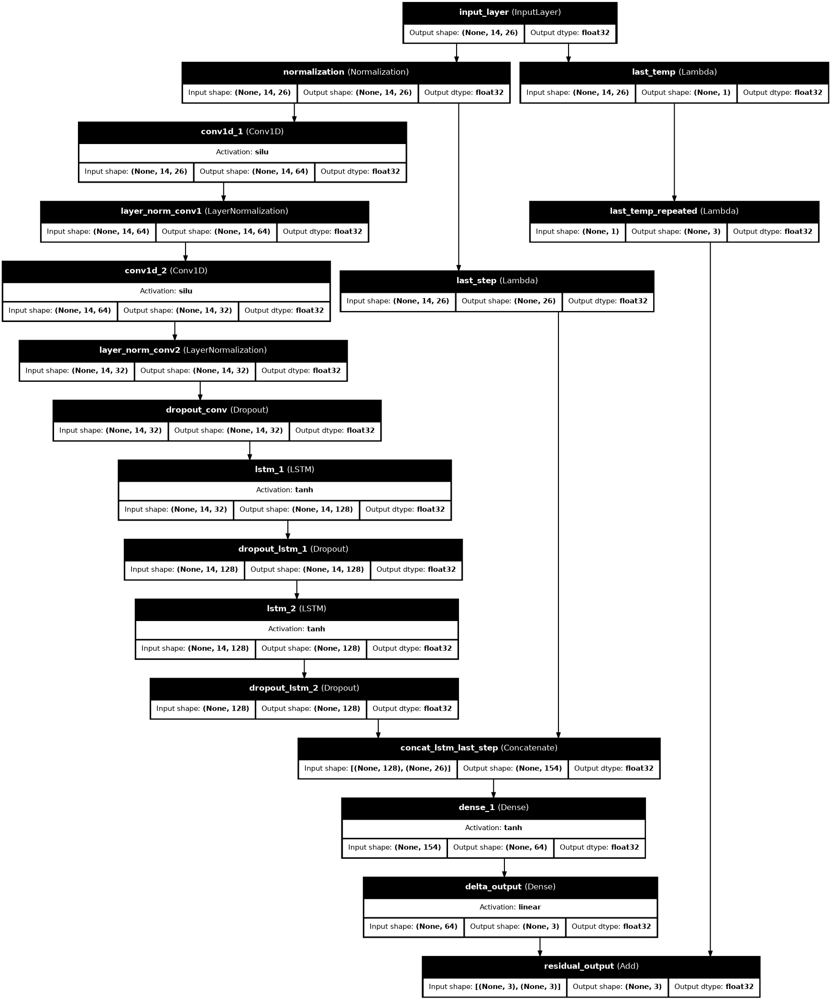

In [34]:
# Modelo 5: Conv1D + LSTM residual
model_name = MULTIVARIATE_MODELS[4]

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

target_col_idx = df_multi.columns.get_loc('Temp')

# Normalización de las variables
normalizer = layers.Normalization(axis=-1)
normalizer.adapt(X_train)

inputs = keras.layers.Input(shape=inputs_shape)

inputs_norm = normalizer(inputs)

# Última temperatura observada en escala real
last_temp = layers.Lambda(
    lambda x: x[:, -1, target_col_idx:target_col_idx + 1], name='last_temp'
)(inputs)

# Se repite la última temperatura para crear una base para t+1, t+2 y t+3
last_temp_repeated = layers.Lambda(
    lambda x: tf.repeat(x, repeats=future, axis=1), name='last_temp_repeated'
)(last_temp)

# Último paso normalizado
last_step = layers.Lambda(lambda x: x[:, -1, :], name='last_step')(inputs_norm)

# Bloque Conv1D
conv_1 = layers.Conv1D(64, 3, padding='causal', activation='swish', name='conv1d_1')(inputs_norm)
norm_conv_1 = layers.LayerNormalization(name='layer_norm_conv1')(conv_1)

conv_2 = layers.Conv1D(32, 3, padding='causal', activation='swish', name='conv1d_2')(norm_conv_1)
norm_conv_2 = layers.LayerNormalization(name='layer_norm_conv2')(conv_2)

drop_conv = layers.Dropout(0.1, name='dropout_conv')(norm_conv_2)

# Bloque lstm
lstm_1 = layers.LSTM(128, return_sequences=True, name='lstm_1')(drop_conv)
drop_1 = layers.Dropout(0.1, name='dropout_lstm_1')(lstm_1)

lstm_2 = layers.LSTM(128, return_sequences=False, name='lstm_2')(drop_1)
drop_2 = layers.Dropout(0.05, name='dropout_lstm_2')(lstm_2)

# Unión RNN-last_step
concat = layers.Concatenate(name='concat_lstm_last_step')([drop_2, last_step])

dense_1 = layers.Dense(64, activation='tanh', name='dense_1')(concat)

# El modelo aprende el cambio respecto a la última temperatura observada
delta = layers.Dense(
    future,
    kernel_initializer=tf.initializers.zeros(),
    bias_initializer=tf.initializers.zeros(),
    name='delta_output'
)(dense_1)

# Salida residual: última temperatura observada + cambio estimado
outputs = layers.Add(name='residual_output')([last_temp_repeated, delta])

model_residual_lstm = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

optimizer = keras.optimizers.AdamW(learning_rate=0.0005, weight_decay=1e-5, clipnorm=1.0)

model_residual_lstm.compile(
    optimizer=optimizer, loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_residual_lstm.summary()

tf.keras.utils.plot_model(
    model_residual_lstm,
    to_file=str(IMAGES_DIR / '08_arquitectura_modelo_5_residual_lstm.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

#### 5.6.1. Entrenamiento y evaluación

In [35]:
history_residual_lstm, checkpoint_residual_lstm = train_model(
    model_residual_lstm, model_name, X_train, y_train, X_val, y_val
)


Entrenando · Conv1D + LSTM residual
Epoch 1/200


 1/75 ━━━━━━━━━━━━━━━━━━━━ 3:03 2s/step - loss: 15.7584 - mae: 2.9135 - rmse: 3.9697

 3/75 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 14.3354 - mae: 2.8406 - rmse: 3.7836

 5/75 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - loss: 13.3558 - mae: 2.7573 - rmse: 3.6491

 7/75 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 12.8801 - mae: 2.7190 - rmse: 3.5834

...

68/75 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 4.6835 - mae: 1.6971 - rmse: 2.1632

71/75 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 4.6855 - mae: 1.6975 - rmse: 2.1637

73/75 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 4.6866 - mae: 1.6977 - rmse: 2.1640

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 4.7160 - mae: 1.7040 - rmse: 2.1716 - val_loss: 9.1959 - val_mae: 2.3974 - val_rmse: 3.0325 - learning_rate: 2.5000e-04



Entrenamiento finalizado · Conv1D + LSTM residual
Épocas ejecutadas: 13
Mejor época según val_loss: 3
MAE de validación en el checkpoint: 2.1036
Tiempo de entrenamiento: 27.50 s


In [36]:
results_residual_lstm = evaluar_modelo(
    model_residual_lstm, model_name, checkpoint_residual_lstm, X_test, y_test
)

step_metrics_residual_lstm, y_pred_residual_lstm = evaluar_steps(
    model_residual_lstm, model_name, X_test, y_test
)

modelo_residual_lstm
Test MSE: 6.013054370880127
Test RMSE: 2.452152967453003
Test MAE: 1.9097392559051514



Step t+1:
MSE: 4.912179032343253
RMSE: 2.216343617840711
MAE: 1.7339353353067153

Step t+2:
MSE: 6.438180707357274
RMSE: 2.537357031904906
MAE: 1.9744629686939228

Step t+3:
MSE: 6.688804726180463
RMSE: 2.5862723611755323
MAE: 2.020819658736701



El modelo Conv1D + LSTM residual obtiene un `Test MSE` de `6.0130`, un `RMSE` de `2.4521` y un `MAE` de `1.9097`.

Por horizonte obtiene un `MAE` de `1.7339` en `t+1`, `1.9744` en `t+2` y `2.0208` en `t+3`.

Esta variante mejora ligeramente al residual con GRU en el resultado global, pero tampoco supera a las configuraciones directas. En este experimento, imponer explícitamente la predicción como una corrección sobre la última temperatura observada no aporta una ventaja global.

### 5.7. Arquitecturas de dos ramas

Las dos últimas configuraciones exploran una estrategia distinta a las arquitecturas anteriores: dividir el problema en dos representaciones complementarias que se procesan de forma independiente antes de generar la predicción final.

La primera rama recibe exclusivamente la **serie histórica de temperatura**, mientras que la segunda procesa las **variables temporales y estadísticas derivadas** de esa misma serie.

Cada rama genera su propia representación y una predicción independiente para `t+1`, `t+2` y `t+3`. Posteriormente, ambas predicciones se combinan mediante un mecanismo de unión ponderada cuyo peso `α` se aprende durante el entrenamiento.

Aunque las arquitecturas de dos ramas incorporan explícitamente el último estado observado, no utilizan una formulación residual.

En los Modelos 4 y 5 la salida se define como la última temperatura observada más una corrección aprendida (`última temperatura + Δ`). En cambio, en los Modelos 6 y 7 el último estado se incorpora únicamente como información adicional dentro de la representación de cada rama y la red continúa generando directamente los valores absolutos de `t+1`, `t+2` y `t+3`.

Por tanto, el uso del último valor observado como característica explícita no impone la restricción residual evaluada anteriormente.

Se evalúan dos versiones de esta arquitectura: una primera configuración y una segunda versión con mayor capacidad de representación.

#### 5.7.1. Modelo 6 · Dos ramas con unión ponderada

La primera arquitectura de dos ramas establece una configuración relativamente compacta para comprobar si la separación entre la serie original de temperatura y las variables derivadas aporta información complementaria.

La **rama de la serie** procesa los 14 valores históricos de temperatura mediante capas `Conv1D` y GRU.

La **rama de variables derivadas** procesa, durante la misma ventana temporal, las variables de estacionalidad, retardos, diferencias, estadísticas móviles, medias exponenciales y referencias históricas mediante capas `Conv1D` y LSTM.

Cada rama genera una predicción independiente para los tres horizontes y ambas se combinan mediante:

`predicción = α · predicción_serie + (1 − α) · predicción_derivadas`

El valor de `α` se aprende de forma independiente para cada muestra y horizonte.

Model: "modelo_dos_ramas"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada_multivaria… │ (None, 14, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entrada_variables_… │ (None, 14, 25)    │          0 │ entrada_multivar… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalizacion_vari… │ (None, 14, 25)    │         51 │ entrada_variable… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_conv1d_1  │ (None, 14, 64)    │      4,864 │ normalizacion_va… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entrada_serie       │ (None, 14, 1)     │          0 │ entrada_multivar… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_norm_1    │ (None, 14, 64)    │        128 │ derivadas_conv1d… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalizacion_serie │ (None, 14, 1)     │          3 │ entrada_serie[0]… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_conv1d_2  │ (None, 14, 32)    │      6,176 │ derivadas_norm_1… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_conv1d_1      │ (None, 14, 32)    │        128 │ normalizacion_se… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_norm_2    │ (None, 14, 32)    │         64 │ derivadas_conv1d… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_layer_norm_1  │ (None, 14, 32)    │         64 │ serie_conv1d_1[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_lstm_1    │ (None, 14, 96)    │     49,536 │ derivadas_norm_2… │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_conv1d_2      │ (None, 14, 32)    │      3,104 │ serie_layer_norm… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_dropout_1 │ (None, 14, 96)    │          0 │ derivadas_lstm_1… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_layer_norm_2  │ (None, 14, 32)    │         64 │ serie_conv1d_2[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_lstm_2    │ (None, 64)        │     41,216 │ derivadas_dropou… │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_ultima    │ (None, 25)        │          0 │ normalizacion_va

 Total params: 144,895 (566.00 KB)

 Trainable params: 144,841 (565.79 KB)

 Non-trainable params: 54 (224.00 B)

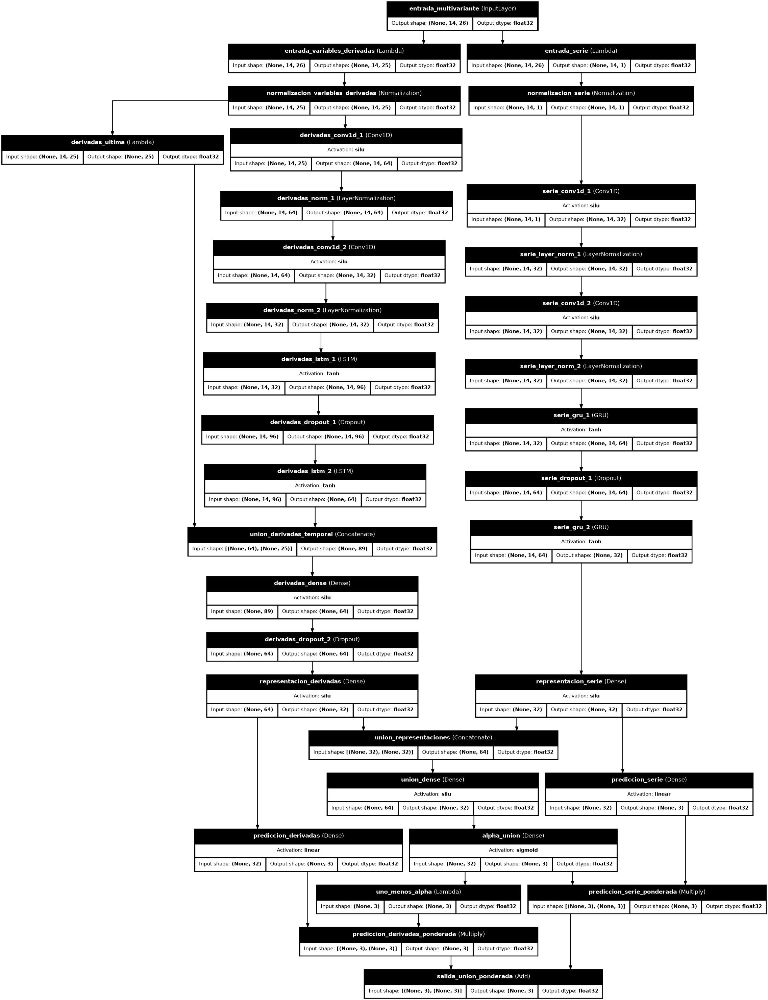

In [37]:
# Modelo 6: dos ramas con unión ponderada
model_name = MULTIVARIATE_MODELS[5]

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

target_col_idx = df_multi.columns.get_loc('Temp')

derived_indices = [i for i, columna in enumerate(df_multi.columns) if columna != 'Temp']

# =========================================================
# NORMALIZACIÓN ESPECÍFICA DE CADA RAMA
# =========================================================
normalizer_temp = layers.Normalization(axis=-1, name='normalizacion_serie')
normalizer_temp.adapt(X_train[:, :, target_col_idx:target_col_idx + 1])

normalizer_derived = layers.Normalization(axis=-1, name='normalizacion_variables_derivadas')
normalizer_derived.adapt(X_train[:, :, derived_indices])

# =========================================================
# ENTRADA COMÚN
# =========================================================
inputs = keras.layers.Input(shape=inputs_shape, name='entrada_multivariante')

# =========================================================
# RAMA 1 · SERIE ORIGINAL DE TEMPERATURA
# =========================================================
temp_sequence = layers.Lambda(
    lambda x: x[:, :, target_col_idx:target_col_idx + 1],
    output_shape=(inputs_shape[0], 1),
    name='entrada_serie'
)(inputs)

temp_norm = normalizer_temp(temp_sequence)

temp_conv_1 = layers.Conv1D(
    32, 3, padding='causal', activation='swish', name='serie_conv1d_1'
)(temp_norm)
norm_temp_conv_1 = layers.LayerNormalization(name='serie_layer_norm_1')(temp_conv_1)

temp_conv_2 = layers.Conv1D(
    32, 3, padding='causal', activation='swish', name='serie_conv1d_2'
)(norm_temp_conv_1)
norm_temp_conv_2 = layers.LayerNormalization(name='serie_layer_norm_2')(temp_conv_2)

temp_gru_1 = layers.GRU(64, return_sequences=True, name='serie_gru_1')(norm_temp_conv_2)
drop_temp_gru_1 = layers.Dropout(0.05, name='serie_dropout_1')(temp_gru_1)

temp_gru_2 = layers.GRU(32, return_sequences=False, name='serie_gru_2')(drop_temp_gru_1)

representacion_serie = layers.Dense(32, activation='swish', name='representacion_serie')(temp_gru_2)

# =========================================================
# RAMA 2 · VARIABLES DERIVADAS TEMPORALES Y ESTADÍSTICAS
# =========================================================
derived_sequence = layers.Lambda(
    lambda x: tf.gather(x, derived_indices, axis=-1),
    output_shape=(inputs_shape[0], len(derived_indices)),
    name='entrada_variables_derivadas'
)(inputs)

derived_norm = normalizer_derived(derived_sequence)

derived_conv_1 = layers.Conv1D(
    64, 3, padding='causal', activation='swish', name='derivadas_conv1d_1'
)(derived_norm)

norm_derived_conv_1 = layers.LayerNormalization(name='derivadas_norm_1')(derived_conv_1)

derived_conv_2 = layers.Conv1D(
    32, 3, padding='causal', activation='swish', name='derivadas_conv1d_2'
)(norm_derived_conv_1)
norm_derived_conv_2 = layers.LayerNormalization(name='derivadas_norm_2')(derived_conv_2)

derived_lstm_1 = layers.LSTM(
    96, return_sequences=True, name='derivadas_lstm_1'
)(norm_derived_conv_2)
drop_derived_lstm_1 = layers.Dropout(0.05, name='derivadas_dropout_1')(derived_lstm_1)

derived_lstm_2 = layers.LSTM(
    64, return_sequences=False, name='derivadas_lstm_2'
)(drop_derived_lstm_1)

# Estado variables derivadas más reciente
derived_last = layers.Lambda(
    lambda x: x[:, -1, :],
    output_shape=(len(derived_indices),),
    name='derivadas_ultima'
)(derived_norm)

union_derivadas = layers.Concatenate(
    name='union_derivadas_temporal'
)([derived_lstm_2, derived_last])

derived_dense = layers.Dense(64, activation='swish', name='derivadas_dense')(union_derivadas)
drop_derived_dense = layers.Dropout(0.05, name='derivadas_dropout_2')(derived_dense)

representacion_derivadas = layers.Dense(
    32, activation='swish', name='representacion_derivadas'
)(drop_derived_dense)

# =========================================================
# PREDICCIÓN INDEPENDIENTE DE CADA RAMA
# =========================================================
prediccion_serie = layers.Dense(future, name='prediccion_serie')(representacion_serie)

prediccion_derivadas = layers.Dense(future, name='prediccion_derivadas')(representacion_derivadas)

# =========================================================
# UNIÓN MEDIANTE α
# =========================================================
union_salidas = layers.Concatenate(
    name='union_representaciones'
)([representacion_serie, representacion_derivadas])

union_dense = layers.Dense(32, activation='swish', name='union_dense')(union_salidas)

alpha = layers.Dense(
    future, activation='sigmoid', kernel_initializer='zeros', bias_initializer='zeros',
    name='alpha_union'
)(union_dense)

uno_menos_alpha = layers.Lambda(lambda x: 1.0 - x, name='uno_menos_alpha')(alpha)

prediccion_serie_ponderada = layers.Multiply(
    name='prediccion_serie_ponderada'
)([alpha, prediccion_serie])

prediccion_derivadas_ponderada = layers.Multiply(
    name='prediccion_derivadas_ponderada'
)([uno_menos_alpha, prediccion_derivadas])

outputs = layers.Add(
    name='salida_union_ponderada'
)([prediccion_serie_ponderada, prediccion_derivadas_ponderada])

# =========================================================
# MODELO
# =========================================================
model_dos_ramas = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

optimizer = keras.optimizers.AdamW(learning_rate=0.0005, weight_decay=1e-5, clipnorm=1.0)

model_dos_ramas.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_dos_ramas.summary()

tf.keras.utils.plot_model(
    model_dos_ramas,
    to_file=str(IMAGES_DIR / '09_arquitectura_modelo_6_dos_ramas.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

#### 5.7.2. Entrenamiento y evaluación del modelo 6

El modelo se entrena mediante el mismo esquema temporal `TRAIN–VALIDACIÓN–TEST` empleado en las configuraciones anteriores.

Se utiliza `AdamW` con `learning_rate=0.0005`, `weight_decay=1e-5` y `clipnorm=1.0`, junto con los callbacks comunes definidos al inicio del proyecto.

La pérdida de entrenamiento continúa siendo `MSE` y la arquitectura se incorpora al mismo procedimiento de evaluación global y por horizonte utilizado para el resto de modelos.

In [38]:
history_dos_ramas, checkpoint_dos_ramas = train_model(
    model_dos_ramas, model_name, X_train, y_train, X_val, y_val
)


Entrenando · Dos ramas · serie + derivadas
Epoch 1/200


 1/75 ━━━━━━━━━━━━━━━━━━━━ 6:21 5s/step - loss: 126.8607 - mae: 10.4921 - rmse: 11.2632

 3/75 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 134.0248 - mae: 10.8202 - rmse: 11.5748

 5/75 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 134.7698 - mae: 10.8464 - rmse: 11.6077

 7/75 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 134.5050 - mae: 10.8376 - rmse: 11.5966

...

71/75 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 6.3398 - mae: 1.9921 - rmse: 2.5172

73/75 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 6.3402 - mae: 1.9923 - rmse: 2.5173

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 6.3407 - mae: 1.9925 - rmse: 2.5174

75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - loss: 6.3530 - mae: 1.9968 - rmse: 2.5205 - val_loss: 7.3542 - val_mae: 2.1344 - val_rmse: 2.7119 - learning_rate: 2.5000e-04



Entrenamiento finalizado · Dos ramas · serie + derivadas
Épocas ejecutadas: 14
Mejor época según val_loss: 4
MAE de validación en el checkpoint: 2.0118
Tiempo de entrenamiento: 50.08 s


In [39]:
results_dos_ramas = evaluar_modelo(
    model_dos_ramas, model_name, checkpoint_dos_ramas, X_test, y_test
)

step_metrics_dos_ramas, y_pred_dos_ramas = evaluar_steps(
    model_dos_ramas, model_name, X_test, y_test
)

modelo_dos_ramas
Test MSE: 5.719860076904297
Test RMSE: 2.39162278175354
Test MAE: 1.858700156211853



Step t+1:
MSE: 4.736722150508416
RMSE: 2.176401192452443
MAE: 1.7140297075927446

Step t+2:
MSE: 6.0565515954313085
RMSE: 2.461006216048897
MAE: 1.8996875791519596

Step t+3:
MSE: 6.366306424951821
RMSE: 2.5231540628649336
MAE: 1.9623830098835073



El Modelo 6 obtiene un `MAE` de validación de `2.0242`. Sobre el conjunto de test alcanza un `MSE` de `5.8042`, un `RMSE` de `2.4092` y un `MAE` de `1.8767`.

Por horizonte de predicción obtiene un `MAE` de `1.7336` en `t+1`, `1.9292` en `t+2` y `1.9673` en `t+3`.

La primera arquitectura de dos ramas mejora el `MAE` de validación de todas las configuraciones de una sola rama evaluadas anteriormente. Este resultado justifica estudiar una segunda versión con mayor capacidad de representación y un mecanismo de unión más elaborado.

#### 5.7.3. Modelo 7 · Dos ramas ampliadas con unión ponderada

A partir de la arquitectura anterior se desarrolla una segunda configuración de dos ramas con mayor capacidad de representación.

Se mantiene la separación entre:

- la **rama de la serie de temperatura**, centrada exclusivamente en la evolución de la señal original;
- la **rama de variables derivadas**, que procesa las características temporales y estadísticas construidas a partir de la serie.

La rama de temperatura amplía el procesamiento convolucional mediante tres capas `Conv1D` de 64, 32 y 16 filtros. Posteriormente utiliza dos capas GRU de 64 y 32 unidades. A diferencia del Modelo 6, la representación recurrente se combina además con la última temperatura observada antes de generar una representación densa de 64 unidades.

La rama de variables derivadas aumenta de forma más notable su capacidad. Utiliza tres capas `Conv1D` de 96, 64 y 64 filtros y tres capas LSTM de 96, 64 y 32 unidades. La representación temporal obtenida se combina con las variables derivadas correspondientes al último instante observado y posteriormente se procesa mediante capas densas de 96 y 64 unidades.

Cada rama genera una predicción independiente para `t+1`, `t+2` y `t+3`.

| Componente | Modelo 6 | Modelo 7 |
|---|---|---|
| Serie · Conv1D | 32 → 32 | 64 → 32 → 16 |
| Serie · recurrente | GRU 64 → 32 | GRU 64 → 32 |
| Última temperatura explícita | No | Sí |
| Representación serie | Dense 32 | Dense 64 |
| Derivadas · Conv1D | 64 → 32 | 96 → 64 → 64 |
| Derivadas · recurrente | LSTM 96 → 64 | LSTM 96 → 64 → 32 |
| Último estado de derivadas | Sí | Sí |
| Representación derivadas | Dense 64 → 32 | Dense 96 → 64 |
| Entrada para `α` | Representaciones | Representaciones + predicciones |
| `learning_rate` | `5e-4` | `5e-4` |
| Unión | Ponderada por horizonte | Ponderada por horizonte |

El mecanismo encargado de aprender `α` recibe tanto las representaciones internas de ambas ramas como sus respectivas predicciones. De este modo, la ponderación puede depender simultáneamente de la información aprendida y de la propuesta de predicción realizada por cada rama.

La salida final continúa definiéndose como:

`predicción = α · predicción_serie + (1 − α) · predicción_derivadas`

con un valor de `α` independiente para cada muestra y horizonte.

Model: "modelo_dos_ramas_ampliado"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada_multivaria… │ (None, 14, 26)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entrada_variables_… │ (None, 14, 25)    │          0 │ entrada_multivar… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalizacion_vari… │ (None, 14, 25)    │         51 │ entrada_variable… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_conv1d_1  │ (None, 14, 96)    │      7,296 │ normalizacion_va… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_norm_1    │ (None, 14, 96)    │        192 │ derivadas_conv1d… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ entrada_serie       │ (None, 14, 1)     │          0 │ entrada_multivar… │
│ (Lambda)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_conv1d_2  │ (None, 14, 64)    │     18,496 │ derivadas_norm_1… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalizacion_serie │ (None, 14, 1)     │          3 │ entrada_serie[0]… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_norm_2    │ (None, 14, 64)    │        128 │ derivadas_conv1d… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_conv1d_1      │ (None, 14, 64)    │        256 │ normalizacion_se… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_conv1d_3  │ (None, 14, 64)    │     12,352 │ derivadas_norm_2… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_norm_1        │ (None, 14, 64)    │        128 │ serie_conv1d_1[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_norm_3    │ (None, 14, 64)    │        128 │ derivadas_conv1d… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_conv1d_2      │ (None, 14, 32)    │      6,176 │ serie_norm_1[0][… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_dropout_… │ (None, 14, 64)    │          0 │ derivadas_norm_3… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ serie_norm_2        │ (None, 14, 32)    │         64 │ serie_conv1d_2[0… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ derivadas_lstm_1    │ (None, 14, 96)    │     61,824 │ derivadas_dropou

 Total params: 206,223 (805.57 KB)

 Trainable params: 206,169 (805.35 KB)

 Non-trainable params: 54 (224.00 B)

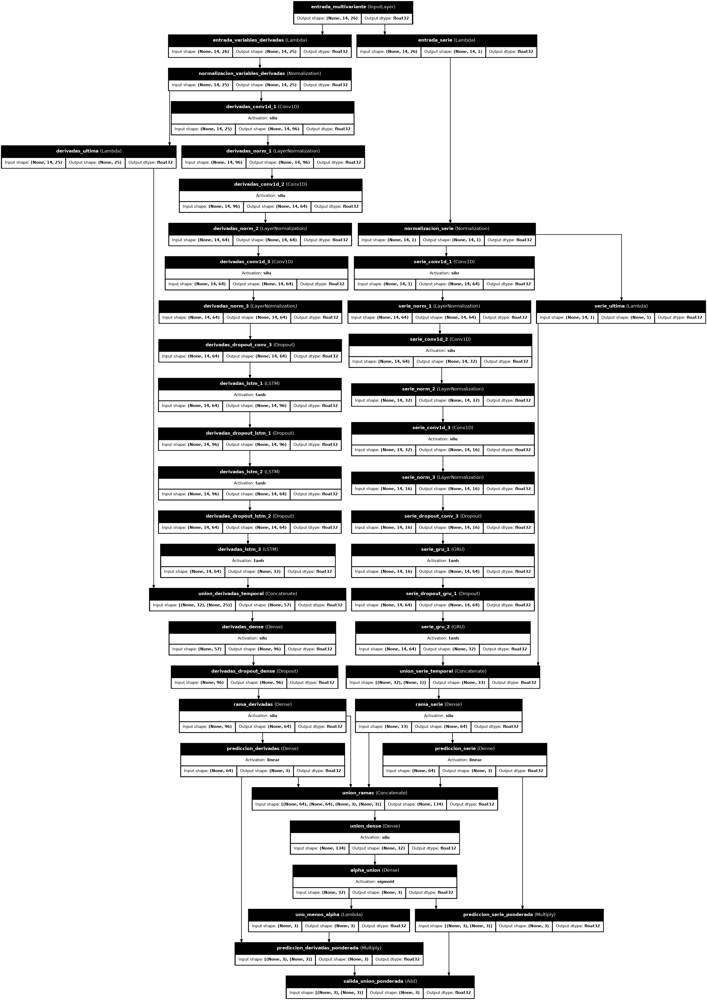

In [40]:
# Modelo 7: dos ramas ampliadas con unión ponderada
model_name = MULTIVARIATE_MODELS[6]

keras.backend.clear_session()
keras.utils.set_random_seed(semilla)

inputs_shape = (X_train.shape[1], X_train.shape[2])

target_col_idx = df_multi.columns.get_loc('Temp')

derived_indices = [i for i, columna in enumerate(df_multi.columns) if columna != 'Temp']

# =========================================================
# NORMALIZACIÓN ESPECÍFICA DE CADA RAMA
# =========================================================
normalizer_temp = layers.Normalization(axis=-1, name='normalizacion_serie')

normalizer_temp.adapt(X_train[:, :, target_col_idx:target_col_idx + 1])

normalizer_derived = layers.Normalization(axis=-1, name='normalizacion_variables_derivadas')

normalizer_derived.adapt(X_train[:, :, derived_indices])

# =========================================================
# ENTRADA COMÚN
# =========================================================
inputs = keras.layers.Input(shape=inputs_shape, name='entrada_multivariante')

# =========================================================
# RAMA 1 · SERIE ORIGINAL DE TEMPERATURA
# =========================================================
temp_sequence = layers.Lambda(
    lambda x: x[:, :, target_col_idx:target_col_idx + 1],
    output_shape=(inputs_shape[0], 1),
    name='entrada_serie'
)(inputs)

temp_norm = normalizer_temp(temp_sequence)

# Última temperatura normalizada
temp_last = layers.Lambda(lambda x: x[:, -1, :], name='serie_ultima')(temp_norm)

temp_conv_1 = layers.Conv1D(
    64, 3, padding='causal', activation='swish', name='serie_conv1d_1'
)(temp_norm)
norm_temp_conv_1 = layers.LayerNormalization(name='serie_norm_1')(temp_conv_1)

temp_conv_2 = layers.Conv1D(
    32, 3, padding='causal', activation='swish', name='serie_conv1d_2'
)(norm_temp_conv_1)
norm_temp_conv_2 = layers.LayerNormalization(name='serie_norm_2')(temp_conv_2)

temp_conv_3 = layers.Conv1D(
    16, 3, padding='causal', activation='swish', name='serie_conv1d_3'
)(norm_temp_conv_2)
norm_temp_conv_3 = layers.LayerNormalization(name='serie_norm_3')(temp_conv_3)
drop_temp_conv_3 = layers.Dropout(0.05, name='serie_dropout_conv_3')(norm_temp_conv_3)

temp_gru_1 = layers.GRU(64, return_sequences=True, name='serie_gru_1')(drop_temp_conv_3)
drop_temp_gru_1 = layers.Dropout(0.10, name='serie_dropout_gru_1')(temp_gru_1)

temp_gru_2 = layers.GRU(32, return_sequences=False, name='serie_gru_2')(drop_temp_gru_1)

union_serie = layers.Concatenate(name='union_serie_temporal')([temp_gru_2, temp_last])

rama_serie = layers.Dense(64, activation='swish', name='rama_serie')(union_serie)

# =========================================================
# RAMA 2 · VARIABLES DERIVADAS TEMPORALES Y ESTADÍSTICAS
# =========================================================
derived_sequence = layers.Lambda(
    lambda x: tf.gather(x, derived_indices, axis=-1),
    output_shape=(inputs_shape[0], len(derived_indices)),
    name='entrada_variables_derivadas'
)(inputs)

derived_norm = normalizer_derived(derived_sequence)

# Derivada correspondiente al último instante
derived_last = layers.Lambda(
    lambda x: x[:, -1, :],
    output_shape=(len(derived_indices),),
    name='derivadas_ultima'
)(derived_norm)

derived_conv_1 = layers.Conv1D(
    96, 3, padding='causal', activation='swish', name='derivadas_conv1d_1'
)(derived_norm)
norm_derived_conv_1 = layers.LayerNormalization(name='derivadas_norm_1')(derived_conv_1)

derived_conv_2 = layers.Conv1D(
    64, 3, padding='causal', activation='swish', name='derivadas_conv1d_2'
)(norm_derived_conv_1)
norm_derived_conv_2 = layers.LayerNormalization(name='derivadas_norm_2')(derived_conv_2)

derived_conv_3 = layers.Conv1D(
    64, 3, padding='causal', activation='swish', name='derivadas_conv1d_3'
)(norm_derived_conv_2)
norm_derived_conv_3 = layers.LayerNormalization(name='derivadas_norm_3')(derived_conv_3)
drop_derived_conv_3 = layers.Dropout(0.10, name='derivadas_dropout_conv_3')(norm_derived_conv_3)

derived_lstm_1 = layers.LSTM(
    96, return_sequences=True, name='derivadas_lstm_1'
)(drop_derived_conv_3)
drop_derived_lstm_1 = layers.Dropout(0.10, name='derivadas_dropout_lstm_1')(derived_lstm_1)

derived_lstm_2 = layers.LSTM(
    64, return_sequences=True, name='derivadas_lstm_2'
)(drop_derived_lstm_1)
drop_derived_lstm_2 = layers.Dropout(0.05, name='derivadas_dropout_lstm_2')(derived_lstm_2)

derived_lstm_3 = layers.LSTM(
    32, return_sequences=False, name='derivadas_lstm_3'
)(drop_derived_lstm_2)

union_derivadas = layers.Concatenate(
    name='union_derivadas_temporal'
)([derived_lstm_3, derived_last])

derived_dense = layers.Dense(96, activation='swish', name='derivadas_dense')(union_derivadas)
drop_derived_dense = layers.Dropout(0.05, name='derivadas_dropout_dense')(derived_dense)

rama_derivadas = layers.Dense(
    64, activation='swish', name='rama_derivadas'
)(drop_derived_dense)

# =========================================================
# PREDICCIÓN INDEPENDIENTE DE CADA RAMA
# =========================================================
prediccion_serie = layers.Dense(future, name='prediccion_serie')(rama_serie)

prediccion_derivadas = layers.Dense(future, name='prediccion_derivadas')(rama_derivadas)

# =========================================================
# UNIÓN MEDIANTE α
# =========================================================
union_ramas = layers.Concatenate(
    name='union_ramas'
)([rama_serie, rama_derivadas, prediccion_serie, prediccion_derivadas])

union_dense = layers.Dense(32, activation='swish', name='union_dense')(union_ramas)

alpha = layers.Dense(
    future, activation='sigmoid', kernel_initializer='zeros', bias_initializer='zeros',
    name='alpha_union'
)(union_dense)

uno_menos_alpha = layers.Lambda(lambda x: 1.0 - x, name='uno_menos_alpha')(alpha)

prediccion_serie_ponderada = layers.Multiply(
    name='prediccion_serie_ponderada'
)([alpha, prediccion_serie])

prediccion_derivadas_ponderada = layers.Multiply(
    name='prediccion_derivadas_ponderada'
)([uno_menos_alpha, prediccion_derivadas])

outputs = layers.Add(
    name='salida_union_ponderada'
)([prediccion_serie_ponderada, prediccion_derivadas_ponderada])

# =========================================================
# MODELO
# =========================================================
model_dos_ramas_ampliado = keras.Model(inputs=inputs, outputs=outputs, name=model_name)

optimizer = keras.optimizers.AdamW(learning_rate=5e-4, weight_decay=1e-5, clipnorm=1.0)

model_dos_ramas_ampliado.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.MSE,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(name='rmse'),
        tf.keras.metrics.MeanAbsoluteError(name='mae')
    ]
)

model_dos_ramas_ampliado.summary()

tf.keras.utils.plot_model(
    model_dos_ramas_ampliado,
    to_file=str(IMAGES_DIR / '10_arquitectura_modelo_7_dos_ramas_ampliado.png'),
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True,
    show_dtype=True,
    dpi=75
)

#### 5.7.4. Entrenamiento y evaluación del modelo 7

El Modelo 7 mantiene el mismo esquema temporal `TRAIN–VALIDACIÓN–TEST` y el mismo procedimiento general de entrenamiento y evaluación utilizado en las arquitecturas anteriores.

Se emplea `AdamW` con `learning_rate=0.0005`, `weight_decay=1e-5` y `clipnorm=1.0`. La función de pérdida continúa siendo `MSE` y se registran también `RMSE` y `MAE`.

Los callbacks `ModelCheckpoint`, `ReduceLROnPlateau` y `EarlyStopping` monitorizan `val_loss`. Tras el entrenamiento se recuperan los mejores pesos, se registran las métricas de validación y se evalúa el modelo sobre test y de forma independiente para `t+1`, `t+2` y `t+3`.

El análisis interno de las dos ramas y del mecanismo de ponderación se realiza posteriormente utilizando exclusivamente el conjunto de validación.

In [41]:
history_dos_ramas_ampliado, checkpoint_dos_ramas_ampliado = train_model(
    model_dos_ramas_ampliado, model_name, X_train, y_train, X_val, y_val
)


Entrenando · Dos ramas ampliadas · serie + derivadas
Epoch 1/200


 1/75 ━━━━━━━━━━━━━━━━━━━━ 8:09 7s/step - loss: 127.3024 - mae: 10.5467 - rmse: 11.2828

 3/75 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - loss: 134.1028 - mae: 10.8603 - rmse: 11.5784

 5/75 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 134.7124 - mae: 10.8808 - rmse: 11.6054

 7/75 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - loss: 134.4011 - mae: 10.8694 - rmse: 11.5923

...

71/75 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 6.4106 - mae: 2.0092 - rmse: 2.5314

73/75 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 6.4107 - mae: 2.0092 - rmse: 2.5315

75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 6.4107 - mae: 2.0092 - rmse: 2.5315

75/75 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - loss: 6.4018 - mae: 2.0074 - rmse: 2.5302 - val_loss: 6.9544 - val_mae: 2.0743 - val_rmse: 2.6371 - learning_rate: 2.5000e-04



Entrenamiento finalizado · Dos ramas ampliadas · serie + derivadas
Épocas ejecutadas: 23
Mejor época según val_loss: 13
MAE de validación en el checkpoint: 2.0034
Tiempo de entrenamiento: 98.88 s


In [42]:
results_dos_ramas_ampliado = evaluar_modelo(
    model_dos_ramas_ampliado, model_name, checkpoint_dos_ramas_ampliado, X_test, y_test
)

step_metrics_dos_ramas_ampliado, y_pred_dos_ramas_ampliado = evaluar_steps(
    model_dos_ramas_ampliado, model_name, X_test, y_test
)

modelo_dos_ramas_ampliado
Test MSE: 5.652378559112549
Test RMSE: 2.3774731159210205
Test MAE: 1.8498538732528687



Step t+1:
MSE: 4.699551316029498
RMSE: 2.1678448551567286
MAE: 1.7048103723616257

Step t+2:
MSE: 6.034581077992666
RMSE: 2.4565384340556666
MAE: 1.901450915441904

Step t+3:
MSE: 6.223002643427618
RMSE: 2.494594685199906
MAE: 1.943300905438252



El Modelo 7 obtiene un `MAE` de validación de `2.0034`, el menor entre las siete arquitecturas multivariantes evaluadas.

Sobre test alcanza un `MSE` de `5.6523`, un `RMSE` de `2.3775` y un `MAE` de `1.8498`, obteniendo también el menor error global en este conjunto.

Por horizonte de predicción presenta un `MAE` de `1.7048` en `t+1`, `1.9015` en `t+2` y `1.9433` en `t+3`.

Conv1D + LSTM conserva una ligera ventaja en `t+1`, mientras que el Modelo 7 obtiene el menor `MAE` en `t+2` y `t+3`. El resultado global sitúa a la arquitectura ampliada de dos ramas como la configuración seleccionada mediante validación.

### 5.8. Análisis del aprendizaje en las arquitecturas de dos ramas

A diferencia de las arquitecturas anteriores, los modelos de dos ramas permiten inspeccionar directamente cómo se distribuye la información entre dos representaciones diferentes antes de obtener la predicción final.

El mecanismo de unión proporciona un valor `α` para cada muestra y horizonte:

`predicción = α · predicción_serie + (1 − α) · predicción_derivadas`

Por tanto:

- `α → 1` indica mayor contribución de la serie de temperatura;
- `α → 0` indica mayor contribución de las variables derivadas;
- valores intermedios representan una combinación de ambas.

Además de estudiar estos pesos, se analiza el rendimiento independiente de cada rama y se compara la ponderación aprendida con la mejor combinación fija posible sobre el conjunto de validación.

Este análisis permite estudiar no solo **qué modelo predice mejor**, sino también **cómo aprende a construir sus predicciones**.

#### 5.8.1. Contribución aprendida mediante α

Se analizan inicialmente los pesos `α` aprendidos por las dos arquitecturas de ramas utilizando exclusivamente el conjunto de validación.

La comparación permite observar si el aumento de capacidad del Modelo 7 modifica el equilibrio entre la información procedente directamente de la serie de temperatura y la información obtenida mediante las variables derivadas.

In [43]:
modelo_alpha_6 = keras.Model(
    inputs=model_dos_ramas.input,
    outputs=model_dos_ramas.get_layer('alpha_union').output
)

alpha_val_6 = modelo_alpha_6.predict(X_val, verbose=0)

modelo_alpha_7 = keras.Model(
    inputs=model_dos_ramas_ampliado.input,
    outputs=model_dos_ramas_ampliado.get_layer('alpha_union').output
)

alpha_val_7 = modelo_alpha_7.predict(X_val, verbose=0)

tabla_alpha_6 = pd.DataFrame(alpha_val_6, columns=['t+1', 't+2', 't+3'])
tabla_alpha_7 = pd.DataFrame(alpha_val_7, columns=['t+1', 't+2', 't+3'])

display(
    tabla_alpha_6.describe().loc[['mean', 'std', 'min', 'max']].round(4).style
    .set_caption('Modelo 6 · Dos ramas · Distribución de α')
)

display(
    tabla_alpha_7.describe().loc[['mean', 'std', 'min', 'max']].round(4).style
    .set_caption('Modelo 7 · Dos ramas ampliadas · Distribución de α')
)

,t+1,t+2,t+3
mean,0.180500,0.132400,0.266800
std,0.049500,0.054300,0.049200
min,0.101700,0.054800,0.181300
max,0.286100,0.257700,0.361500


,t+1,t+2,t+3
mean,0.371000,0.407600,0.065600
std,0.023600,0.018800,0.039900
min,0.315300,0.363300,0.016400
max,0.424600,0.447500,0.182200


In [44]:
comparacion_alpha = pd.DataFrame({
    'Modelo 6 · Dos ramas · t+1': tabla_alpha_6['t+1'],
    'Modelo 6 · Dos ramas · t+2': tabla_alpha_6['t+2'],
    'Modelo 6 · Dos ramas · t+3': tabla_alpha_6['t+3'],
    'Modelo 7 · Dos ramas ampliadas · t+1': tabla_alpha_7['t+1'],
    'Modelo 7 · Dos ramas ampliadas · t+2': tabla_alpha_7['t+2'],
    'Modelo 7 · Dos ramas ampliadas · t+3': tabla_alpha_7['t+3']
})

comparacion_alpha.mean().round(4).to_frame(name='α medio')

,α medio
Modelo 6 · Dos ramas · t+1,0.1805
Modelo 6 · Dos ramas · t+2,0.1324
Modelo 6 · Dos ramas · t+3,0.2668
Modelo 7 · Dos ramas ampliadas · t+1,0.3710
Modelo 7 · Dos ramas ampliadas · t+2,0.4076
Modelo 7 · Dos ramas ampliadas · t+3,0.0656


#### 5.8.2. Rendimiento de las ramas y validación de la ponderación

Para profundizar en el funcionamiento del Modelo 7 se recuperan las predicciones generadas por cada rama antes de aplicar la unión ponderada.

Las ramas no se interpretan como modelos independientes, ya que ambas se entrenan conjuntamente para optimizar la predicción final. Su evaluación aislada permite, sin embargo, comprobar cómo se especializan las dos representaciones y qué aporta posteriormente su combinación.

Para cada horizonte se comparan:

- el `MAE` de la rama de la serie de temperatura;
- el `MAE` de la rama de variables derivadas;
- el `MAE` de la unión adaptativa aprendida;
- el valor medio de `α` aprendido;
- el mejor `α` fijo posible sobre validación;
- el `MAE` obtenido mediante dicha ponderación fija.

La búsqueda del mejor peso fijo se utiliza únicamente como referencia diagnóstica. No interviene en el entrenamiento ni sustituye al mecanismo adaptativo aprendido por la red.

In [45]:
modelo_diagnostico_7 = keras.Model(
    inputs=model_dos_ramas_ampliado.input,
    outputs=[
        model_dos_ramas_ampliado.get_layer('prediccion_serie').output,
        model_dos_ramas_ampliado.get_layer('prediccion_derivadas').output,
        model_dos_ramas_ampliado.get_layer('alpha_union').output,
        model_dos_ramas_ampliado.output
    ]
)

pred_serie_val, pred_derivadas_val, alpha_val_7, pred_union_val = modelo_diagnostico_7.predict(
    X_val, verbose=0
)

alpha_grid = np.linspace(0.0, 1.0, 101)

resultados_ponderacion = []

for h in range(future):
    y_h = y_val[:, h]
    pred_serie_h = pred_serie_val[:, h]
    pred_derivadas_h = pred_derivadas_val[:, h]

    mae_serie = np.mean(np.abs(y_h - pred_serie_h))
    mae_derivadas = np.mean(np.abs(y_h - pred_derivadas_h))
    mae_union = np.mean(np.abs(y_h - pred_union_val[:, h]))

    maes_alpha = []

    for alpha_fijo in alpha_grid:
        pred_combinada = alpha_fijo * pred_serie_h + (1.0 - alpha_fijo) * pred_derivadas_h

        maes_alpha.append(np.mean(np.abs(y_h - pred_combinada)))

    idx_mejor = np.argmin(maes_alpha)

    resultados_ponderacion.append({
        'Future': f't+{h + 1}',
        'MAE serie': mae_serie,
        'MAE derivadas': mae_derivadas,
        'MAE unión adaptativa': mae_union,
        'α medio aprendido': alpha_val_7[:, h].mean(),
        'α fijo óptimo': alpha_grid[idx_mejor],
        'MAE α fijo óptimo': maes_alpha[idx_mejor]
    })

diagnostico_union_7 = pd.DataFrame(resultados_ponderacion)

diagnostico_union_7_display = diagnostico_union_7.style.hide(axis='index').format({
    'MAE serie': '{:.4f}', 'MAE derivadas': '{:.4f}', 'MAE unión adaptativa': '{:.4f}',
    'α medio aprendido': '{:.4f}', 'α fijo óptimo': '{:.2f}', 'MAE α fijo óptimo': '{:.4f}'
})

display(diagnostico_union_7_display)

Future,MAE serie,MAE derivadas,MAE unión adaptativa,α medio aprendido,α fijo óptimo,MAE α fijo óptimo
t+1,4.1715,2.8479,1.8498,0.3710,0.37,1.8521
t+2,5.0245,3.3742,2.0602,0.4076,0.39,2.0520
t+3,8.3891,2.1151,2.1002,0.0656,0.03,2.0942


#### 5.8.3. Interpretación del aprendizaje

Los resultados confirman que las dos ramas deben interpretarse como componentes especializados de una arquitectura conjunta y no como predictores autónomos. Su utilidad depende de la información que aportan a la combinación final, no únicamente de su rendimiento aislado.

La comparación entre los valores de `α` aprendidos y la mejor ponderación fija permite además valorar si el mecanismo de unión sitúa sus pesos en regiones coherentes con las combinaciones que reducen el error de validación.

En la ejecución final, el Modelo 7 aprende valores medios de `α` de `0.3710`, `0.4076` y `0.0656` para `t+1`, `t+2` y `t+3`, respectivamente. La rama de variables derivadas recibe por tanto mayor peso medio en los tres horizontes de predicción y se vuelve especialmente dominante en `t+3`.

La evaluación independiente confirma que las ramas no deben interpretarse como modelos autónomos. En `t+1`, sus `MAE` son `4.1715` y `2.8479`, mientras que la unión reduce el error hasta `1.8498`. En `t+2`, la unión obtiene `2.0602` frente a `5.0245` y `3.3742`; en `t+3`, obtiene `2.1002` frente a `8.3891` y `2.1151`.

La búsqueda diagnóstica de una ponderación fija sitúa los mejores valores de `α` en `0.37`, `0.39` y `0.03`. Estas ponderaciones son próximas a los valores medios aprendidos por la red. En `t+1`, la unión adaptativa obtiene incluso un `MAE` ligeramente inferior al mejor peso fijo (`1.8498` frente a `1.8521`). En `t+2` y `t+3`, la combinación fija óptima resulta ligeramente mejor (`2.0520` y `2.0942`), aunque las diferencias son reducidas.

En conjunto, el análisis indica que el mecanismo de unión aprende una distribución de pesos coherente con el comportamiento observado en validación. Su principal aportación no consiste en producir dos predictores individualmente precisos, sino en combinar representaciones complementarias para reducir el error final.

## 6. Análisis de resultados

### 6.1. Comparación global de resultados

Una vez entrenados todos los modelos, se comparan sus resultados en validación y test. La **selección de la arquitectura** se realiza a partir del `MAE` de validación, reservando el conjunto de test para comprobar posteriormente el comportamiento de generalización de las configuraciones evaluadas.

También se revisan `MSE` y `RMSE`. El `MSE` es la función de pérdida utilizada durante el entrenamiento, mientras que el `RMSE` penaliza especialmente los errores de mayor magnitud. El `MAE` se utiliza como métrica principal de comparación por su interpretación directa en unidades de temperatura.

#### 6.1.1. Evolución del planteamiento · comparación en t+2

El modelo univariante de referencia y las arquitecturas posteriores no resuelven exactamente el mismo problema: cambia la longitud de la ventana histórica, el número de variables y el número de horizontes predichos simultáneamente.

Sin embargo, todos permiten evaluar el horizonte `t+2`. Por ello se utiliza este horizonte común para mostrar la evolución del planteamiento desde una entrada formada únicamente por la temperatura hasta el escenario multivariante de 26 variables.

Esta comparación tiene carácter descriptivo. La mejora observada no puede atribuirse exclusivamente al aumento del número de variables, ya que también cambia la ventana histórica y la formulación de la salida.

In [46]:
tabla_evolucion_t2 = crear_tabla_evolucion_t2()

tabla_evolucion_t2_display = tabla_evolucion_t2.style.hide(axis='index').format({
    'MSE test · t+2': '{:.4f}', 'RMSE test · t+2': '{:.4f}', 'MAE test · t+2': '{:.4f}'
}).background_gradient(subset=['MAE test · t+2'], cmap='RdYlGn_r')

display(tabla_evolucion_t2_display)

Modelo,Entrada,Variables,Past,Objetivos,MSE test · t+2,RMSE test · t+2,MAE test · t+2
GRU univariante,Serie de temperatura,1,5,t+2,6.9605,2.6383,2.0662
GRU,Temperatura + 25 variables derivadas,26,14,t+1 · t+2 · t+3,6.2048,2.4909,1.9427
Conv1D + LSTM,Temperatura + 25 variables derivadas,26,14,t+1 · t+2 · t+3,6.0445,2.4586,1.9121
Conv1D + GRU,Temperatura + 25 variables derivadas,26,14,t+1 · t+2 · t+3,6.1117,2.4722,1.9385
Conv1D + GRU residual,Temperatura + 25 variables derivadas,26,14,t+1 · t+2 · t+3,6.4646,2.5425,1.9588
Conv1D + LSTM residual,Temperatura + 25 variables derivadas,26,14,t+1 · t+2 · t+3,6.4382,2.5374,1.9745
Dos ramas · serie + derivadas,Temperatura + 25 variables derivadas,26,14,t+1 · t+2 · t+3,6.0566,2.4610,1.8997
Dos ramas ampliadas · serie + derivadas,Temperatura + 25 variables derivadas,26,14,t+1 · t+2 · t+3,6.0346,2.4565,1.9015


La comparación en el horizonte común `t+2` muestra una mejora progresiva respecto a la referencia univariante. Su `MAE` es `2.0662`, mientras que todas las configuraciones multivariantes obtienen valores inferiores.

La arquitectura de dos ramas ampliada alcanza `1.9015`, lo que supone una reducción aproximada de `0.1648 °C`, cerca de un **8 %**, respecto a la referencia.

Esta diferencia debe interpretarse como la evolución global del planteamiento y no como el efecto aislado de pasar de 1 a 26 variables: también aumenta la ventana histórica de 5 a 14 días y la salida pasa de una única predicción `t+2` a tres horizontes simultáneos.

#### 6.1.2. Comparación de arquitecturas multivariantes

La selección de la arquitectura final se realiza únicamente entre las siete configuraciones multivariantes, ya que comparten exactamente las mismas entradas, particiones temporales, ventana histórica y horizontes de predicción.

In [47]:
tabla_resultados = crear_tabla_comparacion()

tabla_resumen = tabla_resultados[['modelo', 'val_mae', 'test_mae']].copy()

tabla_resumen['modelo'] = tabla_resumen['modelo'].map(MODEL_LABELS)

tabla_resumen_display = tabla_resumen.rename(columns={
    'modelo': 'Modelo', 'val_mae': 'MAE validación', 'test_mae': 'MAE test'
}).style.format(
    {'MAE validación': '{:.4f}', 'MAE test': '{:.4f}'}
).background_gradient(subset=['MAE test'], cmap='RdYlGn_r')

display(tabla_resumen_display)

,Modelo,MAE validación,MAE test
Ranking,,,
1,Dos ramas ampliadas · serie + derivadas,2.0034,1.8499
2,Dos ramas · serie + derivadas,2.0118,1.8587
3,Conv1D + LSTM,2.0364,1.8590
4,Conv1D + GRU,2.0863,1.8885
5,GRU,2.0998,1.9052
6,Conv1D + LSTM residual,2.1036,1.9097
7,Conv1D + GRU residual,2.1102,1.9119


Según el `MAE` de validación, la configuración seleccionada es **Dos ramas ampliadas · serie + derivadas**, con un valor de `2.0034`.

La primera arquitectura de dos ramas ocupa la segunda posición (`2.0118`) y Conv1D + LSTM la tercera (`2.0364`).

Al evaluar posteriormente sobre test, la arquitectura seleccionada obtiene también el menor `MAE` global (`1.8499`). Conv1D + LSTM obtiene `1.8590` y la primera arquitectura de dos ramas `1.8587`.

La coincidencia entre validación y test para la arquitectura seleccionada aporta consistencia al resultado, aunque el conjunto de test no interviene en ningún momento en la selección.

#### 6.1.3. Complejidad arquitectónica y coste computacional

Además del rendimiento predictivo, se compara la complejidad de las arquitecturas evaluadas.

Para cada configuración se consideran el número de variables de entrada, la longitud de la ventana histórica, el número de ramas, la estructura principal de las capas convolucionales y recurrentes, el número total de parámetros, las épocas realmente ejecutadas y el tiempo empleado durante el entrenamiento.

Los tiempos corresponden a una única ejecución en el mismo entorno y se utilizan como referencia relativa del coste computacional, no como un benchmark independiente de hardware.

In [48]:
tabla_complejidad = crear_tabla_complejidad()

tabla_complejidad_display = tabla_complejidad.assign(
    modelo=lambda df: df['modelo'].map(MODEL_LABELS)
)[[
    'modelo', 'variables', 'past', 'outputs', 'ramas', 'arquitectura', 'tipo_salida', 'capas',
    'parametros', 'parametros_entrenables', 'parametros_no_entrenables', 'epochs', 'tiempo_s'
]].rename(columns={
    'modelo': 'Modelo',
    'variables': 'Variables',
    'past': 'Past',
    'outputs': 'Salidas',
    'ramas': 'Ramas',
    'arquitectura': 'Arquitectura principal',
    'tipo_salida': 'Salida',
    'capas': 'Capas',
    'parametros': 'Parámetros',
    'parametros_entrenables': 'Entrenables',
    'parametros_no_entrenables': 'No entrenables',
    'epochs': 'Épocas',
    'tiempo_s': 'Tiempo (s)'
}).style.hide(axis='index').format({
    'Parámetros': '{:,.0f}', 'Entrenables': '{:,.0f}',
    'No entrenables': '{:,.0f}', 'Tiempo (s)': '{:.2f}'
}).set_properties(
    **{'font-size': '9pt', 'vertical-align': 'middle'}
).set_properties(
    subset=['Modelo', 'Arquitectura principal', 'Salida'], **{'text-align': 'left'}
).set_properties(
    subset=['Arquitectura principal'],
    **{'white-space': 'normal', 'min-width': '280px', 'max-width': '380px'}
)

display(tabla_complejidad_display)

Modelo,Variables,Past,Salidas,Ramas,Arquitectura principal,Salida,Capas,Parámetros,Entrenables,No entrenables,Épocas,Tiempo (s)
GRU univariante,1,5,1,1,GRU 64→64,Directa,5,"37,892","37,889",3,160,89.64
GRU,26,14,3,1,GRU 64→64,Directa,5,"42,872","42,819",53,23,25.71
Conv1D + LSTM,26,14,3,1,Conv 64→32→32 + LSTM 128→128→64,Directa,19,"284,088","284,035",53,35,83.28
Conv1D + GRU,26,14,3,1,Conv 64→32 + GRU 128→128,Directa,15,"182,872","182,819",53,18,34.67
Conv1D + GRU residual,26,14,3,1,Conv 64→32 + GRU 128→128,Residual,18,"182,872","182,819",53,13,26.29
Conv1D + LSTM residual,26,14,3,1,Conv 64→32 + LSTM 128→128,Residual,18,"235,608","235,555",53,13,27.50
Dos ramas · serie + derivadas,26,14,3,2,Serie: Conv 32→32 + GRU 64→32 | Derivadas: Conv 64→32 + LSTM 96→64,Unión ponderada α,34,"144,895","144,841",54,14,50.08
Dos ramas ampliadas · serie + derivadas,26,14,3,2,Serie: Conv 64→32→16 + GRU 64→32 | Derivadas: Conv 96→64→64 + LSTM 96→64→32,Unión ponderada α,44,"206,223","206,169",54,23,98.88


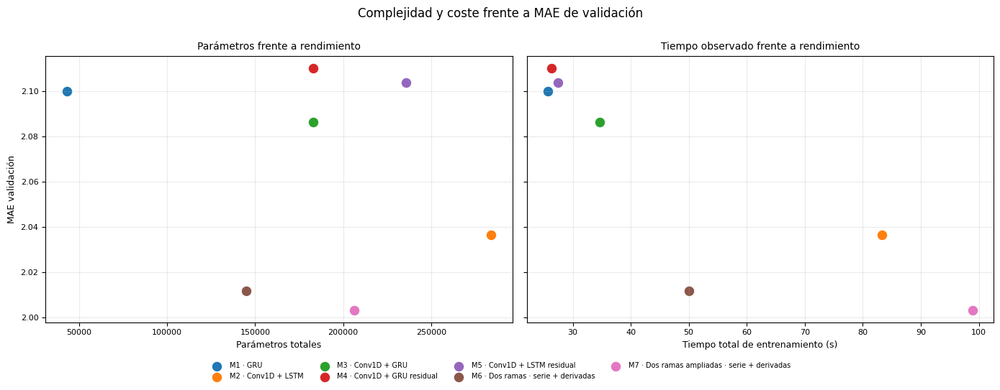

In [49]:
# Representación gráfica
grafica_complejidad = tabla_complejidad[
    tabla_complejidad['modelo'].isin(MULTIVARIATE_MODELS)
].merge(
    tabla_resultados[['modelo', 'val_mae']], on='modelo', how='left'
).set_index('modelo').loc[MULTIVARIATE_MODELS].reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for i, fila in grafica_complejidad.iterrows():
    model_id = f'M{i + 1}'

    label = f'{model_id} · {MODEL_LABELS.get(fila["modelo"], fila["modelo"])}'

    axes[0].scatter(fila['parametros'], fila['val_mae'], s=75, label=label)
    axes[1].scatter(fila['tiempo_s'], fila['val_mae'], s=75)

axes[0].set_xlabel('Parámetros totales', fontsize=9)
axes[0].set_ylabel('MAE validación', fontsize=9)
axes[0].set_title('Parámetros frente a rendimiento', fontsize=10)

axes[1].set_xlabel('Tiempo total de entrenamiento (s)', fontsize=9)
axes[1].set_title('Tiempo observado frente a rendimiento', fontsize=10)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(axis='both', labelsize=8)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc='lower center', bbox_to_anchor=(0.5, 0.1), ncol=4,
    frameon=False, fontsize=7
)

fig.suptitle('Complejidad y coste frente a MAE de validación', fontsize=12)

plt.tight_layout(rect=[0, 0.16, 1, 0.98])

plt.savefig(IMAGES_DIR / '11_complejidad_rendimiento.png', dpi=200, bbox_inches='tight')

plt.show()

### 6.2. Métricas por horizonte de predicción

Además de la comparación global, se analizan `MSE`, `RMSE` y `MAE` de forma independiente para `t+1`, `t+2` y `t+3`.

Esta descomposición permite comprobar si una arquitectura destaca en la predicción más inmediata o si mantiene un comportamiento más estable conforme aumenta la distancia temporal.

In [50]:
tabla_metricas_step = crear_tabla_metricas_step()

orden_modelos = tabla_resultados['modelo'].tolist()

metric_labels = {
    'mae': 'MAE',
    'rmse': 'RMSE',
    'mse': 'MSE'
}

tablas_metricas_step = {}

for metrica, titulo in metric_labels.items():

    tabla = crear_matriz_metricas_step(tabla_metricas_step, metrica, orden_modelos)

    tabla.index = [MODEL_LABELS.get(modelo, modelo) for modelo in tabla.index]

    tablas_metricas_step[metrica] = tabla

    tabla_display = tabla.style.format('{:.4f}').background_gradient(
        cmap='RdYlGn_r', axis=None
    ).highlight_min(axis=0, props='font-weight: bold;').set_caption(
        f'{titulo} por horizonte · menor es mejor'
    )

    display(tabla_display)

step,t+1,t+2,t+3
Dos ramas ampliadas · serie + derivadas,1.7048,1.9015,1.9433
Dos ramas · serie + derivadas,1.7140,1.8997,1.9624
Conv1D + LSTM,1.6948,1.9121,1.9702
Conv1D + GRU,1.7512,1.9385,1.9758
GRU,1.7928,1.9427,1.9801
Conv1D + LSTM residual,1.7339,1.9745,2.0208
Conv1D + GRU residual,1.7502,1.9588,2.0269


step,t+1,t+2,t+3
Dos ramas ampliadas · serie + derivadas,2.1678,2.4565,2.4946
Dos ramas · serie + derivadas,2.1764,2.4610,2.5232
Conv1D + LSTM,2.1521,2.4586,2.5115
Conv1D + GRU,2.2165,2.4722,2.5041
GRU,2.2623,2.4909,2.5407
Conv1D + LSTM residual,2.2163,2.5374,2.5863
Conv1D + GRU residual,2.2175,2.5425,2.6120


step,t+1,t+2,t+3
Dos ramas ampliadas · serie + derivadas,4.6996,6.0346,6.2230
Dos ramas · serie + derivadas,4.7367,6.0566,6.3663
Conv1D + LSTM,4.6315,6.0445,6.3078
Conv1D + GRU,4.9127,6.1117,6.2704
GRU,5.1181,6.2048,6.4552
Conv1D + LSTM residual,4.9122,6.4382,6.6888
Conv1D + GRU residual,4.9173,6.4646,6.8224


La comparación por horizonte confirma el aumento general del error conforme la predicción se aleja del último dato observado.

Conv1D + LSTM obtiene el menor `MAE` en `t+1`, con `1.6948`.

En `t+2`, la primera arquitectura de dos ramas obtiene el menor error (`1.8997`), prácticamente empatada con la versión ampliada (`1.9015`). En `t+3`, el Modelo 7 pasa a obtener el mejor resultado (`1.9433`).

Por tanto, la selección del Modelo 7 no procede de dominar todos los horizontes individualmente, sino de alcanzar el menor `MAE` global de validación y test manteniendo además un comportamiento competitivo y estable en los tres horizontes.

### 6.3. Comparación del MAE de validación y test

Para complementar la comparación global se representa conjuntamente el `MAE` obtenido por cada arquitectura en validación y test.

La validación constituye el criterio utilizado para seleccionar la configuración final, mientras que el conjunto de test permanece fuera de ese proceso y permite comprobar posteriormente su comportamiento sobre un tramo temporal no utilizado durante el entrenamiento ni durante la selección.

La comparación visual entre ambos errores también permite detectar diferencias relevantes entre los distintos periodos de la serie.

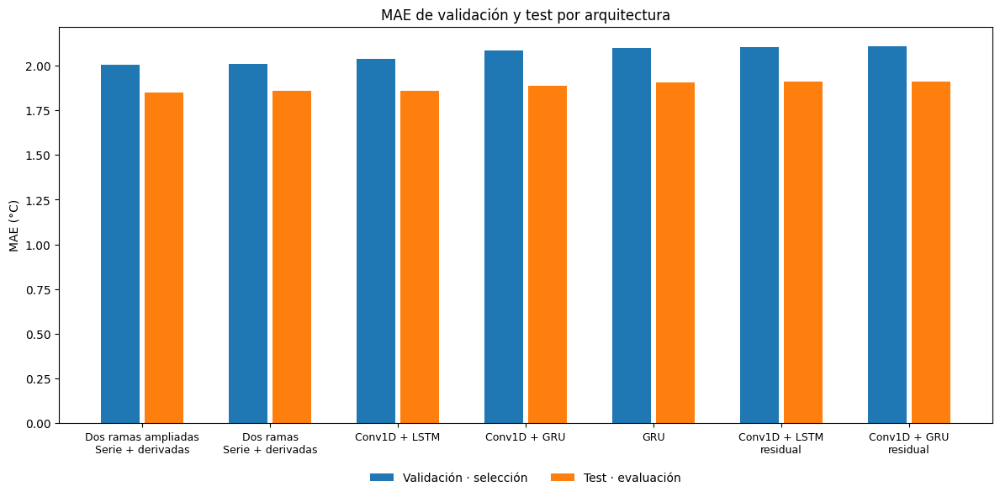

Dos ramas ampliadas · serie + derivadas: Val MAE = 2.0034 | Test MAE = 1.8499
Dos ramas · serie + derivadas : Val MAE = 2.0118 | Test MAE = 1.8587
Conv1D + LSTM                 : Val MAE = 2.0364 | Test MAE = 1.8590
Conv1D + GRU                  : Val MAE = 2.0863 | Test MAE = 1.8885
GRU                           : Val MAE = 2.0998 | Test MAE = 1.9052
Conv1D + LSTM residual        : Val MAE = 2.1036 | Test MAE = 1.9097
Conv1D + GRU residual         : Val MAE = 2.1102 | Test MAE = 1.9119


In [51]:
x = np.arange(len(tabla_resultados))
width = 0.3

plt.figure(figsize=(12, 6))

plt.bar(x - 0.17, tabla_resultados['val_mae'], width, label='Validación · selección')

plt.bar(x + 0.17, tabla_resultados['test_mae'], width, label='Test · evaluación')

etiquetas = [
    PLOT_LABELS.get(modelo, modelo) for modelo in tabla_resultados['modelo']
]

plt.xticks(ticks=x, labels=etiquetas, rotation=0, ha='center', fontsize=9)

plt.ylabel('MAE (°C)')
plt.title('MAE de validación y test por arquitectura')

plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()

plt.savefig(IMAGES_DIR / '12_comparacion_mae_modelos.png', dpi=200, bbox_inches='tight')

plt.show()

for _, fila in tabla_resultados.iterrows():
    nombre_visible = MODEL_LABELS.get(fila['modelo'], fila['modelo'])

    print(
        '{:30s}: Val MAE = {:.4f} | Test MAE = {:.4f}'.format(
            nombre_visible, fila['val_mae'], fila['test_mae']
        )
    )

La gráfica sitúa a **Dos ramas ampliadas · serie + derivadas** como la arquitectura con menor `MAE` de validación (`2.0034`).

En test vuelve a obtener el menor error global (`1.8498`), seguido por Conv1D + LSTM (`1.8590`) y la primera arquitectura de dos ramas (`1.8767`).

El hecho de que el error de test sea inferior al de validación no implica por sí solo ausencia de sobreajuste. Ambos conjuntos corresponden a tramos temporales distintos y pueden presentar diferente dificultad.

La arquitectura se selecciona exclusivamente mediante el `MAE` de validación; test se utiliza posteriormente para caracterizar su capacidad de generalización.

### 6.4. Análisis de generalización y sobreajuste

La comparación entre validación y test no permite observar directamente cómo evoluciona el aprendizaje durante las épocas.

Por ello se complementa con dos análisis: la relación entre el `MAE` de TRAIN y VALIDACIÓN en el checkpoint seleccionado y las curvas completas de aprendizaje de las siete arquitecturas multivariantes.

#### 6.4.1. Ranking de proximidad TRAIN–VALIDACIÓN

Como primera referencia se ordenan las arquitecturas según la distancia absoluta entre el `MAE` de TRAIN y VALIDACIÓN en la época correspondiente al menor `val_loss`.

Este ranking mide únicamente la proximidad entre ambas métricas y no constituye por sí mismo un ranking de sobreajuste.

Un `Gap MAE` positivo indica que el error de validación es superior al de entrenamiento y puede ser compatible con una pérdida de generalización. En cambio, un valor negativo indica que el error registrado durante TRAIN es superior al de validación.

Este segundo comportamiento aparece especialmente en las arquitecturas de dos ramas. Ambas incorporan una regularización mediante `Dropout` más intensa que las configuraciones más sencillas. Dado que estas capas permanecen activas durante TRAIN y se desactivan durante validación, la diferencia negativa observada no debe interpretarse como evidencia de sobreajuste.

Por ello, la evaluación del posible sobreajuste se complementa posteriormente con las curvas completas de aprendizaje, observando si después de la mejor época el error de TRAIN continúa disminuyendo mientras VALIDACIÓN comienza a deteriorarse.

In [52]:
tabla_generalizacion = crear_tabla_generalizacion()

tabla_generalizacion['Modelo'] = tabla_generalizacion['modelo'].map(MODEL_LABELS)

tabla_generalizacion_display = tabla_generalizacion[[
    'Modelo', 'best_epoch', 'epochs', 'train_mae', 'val_mae', 'gap_mae', 'gap_abs_mae'
]].rename(columns={
    'best_epoch': 'Mejor época', 'epochs': 'Épocas totales', 'train_mae': 'MAE TRAIN',
    'val_mae': 'MAE validación', 'gap_mae': 'Gap MAE', 'gap_abs_mae': '|Gap MAE|'
}).style.format({
    'MAE TRAIN': '{:.4f}', 'MAE validación': '{:.4f}', 'Gap MAE': '{:.4f}', '|Gap MAE|': '{:.4f}'
})

display(tabla_generalizacion_display)

,Modelo,Mejor época,Épocas totales,MAE TRAIN,MAE validación,Gap MAE,|Gap MAE|
Ranking proximidad,,,,,,,
1,Conv1D + LSTM residual,3,13,2.1072,2.1036,-0.0036,0.0036
2,Conv1D + GRU residual,3,13,2.0984,2.1102,0.0117,0.0117
3,Conv1D + LSTM,25,35,2.0645,2.0364,-0.0280,0.0280
4,GRU,13,23,2.0681,2.0998,0.0318,0.0318
5,Conv1D + GRU,8,18,2.0435,2.0863,0.0428,0.0428
6,Dos ramas ampliadas · serie + derivadas,13,23,2.0988,2.0034,-0.0954,0.0954
7,Dos ramas · serie + derivadas,4,14,2.1610,2.0118,-0.1493,0.1493


El ranking de proximidad sitúa en primer lugar a Conv1D + LSTM residual, seguido de Conv1D + GRU residual y Conv1D + LSTM. Sus diferencias absolutas entre TRAIN y VALIDACIÓN son reducidas.

Las arquitecturas de dos ramas ocupan las últimas posiciones del ranking, pero en ambos casos el `Gap MAE` es negativo: el error registrado durante TRAIN es superior al de VALIDACIÓN. Este comportamiento no corresponde al patrón clásico de sobreajuste y es coherente con la mayor presencia de `Dropout`, activo durante TRAIN y desactivado durante la evaluación.

El Modelo 6 alcanza su mejor checkpoint en la época 4 y finaliza en la 14, mientras que el Modelo 7 alcanza su mejor checkpoint en la época 13 y finaliza en la 23. En ambos casos las diez épocas posteriores corresponden a la paciencia configurada en `EarlyStopping`.

Por tanto, la separación posterior observada en las curvas queda controlada por el checkpoint y no justifica modificar nuevamente el `learning_rate`, el `Dropout` o la arquitectura.

#### 6.4.2. Curvas de aprendizaje

Para complementar el ranking anterior se representa la evolución del `MAE` de TRAIN y VALIDACIÓN de las siete arquitecturas multivariantes.

La línea vertical identifica en cada caso la época correspondiente al menor `val_loss`, es decir, el checkpoint posteriormente utilizado para la evaluación.

Estas curvas permiten comprobar si la validación continúa mejorando junto con el entrenamiento o si comienza a deteriorarse mientras el error de TRAIN sigue descendiendo.

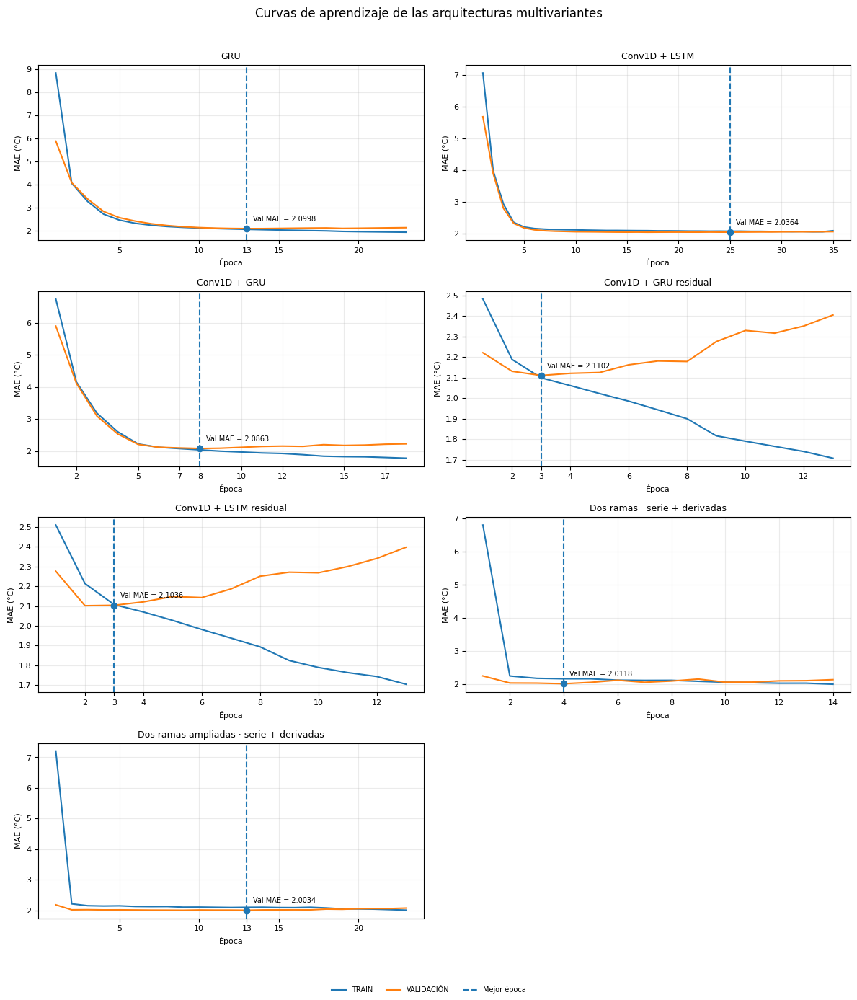

In [53]:
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

axes = axes.reshape(-1)

for ax, model_name in zip(axes, MULTIVARIATE_MODELS):
    history = histories[model_name].history

    best_idx = int(np.argmin(history['val_loss']))

    best_epoch = best_idx + 1

    checkpoint_val_mae = history['val_mae'][best_idx]

    epochs_axis = np.arange(1, len(history['mae']) + 1)

    ax.plot(epochs_axis, history['mae'], label='TRAIN')
    ax.plot(epochs_axis, history['val_mae'], label='VALIDACIÓN')

    ax.axvline(best_epoch, linestyle='--', label='Mejor época')

    ax.scatter(best_epoch, checkpoint_val_mae, zorder=3)

    ax.annotate(
        f'Val MAE = {checkpoint_val_mae:.4f}', xy=(best_epoch, checkpoint_val_mae), xytext=(6, 6),
        textcoords='offset points', fontsize=7, ha='left', va='bottom'
    )

    ax.set_title(MODEL_LABELS[model_name], fontsize=9)

    ax.set_xlabel('Época', fontsize=8)
    ax.set_ylabel('MAE (°C)', fontsize=8)

    base_ticks = [int(tick) for tick in ax.get_xticks() if (tick >= 1 and tick <= len(epochs_axis))]

    ax.set_xticks(sorted(set(base_ticks + [best_epoch])))

    ax.tick_params(axis='both', labelsize=8)
    ax.grid(alpha=0.25)

for ax in axes[len(MULTIVARIATE_MODELS):]:
    ax.axis('off')

handles, labels = (axes[0].get_legend_handles_labels())

fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=7)

fig.suptitle('Curvas de aprendizaje de las arquitecturas multivariantes', fontsize=12)

plt.tight_layout(rect=[0, 0.04, 1, 0.97])

plt.savefig(IMAGES_DIR / '13_curvas_aprendizaje_modelos.png', dpi=200, bbox_inches='tight')

plt.show()

### 6.5. Evolución gráfica del MAE por horizonte

A partir de las métricas anteriores se representa únicamente la evolución del `MAE` entre `t+1`, `t+2` y `t+3`.

La visualización permite comparar de forma directa cómo aumenta el error de cada arquitectura conforme la predicción se aleja del último dato observado.

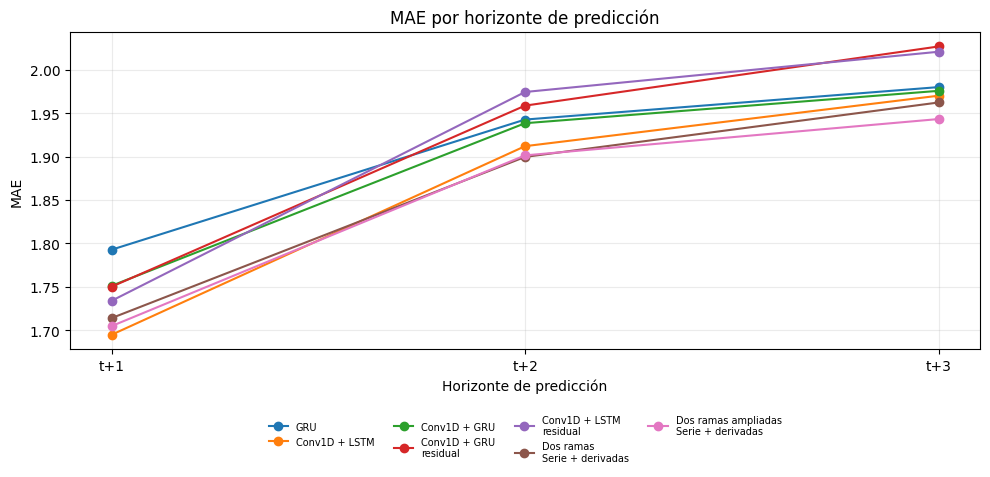

In [54]:
plt.figure(figsize=(10, 5))

for model_name in tabla_metricas_step['modelo'].unique():

    model_data = tabla_metricas_step[tabla_metricas_step['modelo'] == model_name]

    plt.plot(
        model_data['step'], model_data['mae'], marker='o',
        label=PLOT_LABELS.get(model_name, model_name)
    )

plt.xlabel('Horizonte de predicción')
plt.ylabel('MAE')
plt.title('MAE por horizonte de predicción')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False, fontsize=7)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(IMAGES_DIR / '14_mae_por_horizonte.png', dpi=200, bbox_inches='tight')

plt.show()

La gráfica muestra un incremento general del error desde `t+1` hasta `t+3`, comportamiento coherente con el aumento de incertidumbre asociado a horizontes temporales más alejados.

Conv1D + LSTM presenta el menor error en el primer horizonte. En `t+2`, la primera arquitectura de dos ramas obtiene una ventaja mínima respecto al Modelo 7, mientras que en `t+3` la arquitectura ampliada consigue el menor error.

Las variantes residuales muestran una degradación más acusada en los horizontes posteriores. En cambio, las arquitecturas de dos ramas mantienen una evolución más favorable conforme aumenta la distancia temporal.

Este comportamiento contribuye a que el Modelo 7 alcance el mejor rendimiento global aun sin obtener el mínimo error individual en todos los horizontes.

### 6.6. Predicción frente a valores reales

Además de las métricas numéricas, se representan las predicciones frente a los valores reales para cada modelo y cada horizonte.

Estas gráficas permiten comprobar visualmente si las arquitecturas siguen adecuadamente la evolución de la temperatura, si presentan desviaciones sistemáticas o si tienden a suavizar los valores extremos.

Este análisis complementa las métricas agregadas mostrando el comportamiento temporal de cada configuración sobre ejemplos consecutivos del conjunto de test.

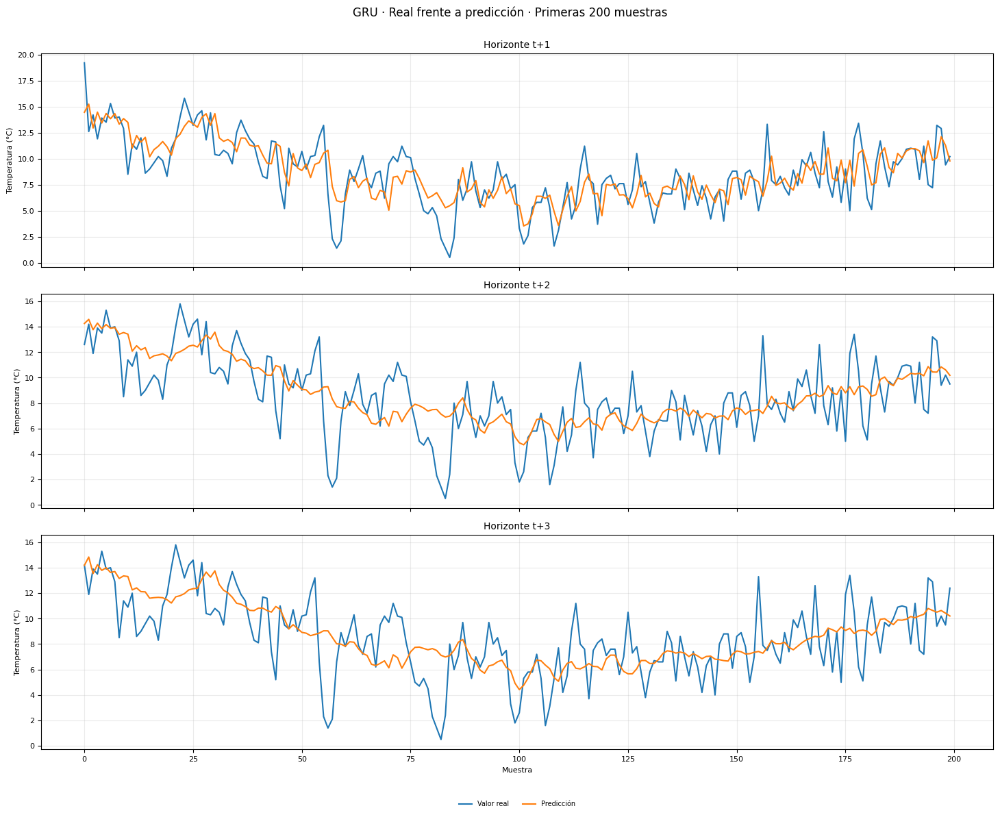

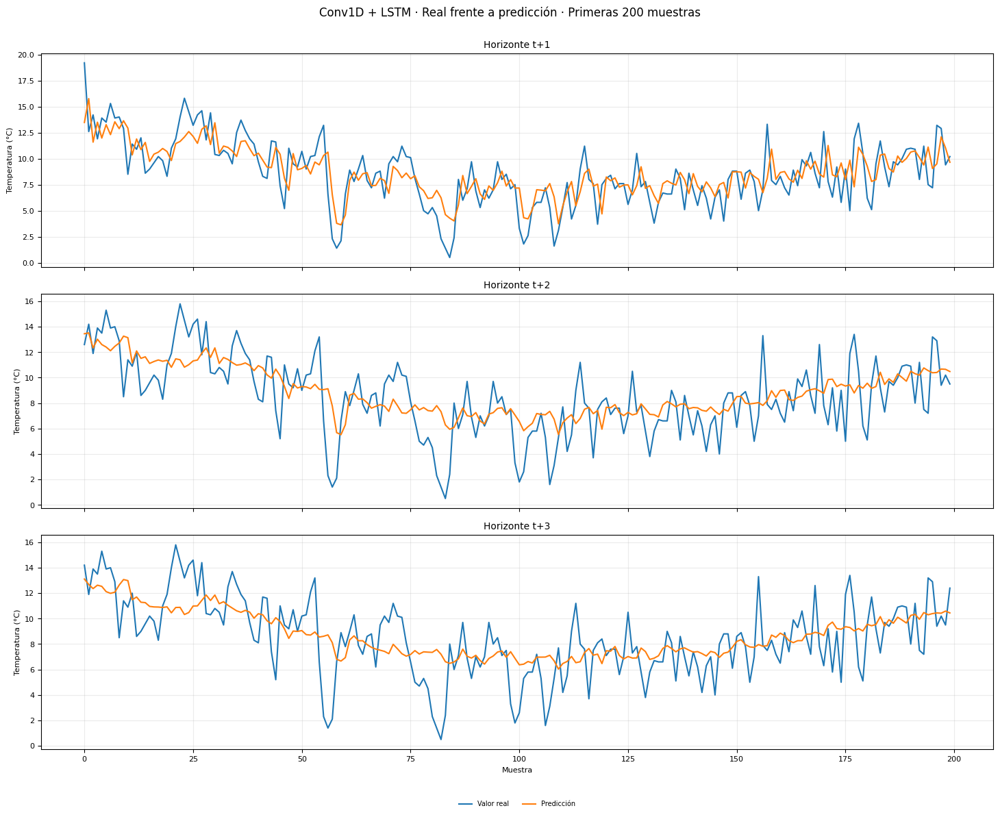

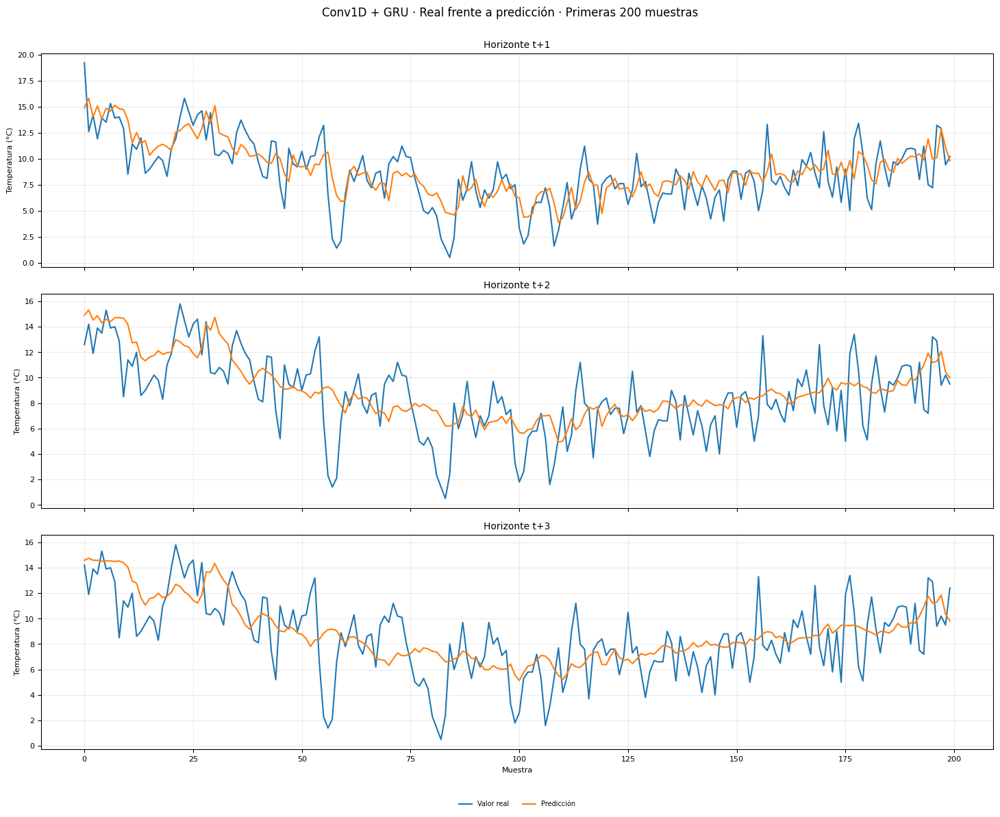

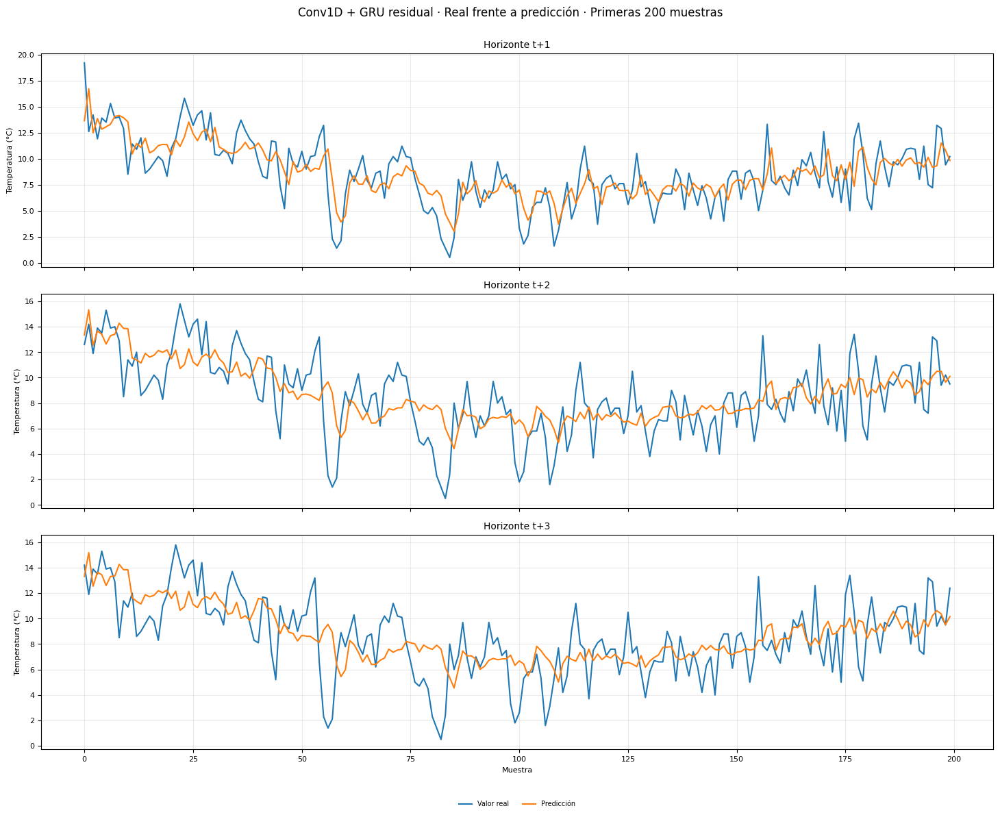

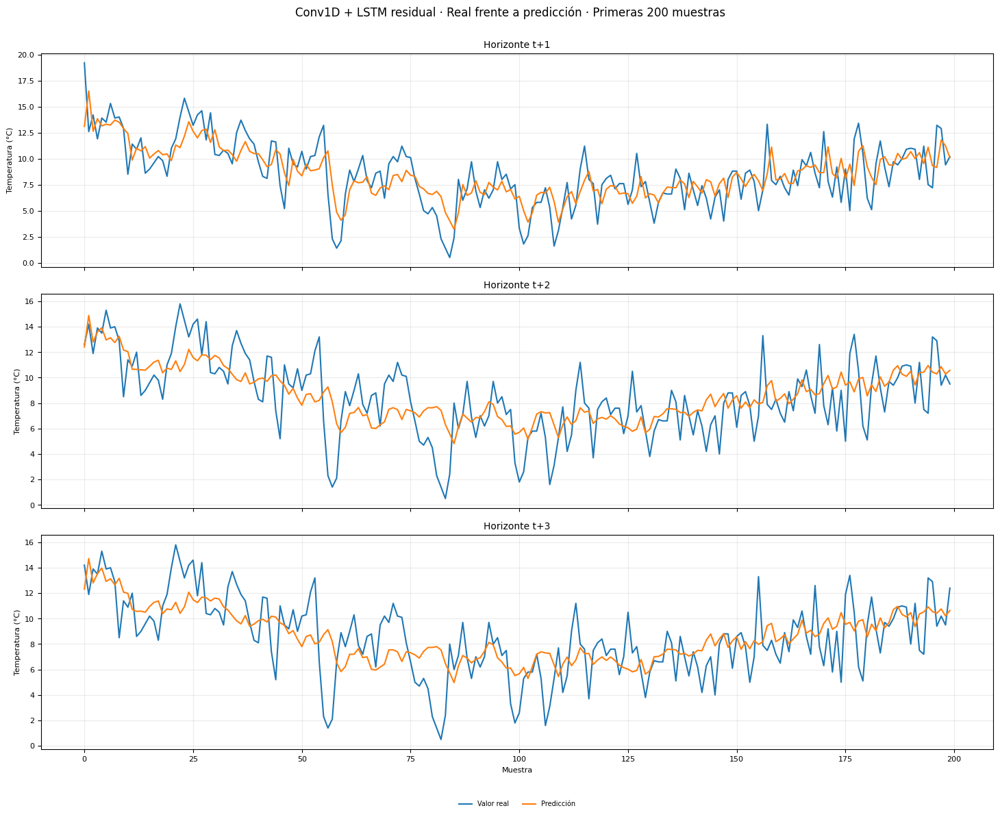

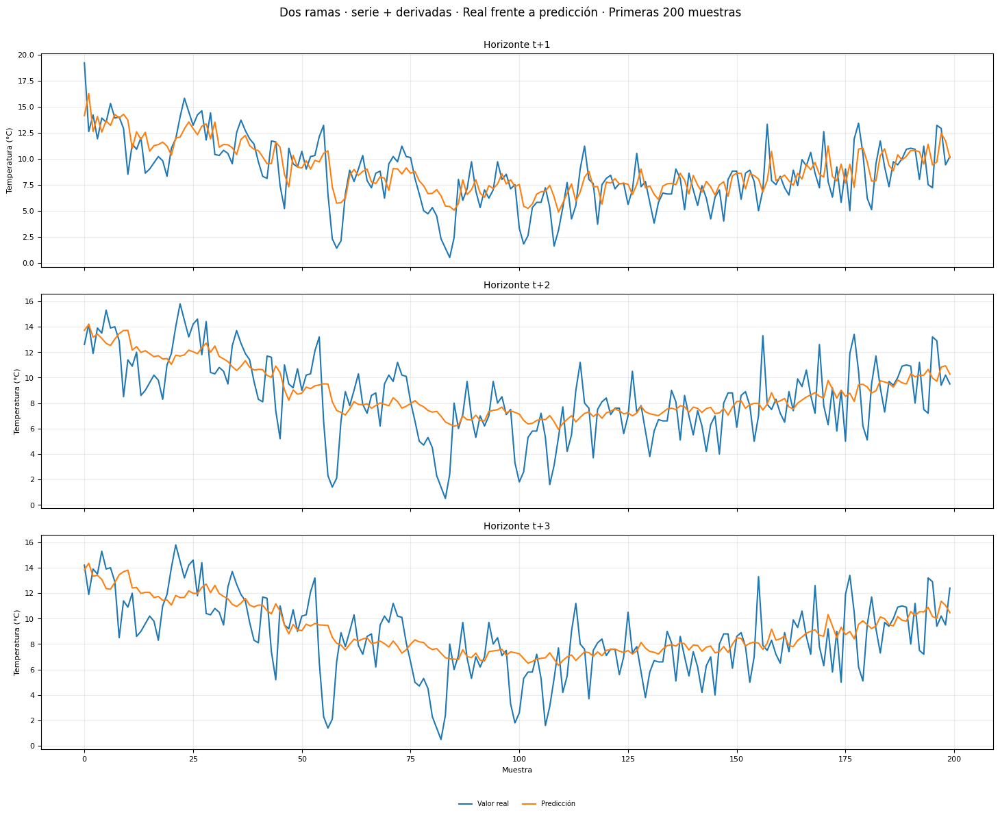

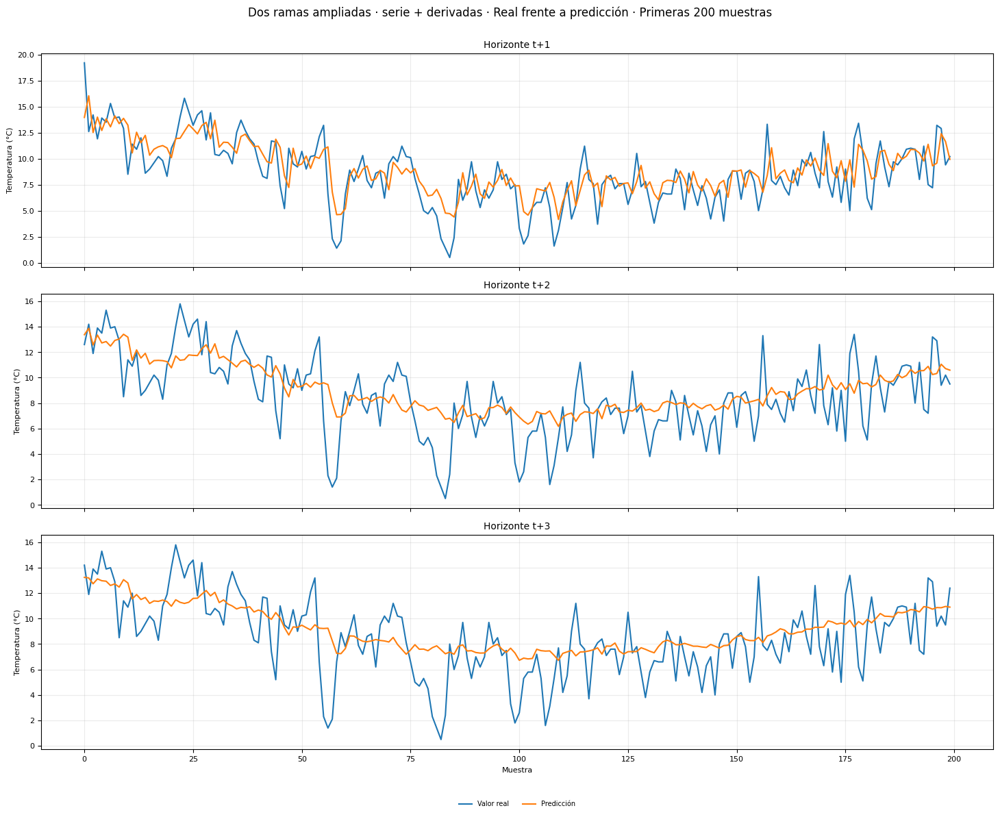

In [55]:
for model_name in MULTIVARIATE_MODELS:
    if model_name in predictions:
        plot_real_vs_prediction(model_name, y_test, n=200)

Las gráficas de valores reales frente a predichos muestran que las distintas arquitecturas reproducen razonablemente la dinámica general de la temperatura, aunque presentan cierta suavización de los valores extremos.

Este comportamiento es coherente con el uso de `MSE` como función de pérdida, que penaliza especialmente los errores de mayor magnitud y favorece predicciones más próximas a la tendencia central.

La arquitectura de dos ramas ampliada, seleccionada cuantitativamente mediante validación, mantiene visualmente una evolución coherente en los tres horizontes. Como ocurre en el resto de modelos, las mayores diferencias aparecen cuando la serie experimenta cambios bruscos respecto al historial reciente.

### 6.7. Análisis detallado del modelo seleccionado

Una vez seleccionada la arquitectura mediante validación, se estudian sus predicciones a nivel de muestras concretas.

El análisis se realiza mediante dos representaciones complementarias: una visualización multi-step que combina la ventana histórica con los tres horizontes futuros y una tabla temporal con los valores reales, predichos y sus fechas asociadas.

#### 6.7.1. Visualización de predicciones individuales

La arquitectura seleccionada se analiza utilizando exactamente las mismas fechas empleadas en el modelo univariante de referencia.

Debido a que ambos problemas utilizan distintos valores de `past`, el número interno de muestra puede ser diferente. Sin embargo, la fecha asociada a `t+2` es la misma en ambos casos, por lo que la comparación corresponde al mismo instante temporal.

En el modelo seleccionado se muestran simultáneamente `t+1`, `t+2` y `t+3`, mientras que la ventana histórica aumenta de 5 a 14 días y la entrada pasa de una única serie a 26 variables.

Modelo seleccionado: Dos ramas ampliadas · serie + derivadas


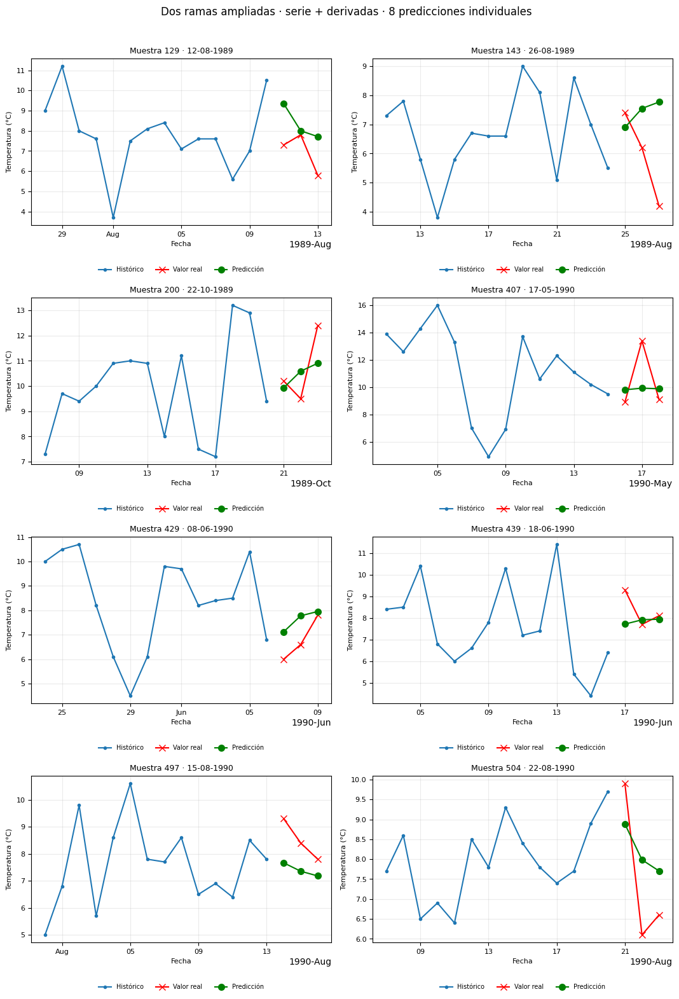

In [56]:
selected_model_name, selected_model = obtener_modelo_seleccionado()

indices_comparacion = plot_individual_predictions(
    selected_model_name, X_test, y_test, fechas_comparacion,
    save_path=(IMAGES_DIR / '15_predicciones_individuales_mejor_modelo.png')
)

Las visualizaciones multi-step corresponden al modelo **Dos ramas ampliadas · serie + derivadas**, seleccionado previamente mediante el `MAE` de validación.

En los ejemplos donde la temperatura mantiene una evolución relativamente suave, las predicciones siguen adecuadamente la dirección de los tres valores futuros. Las mayores desviaciones aparecen ante cambios bruscos respecto a la ventana histórica.

Este comportamiento coincide con el análisis cuantitativo: el modelo mantiene un error reducido en los tres horizontes, obtiene el menor `MAE` global y alcanza el mejor resultado en `t+3`, mientras que en `t+2` queda prácticamente empatado con la primera arquitectura de dos ramas.

#### 6.7.2. Tabla de predicciones

Las mismas muestras utilizadas en la visualización anterior se presentan también en formato tabular, permitiendo relacionar directamente cada gráfico con sus valores numéricos.

Para cada muestra se muestra la fecha de inicio de la ventana histórica y, en cada horizonte de predicción, el valor real, la predicción y su error absoluto.

La tabla completa conserva además las fechas objetivo de `t+1`, `t+2` y `t+3` para su posterior exportación y análisis externo.

In [57]:
# Predicciones del modelo seleccionado con fechas asociadas
selected_predictions_df = crear_tabla_predicciones(selected_model_name, y_test, past)

print('Modelo seleccionado:', MODEL_LABELS.get(selected_model_name, selected_model_name))
print('Predicciones exportadas:', len(selected_predictions_df))

detalles_predicciones = selected_predictions_df.iloc[indices_comparacion]

detalles_predicciones_display = detalles_predicciones[[
    'sample', 'start_date', 'real_t1', 'pred_t1', 'abs_error_t1', 'real_t2', 'pred_t2',
    'abs_error_t2', 'real_t3', 'pred_t3', 'abs_error_t3'
]].rename(columns={
    'sample': 'Muestra',
    'start_date': 'Fecha inicio',
    'real_t1': 'Real t+1',
    'pred_t1': 'Pred. t+1',
    'abs_error_t1': 'Error abs. t+1',
    'real_t2': 'Real t+2',
    'pred_t2': 'Pred. t+2',
    'abs_error_t2': 'Error abs. t+2',
    'real_t3': 'Real t+3',
    'pred_t3': 'Pred. t+3',
    'abs_error_t3': 'Error abs. t+3'
}).style.hide(axis='index').format({
    'Real t+1': '{:.2f}', 'Pred. t+1': '{:.2f}', 'Error abs. t+1': '{:.2f}', 'Real t+2': '{:.2f}',
    'Pred. t+2': '{:.2f}', 'Error abs. t+2': '{:.2f}', 'Real t+3': '{:.2f}', 'Pred. t+3': '{:.2f}',
    'Error abs. t+3': '{:.2f}'
})

display(detalles_predicciones_display)

Modelo seleccionado: Dos ramas ampliadas · serie + derivadas
Predicciones exportadas: 634


Muestra,Fecha inicio,Real t+1,Pred. t+1,Error abs. t+1,Real t+2,Pred. t+2,Error abs. t+2,Real t+3,Pred. t+3,Error abs. t+3
129,1989-07-28 00:00:00,7.30,9.35,2.05,7.80,8.00,0.20,5.80,7.71,1.91
143,1989-08-11 00:00:00,7.40,6.90,0.50,6.20,7.55,1.35,4.20,7.77,3.57
200,1989-10-07 00:00:00,10.20,9.93,0.27,9.50,10.59,1.09,12.40,10.90,1.50
407,1990-05-02 00:00:00,8.90,9.81,0.91,13.40,9.92,3.48,9.10,9.88,0.78
429,1990-05-24 00:00:00,6.00,7.12,1.12,6.60,7.78,1.18,7.80,7.95,0.15
439,1990-06-03 00:00:00,9.30,7.72,1.58,7.70,7.91,0.21,8.10,7.94,0.16
497,1990-07-31 00:00:00,9.30,7.67,1.63,8.40,7.36,1.04,7.80,7.18,0.62
504,1990-08-07 00:00:00,9.90,8.88,1.02,6.10,7.99,1.89,6.60,7.71,1.11


## 7. Exportación de resultados

Los principales resultados del experimento se exportan en formatos tabulares para facilitar su reutilización, comparación y análisis externo.

Se generan siete archivos:

- `comparacion_modelos.csv`, con las métricas globales de las siete arquitecturas multivariantes;
- `evolucion_t2.csv`, con la comparación del horizonte común `t+2` entre la referencia univariante y los modelos multivariantes;
- `complejidad_modelos.csv`, con la estructura arquitectónica, parámetros, épocas y coste de entrenamiento;
- `metricas_por_horizonte.csv`, con `MSE`, `RMSE` y `MAE` para `t+1`, `t+2` y `t+3`;
- `generalizacion_modelos.csv`, con las métricas TRAIN–VALIDACIÓN utilizadas para analizar estabilidad y posible sobreajuste;
- `diagnostico_union_modelo_7.csv`, con el rendimiento independiente de las ramas y el análisis de la ponderación `α`;
- `predicciones_modelo_seleccionado.csv`, con las predicciones detalladas de la arquitectura finalmente seleccionada.

In [58]:
tabla_resultados.to_csv(
    OUTPUTS_DIR / 'comparacion_modelos.csv', index=True, index_label='Ranking', float_format='%.6f'
)

tabla_evolucion_t2.to_csv(OUTPUTS_DIR / 'evolucion_t2.csv', index=False, float_format='%.6f')

tabla_complejidad.to_csv(OUTPUTS_DIR / 'complejidad_modelos.csv', index=False, float_format='%.6f')

tabla_metricas_step.to_csv(
    OUTPUTS_DIR / 'metricas_por_horizonte.csv', index=False, float_format='%.6f'
)

tabla_generalizacion.to_csv(
    OUTPUTS_DIR / 'generalizacion_modelos.csv', index=True, index_label='Ranking proximidad',
    float_format='%.6f'
)

diagnostico_union_7.to_csv(
    OUTPUTS_DIR / 'diagnostico_union_modelo_7.csv', index=False, float_format='%.6f'
)

selected_predictions_df.to_csv(
    OUTPUTS_DIR / 'predicciones_modelo_seleccionado.csv', index=False, float_format='%.6f',
    date_format='%Y-%m-%d'
)

print('Resultados exportados en:', OUTPUTS_DIR)

Resultados exportados en: /mnt/c/Portfolio/RNN/02_WORKING/outputs


## 8. Conclusiones

El proyecto parte de un modelo GRU univariante utilizado como referencia y evoluciona hacia un problema multivariante y multi-step basado en 26 variables, un `past` de 14 días y la predicción simultánea de `t+1`, `t+2` y `t+3`.

La comparación del horizonte de predicción común `t+2` muestra una evolución favorable desde el modelo univariante, cuyo `MAE` es `2.0662`, hasta las configuraciones multivariantes. La arquitectura final alcanza `1.9015` en ese mismo punto, una reducción aproximada del **8 %**. Esta diferencia describe la evolución conjunta del planteamiento y no puede atribuirse exclusivamente al aumento del número de variables, ya que también cambian el `past` y la formulación de la salida.

Dentro del escenario multivariante se comparan siete arquitecturas. Los modelos híbridos Conv1D + LSTM y Conv1D + GRU mejoran la referencia GRU y muestran que la combinación de extracción convolucional de patrones locales y modelado recurrente resulta adecuada para este problema. Las dos variantes residuales evaluadas no aportan una mejora global y presentan una degradación más acusada en los horizontes de predicción posteriores.

Las arquitecturas de dos ramas introducen una estrategia diferente al procesar por separado la serie original de temperatura y las variables temporales y estadísticas derivadas. La primera configuración consigue el segundo mejor `MAE` de validación (`2.0118`), mientras que la versión ampliada reduce este valor hasta `2.0034`.

Por tanto, **Dos ramas ampliadas · serie + derivadas queda establecida como la configuración final seleccionada mediante validación**. En test obtiene un `MSE` de `5.6524`, un `RMSE` de `2.3775` y un `MAE` de `1.8499`, también el menor error global entre las configuraciones evaluadas.

El análisis por horizonte de predicción muestra que Conv1D + LSTM obtiene el menor error en `t+1`, la primera arquitectura de dos ramas consigue una ventaja mínima en `t+2` (`1.8997` frente a `1.9015`) y la arquitectura seleccionada alcanza el mejor resultado en `t+3`.

Por tanto, la selección del Modelo 7 no depende de dominar cada horizonte individualmente, sino de obtener el menor `MAE` global de validación y test manteniendo un rendimiento competitivo en los tres puntos de predicción.

El análisis interno de las dos ramas muestra además que el peso `α` modifica la contribución relativa de la serie original y de las variables derivadas según cada horizonte de predicción. La comparación con ponderaciones fijas sitúa los valores aprendidos en regiones coherentes con las combinaciones que minimizan el error de validación, aunque la ponderación adaptativa no supera al mejor peso fijo en todos los pasos.

El análisis de complejidad confirma además que el mejor rendimiento no procede simplemente de aumentar el número de parámetros. La arquitectura seleccionada utiliza menos parámetros que Conv1D + LSTM y, al mismo tiempo, obtiene el menor `MAE` de validación.

En conjunto, el proyecto muestra una evolución desde una referencia recurrente sencilla hasta una arquitectura multi-step con representaciones complementarias y unión ponderada adaptativa, manteniendo una separación temporal estricta entre TRAIN, VALIDACIÓN y TEST y reservando este último exclusivamente para la evaluación final.